# Hospital Readmission Risk Prediction Using MLP

## CBIM Problem Canvas

### 1. Situation (S)

Hospitals face challenges in managing patients who return for another hospital admission shortly after discharge. Early readmissions can increase healthcare costs, contribute to hospital resource utilization, and indicate that patients may require additional post-discharge support.

The Diabetes 130-US Hospitals Dataset contains 101,766 hospital encounter records collected from 130 US hospitals between 1999 and 2008. The dataset includes patient demographics, medical conditions, medications, hospital encounter information, and readmission outcomes.

Hospital management wants to explore whether historical patient encounter data can support the identification of patients who are at higher risk of readmission within 30 days.

### 2. Complication (C)

Hospitals may not always be able to identify patients who require additional follow-up support before discharge. Limited healthcare resources, complex patient conditions, and the need to prioritize discharge planning can make it challenging to determine which patients may benefit most from additional attention.

The provided dataset also presents important analytical challenges, including substantial missing values, categorical variables, and an imbalanced readmission target.

The hospital needs to investigate whether a deep learning model can identify patterns associated with early readmission while maintaining reliable predictions and avoiding data leakage.

A particularly important concern is the possibility of incorrectly predicting that a patient is not at risk when the patient is actually readmitted within 30 days. Such false-negative predictions could result in high-risk patients not receiving additional follow-up support.

### 3. Question (Q)

Using historical hospital encounter data from the Diabetes 130-US Hospitals Dataset, how can a Multi-Layer Perceptron (MLP) model predict whether a patient will be readmitted within 30 days of discharge?

How can the model be developed and evaluated using TensorFlow/Keras while addressing missing values, class imbalance, data leakage, and model generalization?

Which evaluation metrics and decision thresholds should be considered to balance prediction reliability, identification of high-risk patients, and practical hospital follow-up planning?

How can the model's predictions and error analysis support hospital management in prioritizing additional discharge planning and post-discharge care?

### 4. SSOT (Single Source of Truth)

The provided `diabetic_data.csv` is the primary source of truth for this analysis. It contains 101,766 hospital encounter records and 50 columns, including patient identifiers, demographic information, medical conditions, medications, hospital encounter characteristics, and the original readmission outcome.

Each row represents a hospital encounter rather than necessarily a unique patient. The `patient_nbr` column identifies patients, while `encounter_id` identifies individual encounters.

The `readmitted` column records the original readmission outcome using three categories:

- `<30`: Readmitted within 30 days.
- `>30`: Readmitted after 30 days.
- `NO`: Not readmitted.

For this assignment, the target will be transformed into a binary classification variable:

- `<30` → `1`
- `>30` → `0`
- `NO` → `0`

The resulting target represents readmission within 30 days.

The provided `IDS_mapping.csv` will serve as a supplementary reference for interpreting the categorical identifiers associated with admission type, discharge disposition, and admission source.

The historical readmission outcome is the target variable for supervised deep learning. The model will learn patterns from historical encounters and estimate the probability of readmission within 30 days.

The dataset represents historical healthcare information from 1999–2008. Therefore, the model is an educational prototype and should not be considered a clinically validated decision-making system.

### 5. Success Definition

The Hospital Readmission Risk Prediction System will be evaluated against the following business and modelling criteria:

- **Business objective:** Identify patients who may benefit from additional discharge planning and post-discharge follow-up.
- **Target definition:** Correctly formulate readmission within 30 days as a binary classification problem using the assignment's specified target transformation.
- **Data preparation:** Investigate missing values, categorical variables, numerical features, class imbalance, and potential data leakage.
- **MLP architecture:** Implement a TensorFlow/Keras Sequential model with Dense hidden layers using ReLU activation and a single-neuron Sigmoid output layer.
- **Model compilation:** Use the Adam optimizer and Binary Crossentropy loss as required by the assignment.
- **Training experiments:** Investigate the effect of different epochs and batch sizes on training and validation performance.
- **Baseline evaluation:** Evaluate the model using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
- **Class imbalance assessment:** Investigate how the minority readmission class affects prediction performance, particularly recall.
- **Generalization:** Compare training and validation performance and evaluate the final model using an appropriately held-out test dataset.
- **Error analysis:** Examine false positives and false negatives to understand the model's prediction limitations.
- **Business impact:** Assess how missed high-risk patients could affect hospital follow-up planning and patient support.
- **Business recommendations:** Translate model findings into practical recommendations for prioritizing additional discharge planning and follow-up care.

The model's success will be determined by its ability to provide meaningful and reliable readmission risk estimates, rather than accuracy alone.

The model's predictions will serve as decision-support inputs for hospital staff, not as the sole basis for clinical decisions.

### 6. Primary Stakeholder

The **Hospital Discharge Planning Manager** is the primary stakeholder. This stakeholder is responsible for understanding readmission risk, prioritizing discharge planning resources, and evaluating whether the proposed prediction system could support improved post-discharge follow-up.

Other stakeholders include:

- Hospital management responsible for operational efficiency and healthcare resource allocation.
- Healthcare professionals involved in discharge planning and patient care.
- Patient follow-up coordinators responsible for post-discharge support.
- Patients and their families who may benefit from appropriate follow-up care.
- Hospital data and analytics teams responsible for developing and evaluating the prediction system.

The recommended system must balance readmission risk identification, prediction reliability, healthcare resource utilization, patient safety, and human clinical oversight.

----------------------------------------------------------------------------------------------------------------------------------

## 2. Translating the Business Problem into a Deep Learning Problem

### 2.1 Business Problem to Deep Learning Problem

The business problem is to identify hospital patients who may be readmitted within 30 days of discharge and who could benefit from additional follow-up care.

To address this problem, we will formulate a supervised deep learning task using historical hospital encounter records.

The objective is to train a Multi-Layer Perceptron (MLP) that learns patterns from patient demographics, medical conditions, hospital encounter characteristics, and other relevant information to predict the likelihood of readmission within 30 days.

### 2.2 Deep Learning Problem Definition

| Component | Description |
|---|---|
| Problem type | Supervised learning |
| Learning task | Binary classification |
| Industry | Healthcare |
| Prediction unit | Hospital encounter |
| Input | Patient and hospital encounter features |
| Target variable | Readmission within 30 days |
| Target column | `readmitted` |
| Model | Multi-Layer Perceptron (MLP) |
| Framework | TensorFlow/Keras |
| Output | Probability of readmission within 30 days |

### 2.3 Target Variable Definition

The original `readmitted` column contains three possible values:

- `<30`: Readmitted within 30 days.
- `>30`: Readmitted after 30 days.
- `NO`: Not readmitted.

As required by the assignment, the target will be transformed into a binary variable:

| Original value | Binary target | Interpretation |
|---|---:|---|
| `<30` | 1 | Readmitted within 30 days |
| `>30` | 0 | Not readmitted within 30 days |
| `NO` | 0 | Not readmitted within 30 days |

The positive class represents patients readmitted within 30 days.

The negative class combines patients readmitted after 30 days and patients who were not readmitted.

### 2.4 Input Features

The model will use relevant patient and hospital encounter characteristics as input features.

Potential feature categories include:

- Patient demographics.
- Medical conditions and diagnoses.
- Hospital encounter characteristics.
- Previous inpatient, outpatient, and emergency visits.
- Medication-related information.
- Laboratory-related information.
- Other relevant clinical and administrative variables.

The final input feature selection will be determined after data exploration, missing-value assessment, and data leakage investigation.

Patient identifiers and features that would not be available at the intended prediction time will be carefully evaluated before inclusion.

### 2.5 Model Output

The MLP model will contain a single-neuron output layer using Sigmoid activation.

The output will represent the estimated probability of readmission within 30 days.

The predicted probability will range between 0 and 1.

For example, a probability of 0.80 indicates that the model estimates an 80% probability of readmission within 30 days.

This probability is a model estimate and should not be interpreted as a confirmed clinical outcome.

### 2.6 Classification Decision

The predicted probability can be converted into a binary classification using a decision threshold.

For an initial threshold of 0.50:

- Probability ≥ 0.50 → Predicted readmission within 30 days.
- Probability < 0.50 → Predicted no readmission within 30 days.

The threshold of 0.50 will serve as an initial baseline. We will investigate threshold selection during model evaluation, considering class imbalance and the business impact of false-negative predictions.

### 2.7 Deep Learning Objective

The objective is to train an MLP that learns the relationship between patient encounter features and the binary readmission target.

The model will be trained using Binary Crossentropy loss and the Adam optimizer, as specified in the assignment.

Model performance will be evaluated using Accuracy, Precision, Recall, F1-score, and ROC-AUC.

Special attention will be given to Recall for the readmission class because false-negative predictions may cause potentially high-risk patients to be overlooked during follow-up planning.

### 2.8 Expected Outcome

The expected outcome is a trained MLP model capable of estimating the probability of readmission within 30 days for a hospital encounter.

The model will provide a foundation for analysing readmission risk patterns and supporting hospital follow-up planning.

Its predictions will be evaluated carefully before drawing business conclusions.

-----------------------------------------------------------------------------------------------------------------------

# 3. Data Understanding

In [1]:
# Loading dataset 

import pandas as pd
import numpy as np 

# Load the primary hospital dataset
df = pd.read_csv("diabetic_data.csv")

# Load the supplementary mapping dataset
mapping_df = pd.read_csv("IDS_mapping.csv")

df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [2]:
df.tail()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
101761,443847548,100162476,AfricanAmerican,Male,[70-80),?,1,3,7,3,...,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),?,1,4,5,5,...,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),?,1,1,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),?,2,3,7,10,...,No,Up,No,No,No,No,No,Ch,Yes,NO
101765,443867222,175429310,Caucasian,Male,[70-80),?,1,1,7,6,...,No,No,No,No,No,No,No,No,No,NO


In [3]:
# Dataset shape 

print("Hospital Dataset Shape:", df.shape)
print("Mapping Dataset Shape:", mapping_df.shape)

Hospital Dataset Shape: (101766, 50)
Mapping Dataset Shape: (67, 2)


In [4]:
# Dataset information 

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [5]:
# Display all column names 

print("Total Columns:", len(df.columns))

print("\nColumn Names:")
print(df.columns.tolist())

Total Columns: 50

Column Names:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']



### Understanding All Dataset Columns

The Diabetes 130-US Hospitals Dataset contains patient encounter information, demographic details, medical history, diagnosis information, medication details, and hospital utilization records.

The dataset contains **50 columns**, including the target variable `readmitted`.

Understanding each column is important for:
- Exploratory Data Analysis (EDA)
- Missing-value treatment
- Feature selection
- Data preprocessing
- Identifying potential data leakage

### 1. Patient and Encounter Identifiers

| Column | Description |
|---|---|
| `encounter_id` | Unique identifier assigned to each hospital encounter. |
| `patient_nbr` | Unique identifier assigned to each patient. A patient may have multiple encounters. |

**Note:** These columns identify patients and encounters. They should not automatically be used as predictive features because they may introduce data leakage or allow the model to memorize identifiers.

### 2. Patient Demographic Information

| Column | Description |
|---|---|
| `race` | Race is a demographic feature that represents the racial category recorded for a patient. (Eg:- Caucasian, AfricanAmerican, Asian, Hispanic, Other ) |
| `gender` | Gender recorded for the patient. |
| `age` | Patient's age represented as an age range rather than an exact age. |
| `weight` | Patient's recorded weight, represented using weight ranges. |

**Important:** The `age` and `weight` columns contain grouped categories rather than exact numerical measurements.

### 3. Hospital Admission and Discharge Information

| Column | Description |
|---|---|
| `admission_type_id` | Coded identifier representing the type of hospital admission. |
| `discharge_disposition_id` | Coded identifier representing the patient's discharge destination or disposition. |
| `admission_source_id` | Coded identifier representing the source through which the patient was admitted. |
| `time_in_hospital` | Number of days the patient stayed in the hospital. |

The three ID columns represent **categorical information encoded numerically**. Their values should not automatically be interpreted as continuous numerical measurements.

### 4. Medical Procedures, Laboratory Tests and Medication

| Column | Description |
|---|---|
| `num_lab_procedures` | Number of laboratory procedures performed during the encounter. |
| `num_procedures` | Number of procedures performed during the encounter, excluding laboratory procedures. |
| `num_medications` | Number of distinct medications administered or prescribed during the encounter. |

These columns provide information about the medical services and treatment intensity associated with a hospital encounter.

### 5. Previous Hospital Utilization

| Column | Description |
|---|---|
| `number_outpatient` | Number of outpatient visits recorded for the patient during the previous year. (Outpatient = Patient receives medical care without being admitted to stay overnight.) |
| `number_emergency` | Number of emergency visits recorded for the patient during the previous year. |
| `number_inpatient` | Number of inpatient visits recorded for the patient during the previous year. (Inpatient = Patient is formally admitted to the hospital for treatment or observation.) |

These features may help identify patients with frequent healthcare utilization and previous hospital visits.

### 6. Diagnosis Information

| Column | Description |
|---|---|
| `diag_1` | Primary diagnosis recorded for the hospital encounter. |
| `diag_2` | Secondary diagnosis recorded for the hospital encounter. |
| `diag_3` | Additional diagnosis recorded for the hospital encounter. |
| `number_diagnoses` | Total number of diagnoses recorded for the patient during the encounter. |

The diagnosis columns contain medical diagnosis codes rather than ordinary numerical measurements.

### 7. Diabetes and Laboratory Results

| Column | Description |
|---|---|
| `max_glu_serum` | Indicates the maximum glucose serum test result category recorded for the encounter. (`max_glu_serum` can reflect the short-term glucose level.) |
| `A1Cresult` | Indicates the HbA1c test result category, which provides information about blood glucose control. (`A1Cresult` helps indicate whether the patient's glucose has generally been elevated over the past few months.) |

These columns contain categorical representations of laboratory results.

### 8. Medication Change and Diabetes Medication

| Column | Description |
|---|---|
| `change` | Indicates whether a change was made to the patient's diabetes medication during the encounter. |
| `diabetesMed` | Indicates whether the patient was prescribed diabetes medication during the encounter. |

These features provide information about diabetes medication management.

### 9. Individual Diabetes Medication Columns

The following columns represent specific diabetes medications:

| Column | Description |
|---|---|
| `metformin` | Recorded status of metformin medication. |
| `repaglinide` | Recorded status of repaglinide medication. |
| `nateglinide` | Recorded status of nateglinide medication. |
| `chlorpropamide` | Recorded status of chlorpropamide medication. |
| `glimepiride` | Recorded status of glimepiride medication. |
| `glipizide` | Recorded status of glipizide medication. |
| `glyburide` | Recorded status of glyburide medication. |
| `tolbutamide` | Recorded status of tolbutamide medication. |
| `pioglitazone` | Recorded status of pioglitazone medication. |
| `rosiglitazone` | Recorded status of rosiglitazone medication. |
| `acarbose` | Recorded status of acarbose medication. |
| `miglitol` | Recorded status of miglitol medication. |
| `troglitazone` | Recorded status of troglitazone medication. |
| `tolazamide` | Recorded status of tolazamide medication. |
| `examide` | Recorded status of examide medication. |
| `citoglipton` | Recorded status of citoglipton medication. |
| `insulin` | Recorded status of insulin medication. |
| `glyburide-metformin` | Recorded status of the combination medication glyburide-metformin. |
| `glipizide-metformin` | Recorded status of the combination medication glipizide-metformin. |
| `glimepiride-pioglitazone` | Recorded status of the combination medication glimepiride-pioglitazone. |
| `metformin-rosiglitazone` | Recorded status of the combination medication metformin-rosiglitazone. |
| `metformin-pioglitazone` | Recorded status of the combination medication metformin-pioglitazone. |

These medication columns generally contain categorical values representing whether the medication was not prescribed, continued, changed, or otherwise recorded.

### 10. Target Variable

| Column | Description |
|---|---|
| `readmitted` | Indicates whether the patient was readmitted within 30 days, readmitted after 30 days, or not readmitted. |

Original target values:

- `<30` — Readmitted within 30 days.
- `>30` — Readmitted after 30 days.
- `NO` — Not readmitted.

For this assignment, the target will be converted into a **binary classification variable**:

- `1` — Readmitted within 30 days.
- `0` — Not readmitted within 30 days, including both `>30` and `NO`.


### 11. Healthcare Provider and Payment Information

| Column | Description |
|---|---|
| `medical_specialty` | Medical specialty or department associated with the physician treating the patient during the encounter. |
| `payer_code` | Coded identifier representing the healthcare payer responsible for payment or coverage. |

These columns provide additional information about the healthcare provider and payment arrangements.

Both are **categorical features** and contain significant missing values, which must be considered during preprocessing.


### Summary

The dataset contains different types of information:

- **Identifiers:** Patient and encounter IDs.
- **Demographic features:** Race, gender, age and weight.
- **Hospital encounter features:** Admission, discharge and length of stay.
- **Medical features:** Diagnoses, procedures and laboratory results.
- **Medication features:** Diabetes medications and medication changes.
- **Healthcare utilization features:** Previous outpatient, emergency and inpatient visits.
- **Target variable:** `readmitted`.

Understanding these columns will help us determine which features are appropriate for training the MLP model and which columns require removal, encoding, missing-value treatment or further investigation.


In [6]:
# Numerical descriptive statistics 

df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [7]:
# Inspect the Supplementary Mapping Dataset 

print("Mapping Dataset Shape:", mapping_df.shape)

print("\nMapping Dataset Columns:")
print(mapping_df.columns.tolist())

print("\nMapping Dataset Information:")
mapping_df.info()

Mapping Dataset Shape: (67, 2)

Mapping Dataset Columns:
['admission_type_id', 'description']

Mapping Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 67 entries, 0 to 66
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   admission_type_id  65 non-null     str  
 1   description        62 non-null     str  
dtypes: str(2)
memory usage: 3.4 KB


In [8]:
mapping_df

,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
...,...,...
62,22,Transfer from hospital inpt/same fac reslt in...
63,23,Born inside this hospital
64,24,Born outside this hospital
65,25,Transfer from Ambulatory Surgery Center


# 4. Data Quality Assessment

In [9]:
# Identify actual missing values 

# Count actual missing values
missing_count = df.isna().sum()

# Calculate missing-value percentage
missing_percentage = (missing_count / len(df)) * 100

# Combine the results
missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

# Display only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_summary

,Missing_Count,Missing_Percentage
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322



### Observation

- `max_glu_serum` has **96,420 missing values (94.75%)**, while `A1Cresult` has **84,748 missing values (83.28%)**.
- Both features have **very high missingness**, indicating that glucose and A1C tests were not recorded for most encounters.
- These missing values require careful treatment during preprocessing to avoid losing a significant amount of data or introducing bias.


In [10]:
# Investigate hidden missing-value representations 

import re

# Define common hidden missing-value representations
missing_pattern = r"^\s*(?:\?|nan|null|none)\s*$"

# Identify categorical and string columns
categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns

hidden_missing_summary = {}

for column in categorical_columns:

    values = df[column].astype("string")

    # Detect hidden missing values using Regex
    hidden_missing_mask = values.str.fullmatch(
        missing_pattern,
        case=False,
        na=False
    )

    missing_count = hidden_missing_mask.sum()

    if missing_count > 0:
        hidden_missing_summary[column] = missing_count

# Convert results into a DataFrame
hidden_missing_df = pd.DataFrame(
    hidden_missing_summary.items(),
    columns=["Column", "Hidden_Missing_Count"]
)

hidden_missing_df = hidden_missing_df.sort_values(
    by="Hidden_Missing_Count",
    ascending=False
).reset_index(drop=True)

hidden_missing_df


,Column,Hidden_Missing_Count
0,weight,98569
1,medical_specialty,49949
2,payer_code,40256
3,race,2273
4,diag_3,1423
5,diag_2,358
6,diag_1,21


### Observation

- `weight` contains the highest number of hidden missing values (**98,569**), followed by `medical_specialty` (**49,949**) and `payer_code` (**40,256**).
- `race`, `diag_3`, `diag_2`, and `diag_1` also contain hidden missing-value representations, with comparatively fewer occurrences.
- These findings confirm that missing data is represented using **both actual NaN values and hidden string tokens**.
- These columns require appropriate missing-value handling during preprocessing.


In [11]:
# Exact duplicate records

print("Exact Duplicate Rows:", df.duplicated().sum())

Exact Duplicate Rows: 0


In [12]:
# Encounter identifier uniqueness  

print("Total Encounters:", len(df))

print(
    "Unique Encounter IDs:",
    df["encounter_id"].nunique()
)

print(
    "Duplicate Encounter IDs:",
    df["encounter_id"].duplicated().sum()
)

Total Encounters: 101766
Unique Encounter IDs: 101766
Duplicate Encounter IDs: 0


### Patient-Level Assessment

In [13]:
# Patient identifier analysis 

print(
    "Total Encounter Records:",
    len(df)
)

print(
    "Unique Patients:",
    df["patient_nbr"].nunique()
)

print(
    "Patients with Multiple Encounters:",
    (df["patient_nbr"].value_counts() > 1).sum()
)

Total Encounter Records: 101766
Unique Patients: 71518
Patients with Multiple Encounters: 16773


In [14]:
# Verifying original target values 

print("Target Column:", "readmitted")

print("\nUnique Target Values:")
print(df["readmitted"].unique())

print("\nTarget Value Counts:")
print(df["readmitted"].value_counts(dropna=False))

print("\nMissing Target Values:")
print(df["readmitted"].isna().sum())

Target Column: readmitted

Unique Target Values:
<ArrowStringArray>
['NO', '>30', '<30']
Length: 3, dtype: str

Target Value Counts:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Missing Target Values:
0


In [15]:
# Inspect categorical feature values 

categorical_columns = df.select_dtypes(
    include=["object"]
).columns

for column in categorical_columns:

    print(f"\nColumn: {column}")

    print("Unique Categories:", df[column].nunique())

    print(df[column].value_counts(dropna=False).head(10))


Column: race
Unique Categories: 6
race
Caucasian          76099
AfricanAmerican    19210
?                   2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

Column: gender
Unique Categories: 3
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

Column: age
Unique Categories: 10
age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64

Column: weight
Unique Categories: 10
weight
?            98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
>200             3
Name: count, dtype: int64

Column: payer_code
Unique Categories: 18
payer_code
?     40256
MC    32439
HM     6274
SP     5007
BC     4655
MD     3532
CP     2

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_18716\2205337857.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


Unique Categories: 3
A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64

Column: metformin
Unique Categories: 4
metformin
No        81778
Steady    18346
Up         1067
Down        575
Name: count, dtype: int64

Column: repaglinide
Unique Categories: 4
repaglinide
No        100227
Steady      1384
Up           110
Down          45
Name: count, dtype: int64

Column: nateglinide
Unique Categories: 4
nateglinide
No        101063
Steady       668
Up            24
Down          11
Name: count, dtype: int64

Column: chlorpropamide
Unique Categories: 4
chlorpropamide
No        101680
Steady        79
Up             6
Down           1
Name: count, dtype: int64

Column: glimepiride
Unique Categories: 4
glimepiride
No        96575
Steady     4670
Up          327
Down        194
Name: count, dtype: int64

Column: acetohexamide
Unique Categories: 2
acetohexamide
No        101765
Steady         1
Name: count, dtype: int64

Column: glipizide
Unique Categorie

In [16]:
# Numerical feature summary 

numerical_columns = df.select_dtypes(
    include=["number"]
).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

print("\nNumerical Summary:")
display(df[numerical_columns].describe())

Numerical Columns:
['encounter_id', 'patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Numerical Summary:


,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


## Section 5 — Missing Values Visualization

In [17]:
# Missing-Value Summary

import pandas as pd
import numpy as np

# Define hidden missing-value representations
missing_pattern = r"^\s*(?:\?|nan|null|none)\s*$"

# Create a copy for missing-value analysis
missing_data = df.copy()

# Convert hidden missing values into actual NaN
for column in missing_data.select_dtypes(
    include=["object", "str"]
).columns:

    hidden_missing_mask = missing_data[column].astype(
        "string"
    ).str.fullmatch(
        missing_pattern,
        case=False,
        na=False
    )

    missing_data.loc[hidden_missing_mask, column] = np.nan

# Calculate missing-value counts
missing_count = missing_data.isnull().sum()

# Calculate missing-value percentages
missing_percentage = (
    missing_count / len(missing_data)
) * 100

# Create summary DataFrame
missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

# Keep only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_summary


,Missing_Count,Missing_Percentage
weight,98569,96.858479
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636


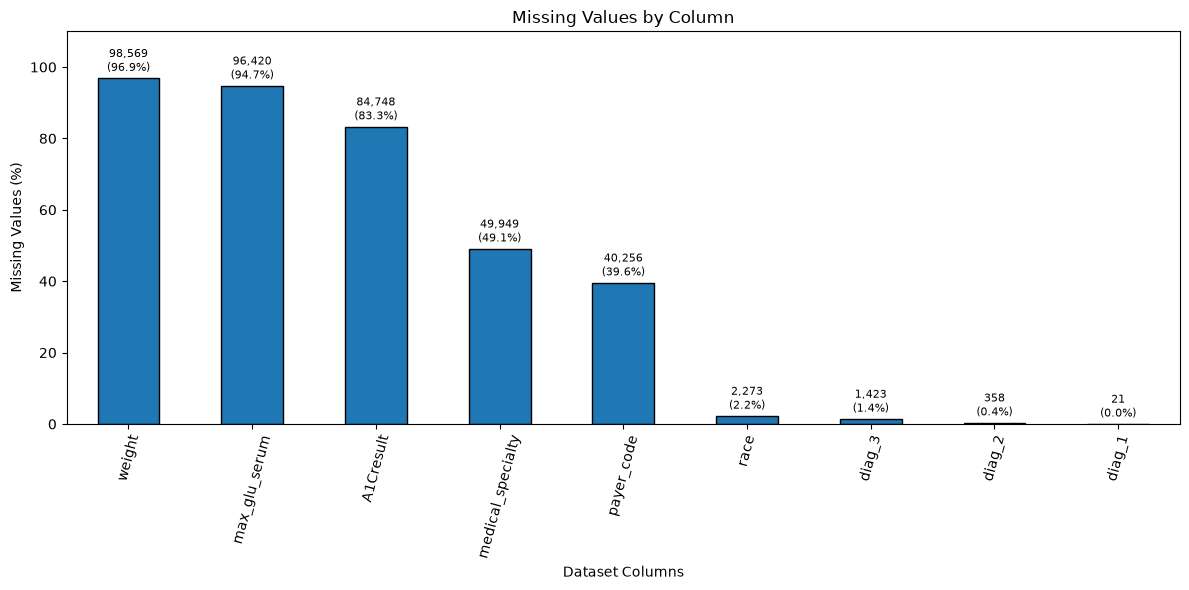

In [18]:
# Missing Values with Count Labels
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

ax = missing_summary["Missing_Percentage"].plot(
    kind="bar",
    edgecolor="black"
)

# Add missing-value counts above each bar
for index, (percentage, count) in enumerate(
    zip(
        missing_summary["Missing_Percentage"],
        missing_summary["Missing_Count"]
    )
):
    ax.text(
        index,
        percentage + 1,
        f"{count:,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.title("Missing Values by Column")
plt.xlabel("Dataset Columns")
plt.ylabel("Missing Values (%)")

plt.xticks(rotation=75)
plt.ylim(0, 110)
plt.tight_layout()
plt.show()



### Observation

- `weight` has the highest missingness (**98,569; 96.9%**), followed by `max_glu_serum` (**96,420; 94.7%**) and `A1Cresult` (**84,748; 83.3%**).
- `medical_specialty` and `payer_code` also show substantial missingness, at **49.1%** and **39.6%**, respectively.
- The remaining columns have relatively low missing-value percentages.
- These findings will guide our missing-value treatment and feature-selection decisions during preprocessing.


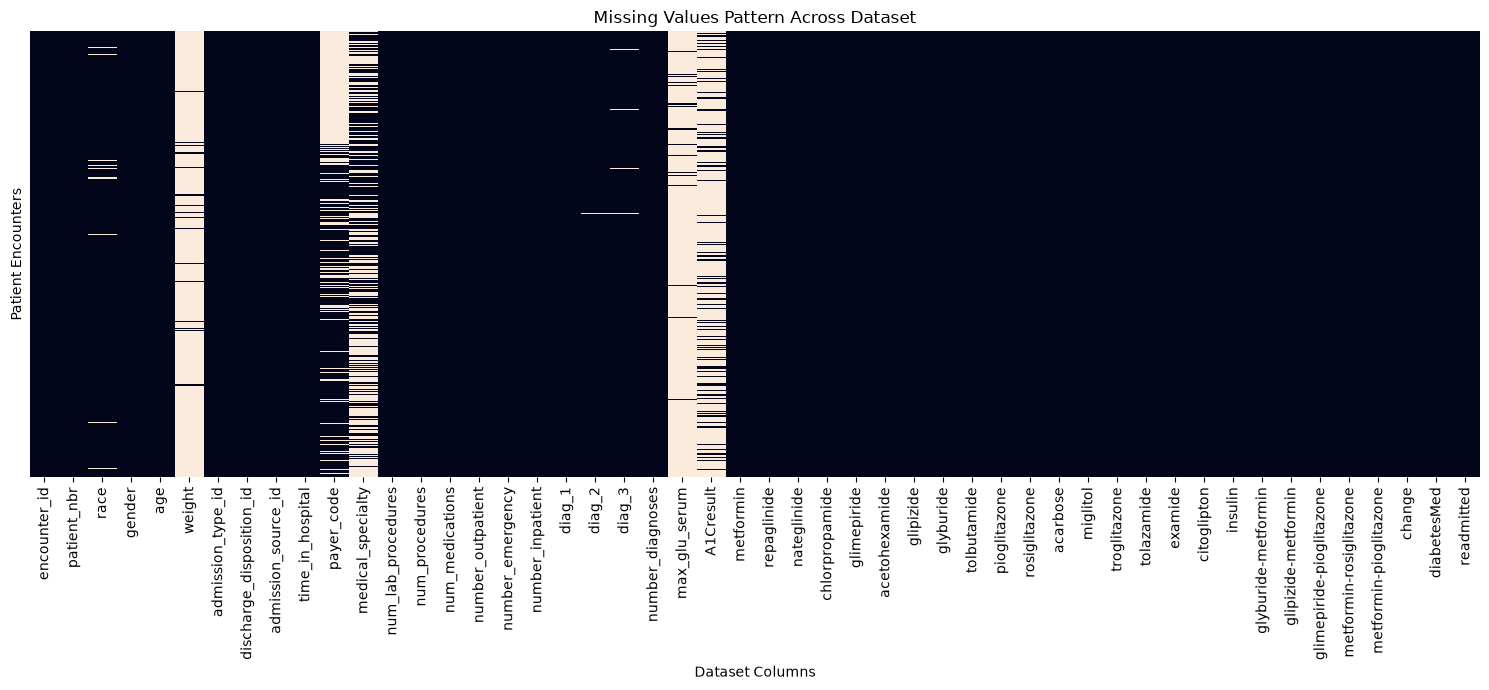

In [19]:
# Missing Values Heatmap

import seaborn as sns

plt.figure(figsize=(15, 7))

sns.heatmap(
    missing_data.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values Pattern Across Dataset")
plt.xlabel("Dataset Columns")
plt.ylabel("Patient Encounters")

plt.tight_layout()
plt.show()



### Observation

- Missing values are concentrated in a small number of columns, particularly `weight`, `payer_code`, `medical_specialty`, `max_glu_serum`, and `A1Cresult`.
- Most other columns appear to have complete data.
- The heatmap highlights the uneven distribution of missing values across patient encounters.


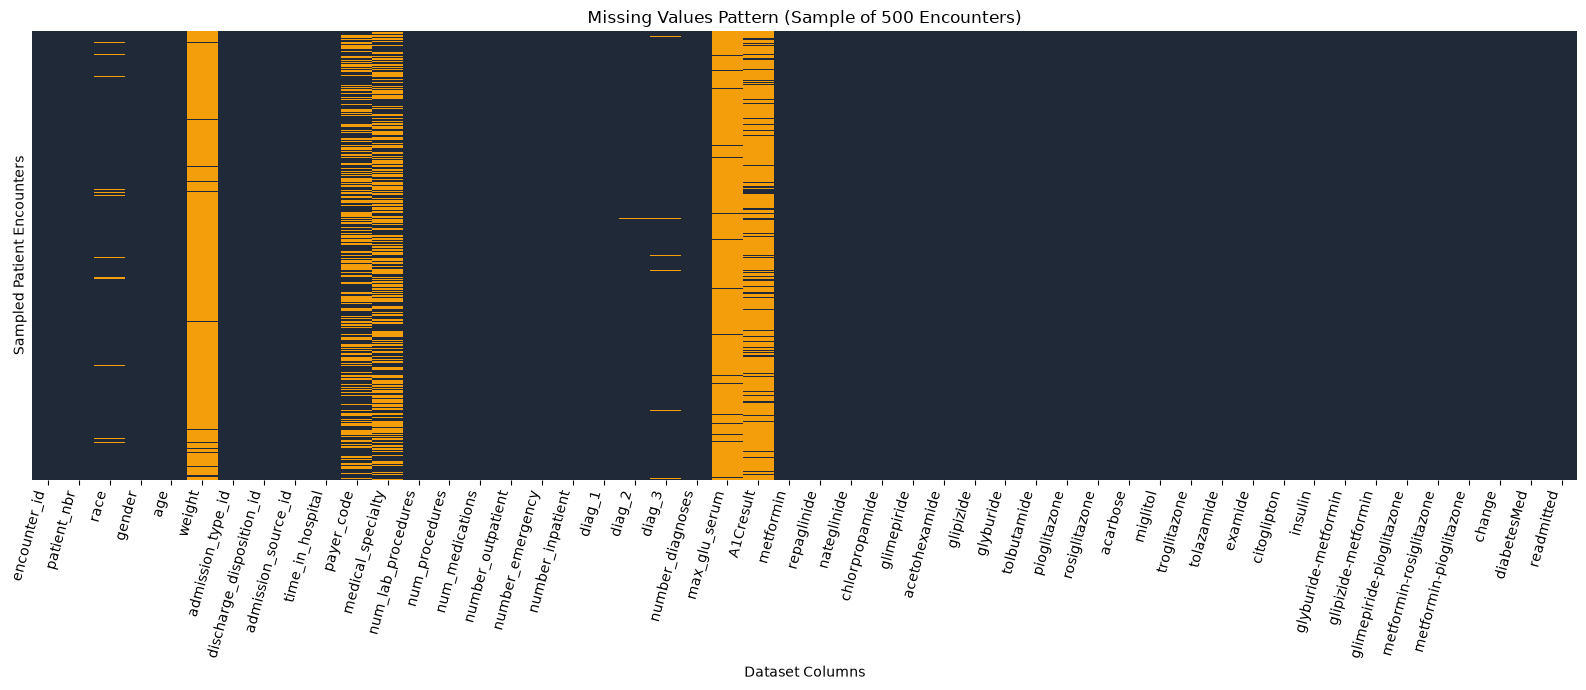

In [20]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select a reproducible sample of 500 encounters
sample_missing_data = missing_data.sample(
    n=500,
    random_state=42
)

# Create heatmap
plt.figure(figsize=(16, 7))

sns.heatmap(
    sample_missing_data.isnull(),
    cmap=["#1f2937", "#f59e0b"],
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values Pattern (Sample of 500 Encounters)")
plt.xlabel("Dataset Columns")
plt.ylabel("Sampled Patient Encounters")

plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()



### Observation

- The heatmap confirms that missing values are concentrated in specific columns rather than distributed uniformly across the dataset.
- `weight`, `payer_code`, `medical_specialty`, `max_glu_serum`, and `A1Cresult` show prominent missing-value patterns.
- Most remaining columns appear to have relatively complete data.
- The sample provides a clearer visual representation of missingness, while the complete dataset remains the basis for our numerical analysis.


# Section 6 — Readmission Pattern Analysis


## 6. Readmission Pattern Analysis

After understanding the dataset structure, data quality, and overall readmission distribution, we will investigate readmission patterns across different patient and hospital encounter characteristics.

The objectives are to:

- Identify characteristics associated with different readmission outcomes.
- Understand potential patterns in the original dataset.
- Explore relationships that may help with feature selection.
- Generate preliminary business insights for hospital readmission management.

We will analyze patient demographics, hospital encounter characteristics, medical information, and previous healthcare utilization.

**Note:** These analyses describe associations in the historical dataset and do not establish causation.


### 6.1 Readmission Distribution Across Age Groups

Analyze readmission outcomes across different age groups using both **patient counts and percentages**.

Combining counts and percentages in the same cell makes it easier to compare readmission patterns across age groups, even when the number of encounters differs.

- Counts show the number of encounters.
- Percentages show the proportion within each age group.

In [21]:
# Calculate readmission counts by age group
age_readmission_counts = pd.crosstab(
    df["age"],
    df["readmitted"]
)

# Calculate readmission percentages within each age group
age_readmission_percentage = pd.crosstab(
    df["age"],
    df["readmitted"],
    normalize="index"
) * 100

# Combine count and percentage into a single cell
age_readmission_summary = age_readmission_counts.astype(str) + " (" + \
    age_readmission_percentage.round(2).astype(str) + "%)"

# Display the combined summary
age_readmission_summary

readmitted,<30,>30,NO
age,,,
[0-10),3 (1.86%),26 (16.15%),132 (81.99%)
[10-20),40 (5.79%),224 (32.42%),427 (61.79%)
[20-30),236 (14.24%),510 (30.78%),911 (54.98%)
[30-40),424 (11.23%),1187 (31.44%),2164 (57.32%)
[40-50),1027 (10.6%),3278 (33.85%),5380 (55.55%)
[50-60),1668 (9.67%),5917 (34.29%),9671 (56.04%)
[60-70),2502 (11.13%),7897 (35.12%),12084 (53.75%)
[70-80),3069 (11.77%),9475 (36.35%),13524 (51.88%)
[80-90),2078 (12.08%),6223 (36.19%),8896 (51.73%)


### Key Observations – Readmission Across Age Groups

- **Early readmission (`<30 days`)** is highest in the 20–30 age group (14.24%).
- **Readmission after 30 days (`>30`)** is more common among older age groups, particularly 70–90 years, higher than 35%.
- **No readmission (`NO`)** is highest among younger patients and generally decreases with age.

### How This Helps in Preprocessing

- **Age has no missing values**, so no imputation is required.
- Preserve age as a useful feature because readmission patterns vary across age groups.
- Use these observations to guide feature selection and later model evaluation.
- **Do not fill missing values based on readmission patterns alone**; investigate each feature's missingness separately.

### 6.2 Readmission Distribution Across Gender

Analyze readmission outcomes across gender categories.

- Compare readmission counts and percentages across genders.
- Identify differences in readmission patterns.
- Understand whether gender may be a useful feature for prediction.

In [22]:
# Calculate readmission counts by gender
gender_readmission_counts = pd.crosstab(
    df["gender"],
    df["readmitted"]
)

# Calculate percentages within each gender
gender_readmission_percentage = pd.crosstab(
    df["gender"],
    df["readmitted"],
    normalize="index"
) * 100

# Combine counts and percentages
gender_readmission_summary = (
    gender_readmission_counts.astype(str)
    + " ("
    + gender_readmission_percentage.round(2).astype(str)
    + "%)"
)

gender_readmission_summary

readmitted,<30,>30,NO
gender,,,
Female,6152 (11.25%),19518 (35.68%),29038 (53.08%)
Male,5205 (11.06%),16027 (34.06%),25823 (54.88%)
Unknown/Invalid,0 (0.0%),0 (0.0%),3 (100.0%)


### Key Observations – Readmission Across Gender

- **Early readmission (`<30 days`)** is slightly higher among females (11.25%) than males (11.06%).
- **Readmission after 30 days (`>30`)** is higher among females (35.68%) than males (34.06%).
- **No readmission (`NO`)** is slightly higher among males (54.88%) than females (53.08%).
- The gender-wise differences are relatively small, suggesting gender alone may not strongly distinguish readmission outcomes.
- **Unknown/Invalid gender:** Only 3 records exist, all with no readmission.

### How This Helps in Preprocessing

- The `gender` column contains **3 Unknown/Invalid values**.
- Since these records are very few, investigate whether they should be corrected or handled as a separate category.
- Preserve gender for now; evaluate its usefulness during model development.
- Avoid making conclusions from the 3 Unknown/Invalid records due to the extremely small sample.

### 6.3 Readmission Distribution Across Race

Analyze readmission outcomes across different race categories.

- Compare readmission counts and percentages across race groups.
- Identify differences in readmission patterns.
- Understand whether race may be relevant for model evaluation and fairness analysis.

In [23]:
# Calculate readmission counts by race
race_readmission_counts = pd.crosstab(
    df["race"],
    df["readmitted"]
)

# Calculate percentages within each race
race_readmission_percentage = pd.crosstab(
    df["race"],
    df["readmitted"],
    normalize="index"
) * 100

# Combine counts and percentages
race_readmission_summary = (
    race_readmission_counts.astype(str)
    + " ("
    + race_readmission_percentage.round(2).astype(str)
    + "%)"
)

race_readmission_summary

readmitted,<30,>30,NO
race,,,
?,188 (8.27%),538 (23.67%),1547 (68.06%)
AfricanAmerican,2155 (11.22%),6634 (34.53%),10421 (54.25%)
Asian,65 (10.14%),161 (25.12%),415 (64.74%)
Caucasian,8592 (11.29%),27124 (35.64%),40383 (53.07%)
Hispanic,212 (10.41%),642 (31.52%),1183 (58.08%)
Other,145 (9.63%),446 (29.61%),915 (60.76%)


### Key Observations – Readmission Across Race

- **Caucasian patients** have the highest early readmission percentage (11.29%), closely followed by AfricanAmerican patients (11.22%).
- **Readmission after 30 days (`>30`)** is highest among Caucasian patients (35.64%) and AfricanAmerican patients (34.53%).
- The **Asian group** has the lowest `>30` readmission percentage (25.12%).
- The `?` category represents **missing race values** and accounts for 2,273 records.

### How This Helps in Preprocessing

- Replace `?` with a proper missing-value representation.
- Since race is a categorical feature, evaluate **missing-category handling** rather than numerical imputation.
- Preserve race initially and assess its predictive contribution and potential fairness implications.
- Avoid removing records solely because race is missing.

### 6.4 Readmission Distribution Across Admission Types

Analyze readmission outcomes across different hospital admission types.

- Compare readmission counts and percentages across admission types.
- Identify admission categories with different readmission patterns.
- Understand whether admission type may be useful for predicting readmission.

In [24]:
# Extract admission type mapping
admission_type_mapping = mapping_df.iloc[:8].copy()

# Convert mapping IDs to numeric
admission_type_mapping["admission_type_id"] = pd.to_numeric(
    admission_type_mapping["admission_type_id"],
    errors="coerce"
)

# Create mapping dictionary
admission_type_names = dict(
    zip(
        admission_type_mapping["admission_type_id"],
        admission_type_mapping["description"]
    )
)

# Add admission type descriptions
df["admission_type_name"] = df["admission_type_id"].map(
    admission_type_names
)

In [25]:
# Admission type readmission counts
admission_counts = pd.crosstab(
    [df["admission_type_id"], df["admission_type_name"]],
    df["readmitted"]
)

# Admission type readmission percentages
admission_percentages = pd.crosstab(
    [df["admission_type_id"], df["admission_type_name"]],
    df["readmitted"],
    normalize="index"
) * 100

# Combine counts and percentages
admission_summary = (
    admission_counts.astype(str)
    + " ("
    + admission_percentages.round(2).astype(str)
    + "%)"
)

admission_summary = admission_summary.drop(columns=["readmitted"], errors="ignore")

admission_summary

,readmitted,<30,>30,NO
admission_type_id,admission_type_name,,,
1,Emergency,6221 (11.52%),19309 (35.76%),28460 (52.71%)
2,Urgent,2066 (11.18%),6452 (34.91%),9962 (53.91%)
3,Elective,1961 (10.39%),5746 (30.45%),11162 (59.16%)
4,Newborn,1 (10.0%),2 (20.0%),7 (70.0%)
5,Not Available,495 (10.34%),1721 (35.97%),2569 (53.69%)
7,Trauma Center,0 (0.0%),0 (0.0%),21 (100.0%)
8,Not Mapped,27 (8.44%),84 (26.25%),209 (65.31%)


### Observations and Preprocessing Considerations — Admission Type Analysis

The admission type analysis helps us understand how hospital admission categories relate to readmission outcomes. It also provides useful information for selecting and preparing categorical features before developing the Machine Learning model.

#### Observations

- **Emergency admissions (ID 1):** Emergency admissions account for the largest number of encounters in the dataset. Approximately 11.52% of these patients were readmitted within 30 days, while 35.76% were readmitted after 30 days.

- **Urgent admissions (ID 2):** Urgent admissions show an early readmission rate of 11.18%. Their readmission distribution is relatively similar to emergency admissions.

- **Elective admissions (ID 3):** Elective admissions have the highest proportion of patients with no recorded readmission, approximately 59.16%. This category also has a comparatively lower early readmission rate of 10.39%.

- **Newborn admissions (ID 4):** Only 10 encounters are available for this admission type. Although 70% have no recorded readmission, the small sample size makes this percentage less reliable for drawing conclusions.

- **Trauma Center admissions (ID 7):** All 21 encounters belong to the `NO` readmission category. Since this category contains very few records, its outcome distribution should be interpreted cautiously.

- **Missing admission type descriptions:** Admission Type ID 6 does not have a corresponding description in the provided mapping file. However, a missing description does not necessarily mean that the original admission type value is missing.

#### How This Analysis Helps Preprocessing

**1. Handling Missing Values**

The mapping file contains an unavailable description for Admission Type ID 6. Instead of immediately removing these records, we should investigate the original dataset and mapping file. The original admission type ID should be preserved wherever possible.

**2. Handling Categorical Features**

Admission type IDs represent categories rather than numerical measurements. Therefore, they should not automatically be treated as continuous numerical variables. During preprocessing, we can consider appropriate categorical encoding techniques such as **One-Hot Encoding**.

**3. Handling Rare Categories**

Newborn and Trauma Center admissions have very few encounters compared with other categories. We should examine their frequency before deciding whether to retain them separately or combine categories. Combining categories should only be considered when there is a reasonable justification.

**4. Feature Selection**

Admission type provides potentially useful information about hospital encounters and should be retained initially for model development. Its contribution can later be evaluated through feature importance or model performance analysis.

#### Preprocessing Decision

Based on this analysis, we will preserve the original admission type information, investigate missing descriptions, handle admission type as a categorical feature, and examine rare categories before encoding.

This analysis helps ensure that preprocessing decisions are based on the dataset's actual characteristics rather than unnecessarily removing potentially valuable information.

### Discharge Disposition and Readmission Analysis

Discharge disposition describes the patient's discharge destination or disposition following a hospital encounter. Analyzing this feature helps us understand how readmission outcomes vary across different discharge categories.

The objective of this analysis is to examine the distribution of discharge disposition categories, compare their readmission patterns, and identify missing or uncommon categories that may require attention during preprocessing.

In [26]:
# Discharge disposition readmission counts
discharge_counts = pd.crosstab(
    df["discharge_disposition_id"],
    df["readmitted"]
)

# Readmission percentages within each discharge category
discharge_percentages = pd.crosstab(
    df["discharge_disposition_id"],
    df["readmitted"],
    normalize="index"
) * 100

# Combine counts and percentages
discharge_summary = (
    discharge_counts.astype(str)
    + " ("
    + discharge_percentages.round(2).astype(str)
    + "%)"
)

discharge_summary

readmitted,<30,>30,NO
discharge_disposition_id,,,
1,5602 (9.3%),21517 (35.72%),33115 (54.98%)
2,342 (16.07%),668 (31.39%),1118 (52.54%)
3,2046 (14.66%),4916 (35.23%),6992 (50.11%)
4,104 (12.76%),278 (34.11%),433 (53.13%)
5,247 (20.86%),350 (29.56%),587 (49.58%)
6,1638 (12.7%),5362 (41.56%),5902 (45.74%)
7,90 (14.45%),221 (35.47%),312 (50.08%)
8,15 (13.89%),38 (35.19%),55 (50.93%)
9,9 (42.86%),2 (9.52%),10 (47.62%)


### Observations and Preprocessing Considerations — Discharge Disposition Analysis

The discharge disposition analysis examines readmission patterns across different discharge categories. It helps identify potentially informative features, rare categories, and values that require further investigation before preprocessing.

#### Observations

- **Discharge Disposition ID 1:** Represents the largest group of encounters, with 9.30% readmitted within 30 days and 54.98% having no recorded readmission.

- **Discharge Disposition ID 2:** Shows an early readmission rate of 16.07%, which is higher than that of ID 1.

- **Discharge Disposition ID 3:** Has an early readmission rate of 14.66%, while approximately 50.11% of encounters belong to the NO category.

- **Discharge Disposition ID 5:** Shows an early readmission rate of 20.86%. This category may deserve further investigation because its readmission percentage is comparatively high.

- **Discharge Disposition ID 6:** Has a later readmission rate of 41.56%, which is among the higher percentages in the larger categories.

- **Discharge Disposition IDs 9, 12, 15, and 28:** Show unusually high early readmission percentages. However, these categories contain relatively few encounters, so their percentages should be interpreted cautiously.

- **Discharge Disposition IDs 11, 19, and 20:** Have no recorded early or later readmissions in the displayed data. Their sample sizes are small or limited, except ID 11, which contains 1,642 encounters.

#### How This Analysis Helps Preprocessing

**1. Handling Missing Values**

The table does not directly establish whether discharge disposition contains missing values. We should separately inspect missing-value representations such as NaN and hidden tokens before deciding how to handle them.

**2. Handling Categorical Features**

Discharge disposition IDs represent categories rather than numerical measurements. Therefore, they should be treated as categorical features and encoded appropriately during preprocessing.

**3. Handling Rare Categories**

Some discharge disposition categories contain very few encounters. We should examine their frequency before deciding whether to retain them separately or combine rare categories. Any combination should be based on domain meaning and a clear justification.

**4. Preserving Potentially Useful Features**

Discharge disposition may contain information relevant to readmission prediction. It should initially be retained and evaluated during model development.

**5. Checking Prediction-Time Availability**

Before including this feature in the final model, verify that discharge disposition is available at the intended prediction time. If the model predicts readmission risk before discharge, this information may not yet be available.

#### Preprocessing Decision

Retain discharge disposition initially, investigate missing values, treat it as categorical, and examine rare categories before encoding. Confirm that the feature is available at the intended prediction time to avoid information leakage.

### Admission Source and Readmission Analysis

Admission source identifies how a patient entered the hospital or healthcare facility. Analyzing this feature helps us understand how readmission outcomes vary across different patient entry pathways.

The objective is to examine the distribution of admission source categories, compare their readmission patterns, and identify missing or uncommon categories that may require attention during preprocessing.

In [27]:
# Admission source readmission counts
admission_source_counts = pd.crosstab(
    df["admission_source_id"],
    df["readmitted"]
)

# Readmission percentages within each admission source
admission_source_percentages = pd.crosstab(
    df["admission_source_id"],
    df["readmitted"],
    normalize="index"
) * 100

# Combine counts and percentages
admission_source_summary = (
    admission_source_counts.astype(str)
    + " ("
    + admission_source_percentages.round(2).astype(str)
    + "%)"
)

admission_source_summary

readmitted,<30,>30,NO
admission_source_id,,,
1,3130 (10.59%),9640 (32.61%),16795 (56.81%)
2,111 (10.05%),310 (28.08%),683 (61.87%)
3,29 (15.51%),58 (31.02%),100 (53.48%)
4,309 (9.7%),672 (21.09%),2206 (69.22%)
5,101 (11.81%),236 (27.6%),518 (60.58%)
6,212 (9.36%),398 (17.58%),1654 (73.06%)
7,6720 (11.69%),21667 (37.69%),29107 (50.63%)
8,2 (12.5%),4 (25.0%),10 (62.5%)
9,13 (10.4%),16 (12.8%),96 (76.8%)


### Observations and Preprocessing Considerations — Admission Source Analysis

The admission source analysis examines how patients entered the hospital and how their readmission outcomes vary across different admission pathways. This analysis helps identify potentially useful categorical features, uncommon categories, and preprocessing requirements.

#### Observations

- **Admission Source ID 7:** Accounts for the largest number of encounters, with 11.69% readmitted within 30 days and 37.69% readmitted after 30 days.

- **Admission Source ID 1:** Represents another large group, with an early readmission rate of 10.59% and 56.81% of encounters having no recorded readmission.

- **Admission Source ID 4:** Has a relatively high proportion of patients with no readmission (69.22%) and a lower later readmission rate of 21.09%.

- **Admission Source ID 6:** Shows 73.06% of encounters in the NO category, while 9.36% were readmitted within 30 days.

- **Admission Source ID 20:** Has a later readmission rate of 50.31%, which is comparatively high. However, this category contains only 161 encounters, so the percentage should be interpreted cautiously.

- **Admission Source IDs 8, 10, 11, 13, 14, 22, and 25:** Contain very few encounters. Their readmission percentages may be unstable because of their small sample sizes.

#### How This Analysis Helps Preprocessing

**1. Handling Missing Values**

The current summary does not directly establish whether admission source contains missing values. We should separately inspect NaN values and hidden missing-value representations before deciding how to handle them.

**2. Handling Categorical Features**

Admission source IDs represent categories rather than numerical measurements. Therefore, they should be treated as categorical features and encoded appropriately during preprocessing.

**3. Handling Rare Categories**

Several admission source categories contain very few encounters. Their frequency should be examined before deciding whether to retain them separately or combine them with other categories. Any grouping should be supported by meaningful category descriptions.

**4. Feature Selection**

Admission source may provide useful information about hospital encounters and should initially be retained for model development. Its contribution can later be evaluated through model performance and feature analysis.

**5. Checking Prediction-Time Availability**

Before including this feature in the final model, confirm that admission source information is available at the intended prediction time.

#### Preprocessing Decision

Retain admission source initially, investigate missing values, treat it as categorical, and examine rare categories before encoding. Avoid removing records solely because their admission source category is uncommon.

----------------------------------------------------------------------------------

### Medical Specialty and Readmission Analysis

The `medical_specialty` feature represents the medical specialty associated with the hospital encounter. Analyzing this feature helps us understand how readmission outcomes vary across different medical specialties.

During the initial data quality assessment, we identified a substantial number of missing values in this column. Therefore, this analysis will help us understand the distribution of medical specialties, their readmission patterns, and the potential implications for missing-value handling during preprocessing.

The objective is to identify commonly represented specialties, examine readmission patterns, and determine suitable preprocessing strategies for missing and uncommon categories.

In [28]:
# Medical specialty readmission counts
specialty_counts = pd.crosstab(
    df["medical_specialty"],
    df["readmitted"]
)

# Readmission percentages within each specialty
specialty_percentages = pd.crosstab(
    df["medical_specialty"],
    df["readmitted"],
    normalize="index"
) * 100

# Combine counts and percentages
specialty_summary = (
    specialty_counts.astype(str)
    + " ("
    + specialty_percentages.round(2).astype(str)
    + "%)"
)

specialty_summary

readmitted,<30,>30,NO
medical_specialty,,,
?,5781 (11.57%),18216 (36.47%),25952 (51.96%)
AllergyandImmunology,3 (42.86%),3 (42.86%),1 (14.29%)
Anesthesiology,1 (8.33%),3 (25.0%),8 (66.67%)
Anesthesiology-Pediatric,1 (5.26%),5 (26.32%),13 (68.42%)
Cardiology,425 (7.94%),1853 (34.62%),3074 (57.44%)
...,...,...,...
Surgery-PlasticwithinHeadandNeck,0 (0.0%),1 (100.0%),0 (0.0%)
Surgery-Thoracic,11 (10.09%),30 (27.52%),68 (62.39%)
Surgery-Vascular,74 (13.88%),200 (37.52%),259 (48.59%)


### Observations and Preprocessing Considerations — Medical Specialty Analysis

The medical specialty analysis examines readmission patterns across different medical specialties associated with hospital encounters. This feature requires particular attention because the initial data quality assessment identified a substantial number of missing values.

#### Observations

- **Missing Specialty (`?`):** The `?` category contains 49,949 encounters, representing approximately 49.08% of the dataset. Within this category, 11.57% of encounters resulted in early readmission, while 36.47% resulted in readmission after 30 days.

- **Cardiology:** Cardiology contains a considerable number of encounters, with an early readmission rate of 7.94% and a later readmission rate of 34.62%.

- **Surgery-Vascular:** This specialty shows an early readmission rate of 13.88% and a later readmission rate of 37.52%.

- **Urology:** Approximately 9.93% of encounters resulted in early readmission, while 63.07% had no recorded readmission.

- **Rare Medical Specialties:** Several specialties contain very few encounters. Their readmission percentages may vary considerably because of limited observations.

- **High Category Diversity:** The dataset contains 73 medical specialty categories, indicating that this feature has substantial categorical diversity.

#### How This Analysis Helps Preprocessing

**1. Handling Missing Values**

The `?` representation should be converted into a proper missing value during preprocessing. Since nearly half of the records lack specialty information, removing these encounters could result in substantial data loss.

We should investigate suitable strategies, such as replacing missing values with an explicit `Unknown` category or using another justified categorical imputation approach.

**2. Handling Categorical Features**

Medical specialty is a categorical feature and should not be treated as a continuous numerical variable. Appropriate categorical encoding will be required before training the MLP model.

**3. Handling Rare Categories**

Several specialties contain very few encounters. We should examine their frequencies and consider whether rare categories need grouping. Any grouping should preserve meaningful medical information.

**4. Feature Retention**

Medical specialty should initially be retained because it may provide useful information about hospital encounters. Its contribution can later be evaluated during model development.

#### Preprocessing Decision

Convert `?` into a proper missing-value representation, investigate the missingness pattern, retain the feature initially, and evaluate suitable categorical imputation and encoding strategies. Avoid dropping large numbers of encounters simply because medical specialty information is unavailable.

----------------------------------------------------------------------------------------------------------------------------------

## Section 6.8 — Diagnosis Analysis 

### Diagnosis and Readmission Analysis

The dataset contains three diagnosis-related features: `diag_1`, `diag_2`, and `diag_3`.

- `diag_1`: Primary diagnosis associated with the hospital encounter.
- `diag_2`: Secondary diagnosis associated with the encounter.
- `diag_3`: Additional diagnosis associated with the encounter.

The objective of this analysis is to examine the distribution of diagnosis categories, understand their relationship with readmission outcomes, and identify missing or invalid values that may require preprocessing.

Since diagnosis information is represented using categorical codes, these features require appropriate categorical handling rather than being treated as continuous numerical variables.

In [29]:
# Check missing values in diagnosis features
diagnosis_columns = ["diag_1", "diag_2", "diag_3"]

diagnosis_missing_summary = pd.DataFrame({
    "Missing Count": df[diagnosis_columns].isnull().sum(),
    "Missing Percentage": (
        df[diagnosis_columns].isnull().mean() * 100
    ).round(2)
})

diagnosis_missing_summary

,Missing Count,Missing Percentage
diag_1,0,0.0
diag_2,0,0.0
diag_3,0,0.0


In [30]:
# Check '?' values in diagnosis features
diagnosis_hidden_missing = (
    df[diagnosis_columns]
    .astype("string")
    .eq("?")
    .sum()
)

diagnosis_hidden_missing

diag_1      21
diag_2     358
diag_3    1423
dtype: uint64[pyarrow]

### Observations and Preprocessing Considerations — Diagnosis Features

The diagnosis analysis examines missing-value representations in the primary, secondary, and additional diagnosis features. These features contain categorical diagnosis codes and require appropriate preprocessing before model development.

#### Observations

- **diag_1:** Contains 21 hidden missing values represented by `?`, accounting for approximately 0.02% of the dataset.
- **diag_2:** Contains 358 hidden missing values, representing approximately 0.35% of the dataset.
- **diag_3:** Contains 1,423 hidden missing values, representing approximately 1.40% of the dataset.
- **No Standard Missing Values:** All three diagnosis columns contain zero standard pandas NaN values. However, hidden missing values are present in the form of `?`.
- **Difference in Missingness:** `diag_3` contains the highest number of hidden missing values, followed by `diag_2` and `diag_1`.

#### How This Analysis Helps Preprocessing

**1. Missing-Value Standardization**

The `?` representation should be converted into a proper missing-value representation such as `NaN`. This ensures that pandas and subsequent preprocessing techniques can recognize these values consistently.

**2. Missing-Value Handling**

Since the missing-value percentages are relatively small, we should investigate suitable categorical imputation strategies rather than automatically removing records. An explicit `Unknown` category may be considered if it is appropriate for the modeling approach.

**3. Categorical Feature Handling**

Diagnosis codes represent medical categories rather than continuous numerical measurements. Therefore, they should be treated as categorical features and encoded appropriately before training the MLP.

**4. Feature Preservation**

Initially, retain all three diagnosis features because they may contain useful information for readmission prediction. Their contribution can be evaluated during model development.

#### Preprocessing Decision

Standardize hidden missing values represented by `?`, investigate appropriate categorical missing-value handling, and retain the diagnosis features initially. Avoid unnecessary record removal because of the relatively small proportion of missing values.

---------------------------------------------------------------------------------------------------------------------


### Diagnosis Code Distribution Analysis

The dataset contains three diagnosis-related features: `diag_1`, `diag_2`, and `diag_3`. These features represent primary, secondary, and additional diagnoses associated with hospital encounters.

The objective of this analysis is to identify the most frequently occurring diagnosis codes in each feature, understand their distribution, and investigate whether certain categories dominate the dataset.

This analysis will help us understand the categorical nature of diagnosis features and determine appropriate preprocessing strategies before model development.

In [31]:
# Identify the 10 most frequently occurring diagnosis codes
# in the primary, secondary, and additional diagnosis columns.

diagnosis_columns = ["diag_1", "diag_2", "diag_3"]

for column in diagnosis_columns:
    print(f"\nMost frequent diagnosis codes in {column}:")
    print(df[column].value_counts().head(10))


Most frequent diagnosis codes in diag_1:
diag_1
428    6862
414    6581
786    4016
410    3614
486    3508
427    2766
491    2275
715    2151
682    2042
434    2028
Name: count, dtype: int64

Most frequent diagnosis codes in diag_2:
diag_2
276    6752
428    6662
250    6071
427    5036
401    3736
496    3305
599    3288
403    2823
414    2650
411    2566
Name: count, dtype: int64

Most frequent diagnosis codes in diag_3:
diag_3
250    11555
401     8289
276     5175
428     4577
427     3955
414     3664
496     2605
403     2357
585     1992
272     1969
Name: count, dtype: int64


### Observations and Preprocessing Considerations — Diagnosis Code Distribution

The diagnosis code distribution analysis examines the most frequently occurring codes in the primary, secondary, and additional diagnosis features. This helps us understand the categorical distribution of diagnosis information and identify preprocessing requirements.

#### Observations

- **Primary Diagnosis (`diag_1`):** Diagnosis code `428` is the most frequent, with 6,862 occurrences, followed by `414` with 6,581 occurrences.
- **Other Frequent Primary Diagnoses:** Codes `786`, `410`, and `486` also occur frequently, with 4,016, 3,614, and 3,508 occurrences, respectively.
- **Secondary Diagnosis (`diag_2`):** Code `276` is the most frequent, with 6,752 occurrences, followed by `428` with 6,662 occurrences and `250` with 6,071 occurrences.
- **Additional Diagnosis (`diag_3`):** The output is truncated, so the complete distribution cannot be interpreted from the currently available results.
- **Different Diagnosis Distributions:** The most frequent codes differ between primary and secondary diagnosis columns, indicating that the three features should be examined separately.

#### How This Analysis Helps Preprocessing

**1. Categorical Feature Handling**

Diagnosis codes represent medical categories. Although some codes appear numerical, they should not automatically be treated as continuous numerical values. Appropriate categorical encoding should be considered.

**2. Handling Missing Values**

The earlier analysis identified `?` as a hidden missing-value representation. These values should be standardized before applying categorical preprocessing techniques.

**3. Handling Rare Categories**

Diagnosis features may contain many distinct categories, including less frequently occurring codes. Their distribution should be investigated before selecting an encoding strategy.

**4. Feature Representation**

Diagnosis codes may have high categorical diversity. Encoding methods should be selected carefully to avoid unnecessarily increasing the number of input features or creating an excessively large feature representation.

#### Preprocessing Decision

Retain `diag_1`, `diag_2`, and `diag_3` initially, standardize missing-value representations, and treat diagnosis codes as categorical features. Investigate category frequency and encoding requirements before model development.

---------------------------------------------------------------------------------------------------------

### Diagnosis Code Distribution Visualization

The objective of this visualization is to compare the most frequently occurring diagnosis codes across primary, secondary, and additional diagnosis features.

Bar charts provide a clear representation of diagnosis frequency and help identify dominant categories, differences between diagnosis columns, and potential categorical preprocessing requirements.

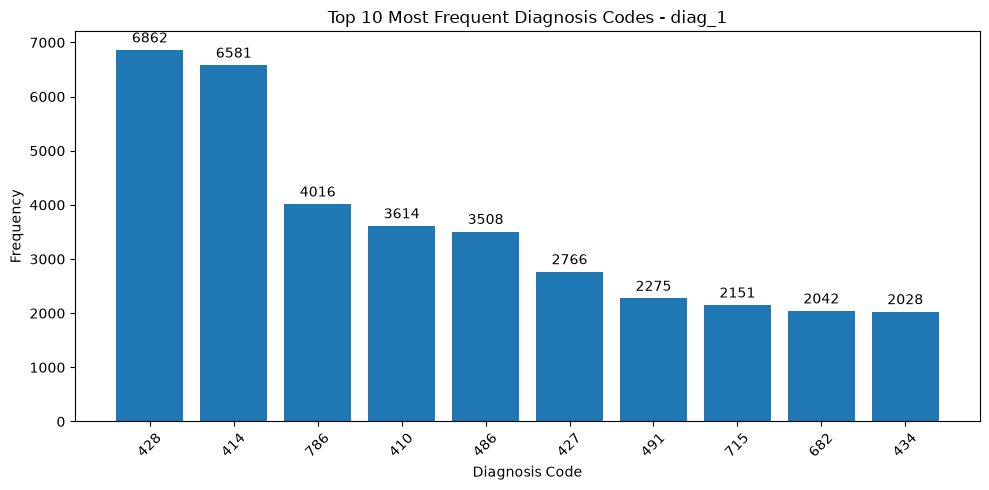

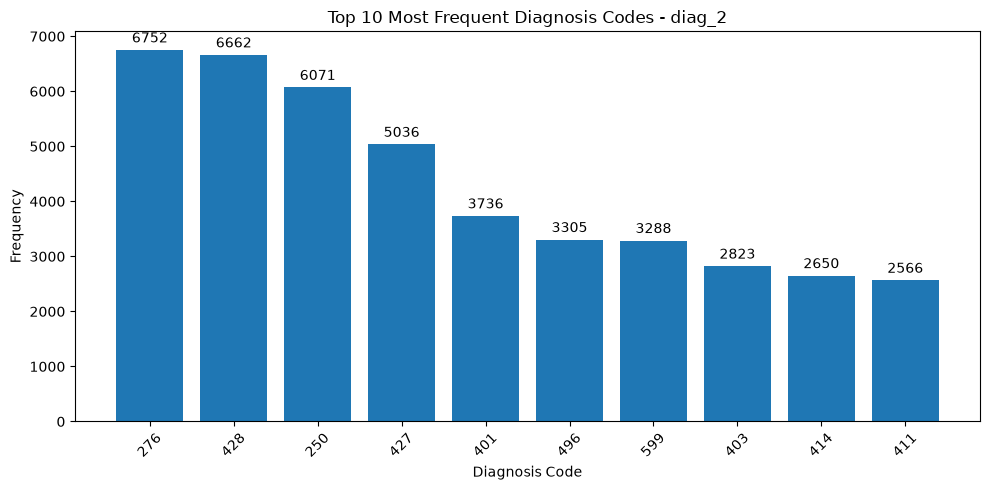

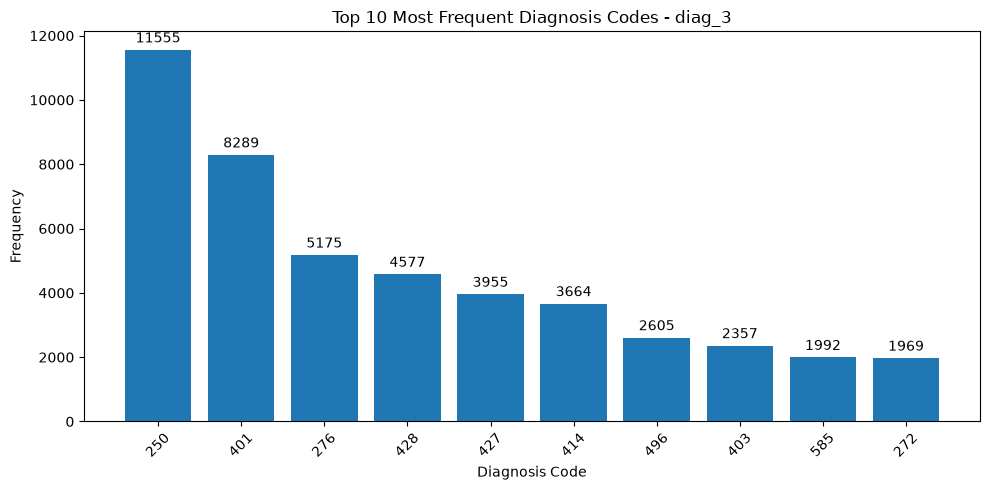

In [32]:
# Visualize the top 10 diagnosis codes in each diagnosis column
# and display their frequency values above the bars.

import matplotlib.pyplot as plt

diagnosis_columns = ["diag_1", "diag_2", "diag_3"]

for column in diagnosis_columns:

    # Identify the 10 most frequent diagnosis codes
    top_diagnoses = df[column].value_counts().head(10)

    # Create bar chart
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(top_diagnoses.index.astype(str), top_diagnoses.values)

    # Display frequency values above each bar
    ax.bar_label(bars, padding=3, fmt="%.0f")

    # Add chart labels and title
    ax.set_title(f"Top 10 Most Frequent Diagnosis Codes - {column}")
    ax.set_xlabel("Diagnosis Code")
    ax.set_ylabel("Frequency")
    ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()

### 6.10 Diagnosis Code Frequency Analysis

The top 10 most frequent diagnosis codes were analyzed across the primary (`diag_1`), secondary (`diag_2`), and additional (`diag_3`) diagnosis columns.

#### Observations

- **Primary diagnosis (`diag_1`):**
  - Code `428` is the most frequent, with 6,862 occurrences.
  - Codes `414` (6,581) and `786` (4,016) are the next most frequent.
  - Codes `410` and `486` also appear frequently.

- **Secondary diagnosis (`diag_2`):**
  - Code `276` is the most frequent, with 6,752 occurrences.
  - Codes `428` (6,662) and `250` (6,071) are also highly frequent.
  - The distribution differs from the primary diagnosis column.

- **Additional diagnosis (`diag_3`):**
  - Code `250` is the most frequent, with 11,555 occurrences.
  - Code `401` follows with 8,289 occurrences.
  - Code `250` appears particularly frequently in the additional diagnosis column compared with the other diagnosis columns.

#### Preprocessing Considerations

- Diagnosis codes should be treated as **categorical features**, not continuous numerical values.
- Convert hidden missing-value tokens (`?`) into proper missing values.
- Preserve the three diagnosis columns because they may provide useful medical information.
- Consider appropriate categorical encoding or grouping of diagnosis codes during feature engineering.
- Avoid assuming that a higher frequency diagnosis code directly indicates a higher readmission risk; investigate its relationship with the target during further analysis.

---------------------------------------------------------------------------------------------------------------------------

### 6.11 Medication-Related Analysis

Medication-related features may provide useful information about patients' treatment patterns during hospitalization.

In this section, we will analyze medication changes and examine their distribution across the three readmission categories: `<30`, `>30`, and `NO`.

The analysis will help identify medication-related patterns and determine whether these features should be retained for model development.

In [33]:
# Purpose: Analyze medication changes across the three readmission categories.

medication_change_summary = pd.crosstab(
    df["change"],
    df["readmitted"],
    normalize="index"
) * 100

medication_change_summary.round(2)

readmitted,<30,>30,NO
change,,,
Ch,11.82,36.74,51.44
No,10.59,33.37,56.04


### 6.11.1 Medication Change Analysis

The relationship between medication changes (`change`) and readmission categories was analyzed using row-wise percentages.

#### Observations

- **Medication changed (`Ch`):**
  - 11.82% of encounters resulted in readmission within 30 days.
  - 36.74% resulted in readmission after 30 days.
  - 51.44% had no readmission.

- **No medication change (`No`):**
  - 10.59% resulted in readmission within 30 days.
  - 33.37% resulted in readmission after 30 days.
  - 56.04% had no readmission.

- Encounters with medication changes show a **slightly higher percentage of early readmission** compared with encounters without medication changes.
- The `Ch` category also has a higher percentage of readmission after 30 days, while the `No` category has a higher percentage of no readmission.

#### Preprocessing Considerations

- The `change` feature is **categorical** and should be encoded appropriately.
- Retain this feature for initial model development because it may provide useful information.
- Investigate its relationship with other medication-related features during further analysis.

----------------------------------------------------------------------------------------------------------

In [34]:
# Purpose: Compare medication counts across readmission categories
# using descriptive statistics.

medication_count_summary = df.groupby("readmitted")["num_medications"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

medication_count_summary

,count,mean,median,min,max,std
readmitted,,,,,,
<30,11357,16.90,16.0,1,81,8.10
>30,35545,16.28,15.0,1,70,7.62
NO,54864,15.67,14.0,1,79,8.43


### 6.11.2 Medication Count Analysis

The descriptive statistics of `num_medications` were analyzed across the three readmission categories to understand differences in medication usage.

#### Observations

- **Early readmission (`<30`):**
  - Highest average medication count of **16.90**.
  - Median medication count is 16.
  - Standard deviation is 8.10.

- **Readmission after 30 days (`>30`):**
  - Average medication count is **16.28**.
  - Median medication count is 15.
  - Standard deviation is 7.62.

- **No readmission (`NO`):**
  - Lowest average medication count of **15.67**.
  - Median medication count is 14.
  - Standard deviation is 8.43.

- Encounters associated with early readmission have a slightly higher average medication count than the other categories.
- The maximum medication count varies across categories, ranging from 70 to 81.
- The distributions show considerable variation within each readmission category.

#### Preprocessing Considerations

- `num_medications` is a **numerical feature** and should be retained for initial model development.
- Investigate its distribution and potential extreme values during numerical feature analysis.
- Apply appropriate scaling during preprocessing before training the MLP model.

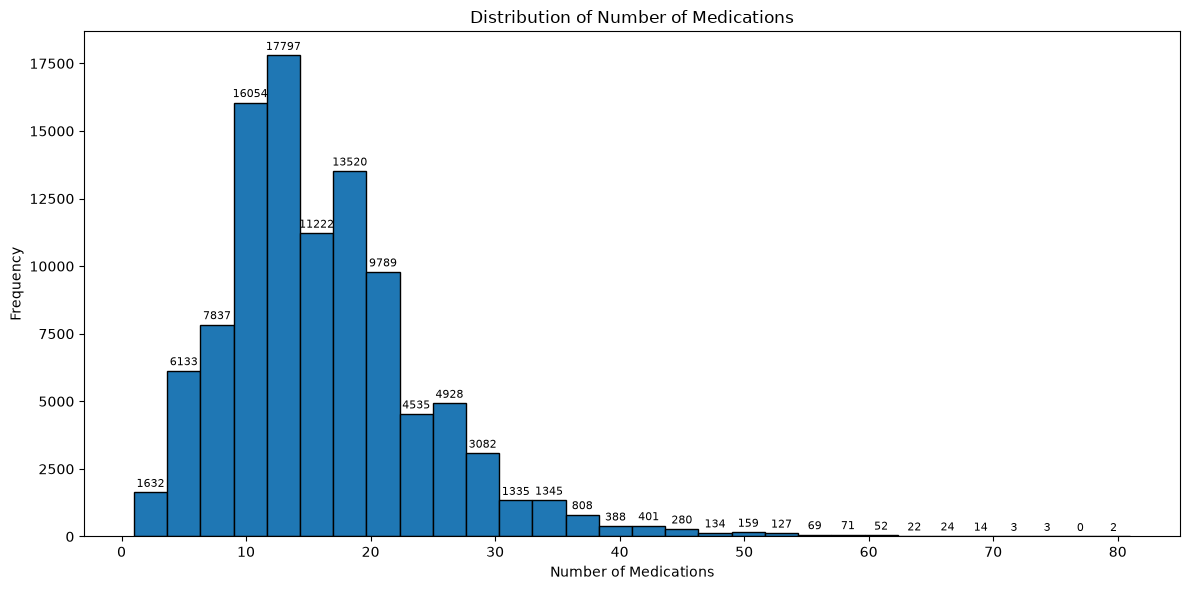

In [35]:
# Visualize the medication count distribution
# and display frequency values above each histogram bar.

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Create histogram and retrieve bar patches
counts, bin_edges, bars = plt.hist(
    df["num_medications"],
    bins=30,
    edgecolor="black"
)

# Display frequency values above the bars
plt.bar_label(bars, padding=2, fmt="%.0f", fontsize=8)

# Add chart labels and title
plt.title("Distribution of Number of Medications")
plt.xlabel("Number of Medications")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### 6.11.3 Medication Count Distribution

A histogram was plotted to examine the distribution of `num_medications` across all hospital encounters.

#### Observations

- The distribution is **right-skewed**, with most encounters concentrated in the lower medication-count range.
- The highest frequency occurs around **12–14 medications**, with approximately 17,797 encounters in the corresponding bin.
- Most encounters involve approximately **8–22 medications**.
- The frequency decreases as the medication count increases.
- A small number of encounters have medication counts exceeding 40, with a few reaching approximately 80.
- The distribution contains a **long right tail**, indicating that high medication counts are relatively uncommon.

#### Preprocessing Considerations

- Retain `num_medications` as a numerical feature.
- Investigate high medication counts during outlier analysis before deciding whether any treatment is necessary.
- Apply appropriate numerical scaling before training the MLP model.
--------------------------------------------------------------------------------------------------------------------

In [36]:
# Purpose: Analyze diabetes medication prescription status
# across the three readmission categories.

diabetes_med_summary = pd.crosstab(
    df["diabetesMed"],
    df["readmitted"],
    normalize="index"
) * 100

diabetes_med_summary.round(2)

readmitted,<30,>30,NO
diabetesMed,,,
No,9.60,30.88,59.52
Yes,11.63,36.14,52.24


### 6.11.4 Diabetes Medication Analysis

The relationship between diabetes medication prescription status (`diabetesMed`) and readmission categories was analyzed using row-wise percentages.

#### Observations

- **Diabetes medication prescribed (`Yes`):**
  - 11.63% of encounters resulted in readmission within 30 days.
  - 36.14% resulted in readmission after 30 days.
  - 52.24% had no readmission.

- **Diabetes medication not prescribed (`No`):**
  - 9.60% resulted in readmission within 30 days.
  - 30.88% resulted in readmission after 30 days.
  - 59.52% had no readmission.

- Encounters with diabetes medication prescribed show a **higher percentage of readmission** in both readmission categories.
- The percentage of encounters with no readmission is higher when diabetes medication was not prescribed.

#### Preprocessing Considerations

- `diabetesMed` is a **categorical feature** and should be encoded appropriately.
- Retain this feature for initial model development because it may provide useful information about medication-related patterns.
- Analyze it alongside other medication features during further investigation.

----------------------------------------------------------------------------------------------------

In [37]:
# Compare the number of recorded diagnoses across
# the three readmission categories using descriptive statistics.

diagnosis_count_summary = df.groupby("readmitted")["number_diagnoses"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

diagnosis_count_summary

,count,mean,median,min,max,std
readmitted,,,,,,
<30,11357,7.69,9.0,1,16,1.77
>30,35545,7.65,9.0,1,16,1.81
NO,54864,7.22,8.0,1,16,2.02


### 6.11.5 Number of Diagnoses Analysis

The descriptive statistics of `number_diagnoses` were analyzed across the three readmission categories to understand differences in the number of recorded diagnoses.

#### Observations

- **Early readmission (`<30`):**
  - Average number of diagnoses is **7.69**.
  - Median is 9 diagnoses.
  - Standard deviation is 1.77.

- **Readmission after 30 days (`>30`):**
  - Average number of diagnoses is **7.65**.
  - Median is 9 diagnoses.
  - Standard deviation is 1.81.

- **No readmission (`NO`):**
  - Average number of diagnoses is **7.22**.
  - Median is 8 diagnoses.
  - Standard deviation is 2.02.

- Both readmission categories have slightly higher average diagnosis counts than the no-readmission category.
- All three categories have the same minimum and maximum values, ranging from 1 to 16 diagnoses.
- The distributions show relatively similar average diagnosis counts across the readmission categories.

#### Preprocessing Considerations

- `number_diagnoses` is a **numerical feature** and should be retained for initial model development.
- Investigate its distribution and potential relationship with other encounter-related features.
- Apply appropriate numerical scaling before training the MLP model.

-------------------------------------------------------------------------------------------------------------------

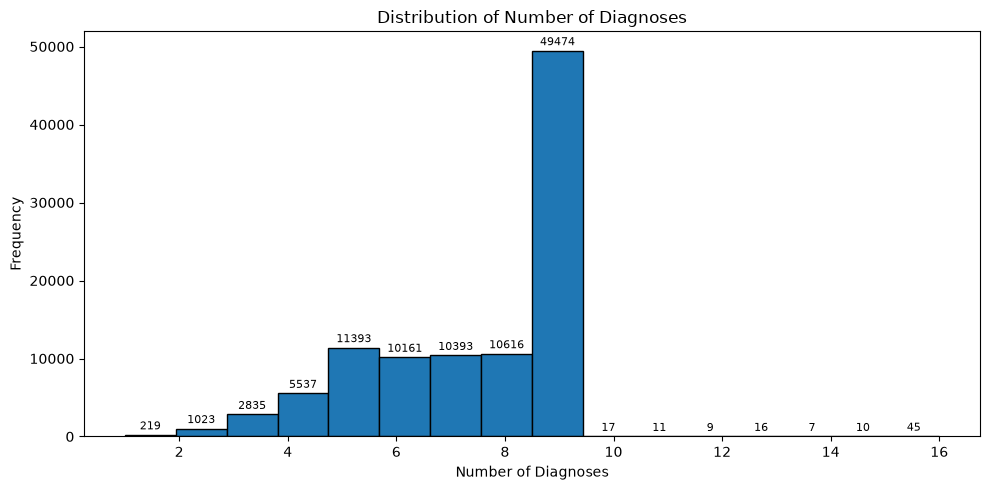

In [38]:
# Visualize the distribution of the number of diagnoses
# and display frequency values above each histogram bar.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

counts, bin_edges, bars = ax.hist(
    df["number_diagnoses"],
    bins=16,
    edgecolor="black"
)

# Display frequencies above the bars
ax.bar_label(bars, padding=2, fmt="%.0f", fontsize=8)

ax.set_title("Distribution of Number of Diagnoses")
ax.set_xlabel("Number of Diagnoses")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 6.11.6 Number of Diagnoses Distribution

A histogram was plotted to examine the distribution of `number_diagnoses` across all hospital encounters.

#### Observations

- The highest frequency occurs at **9 diagnoses**, with 49,474 encounters.
- Most encounters have between **5 and 9 diagnoses**.
- The frequency decreases considerably for diagnosis counts below 5.
- Very few encounters have more than 9 diagnoses.
- The distribution is concentrated around 9 diagnoses, with a relatively small number of encounters having fewer or more diagnoses.
- The feature has a **discrete numerical distribution**, since diagnosis counts represent whole numbers.

#### Preprocessing Considerations

- Retain `number_diagnoses` as a numerical feature.
- No missing values or invalid counts were indicated in the previous descriptive statistics.
- Apply numerical scaling during preprocessing before training the MLP model.

--------------------------------------------------------------------------------------------------------

### Medication feature analysis

In [39]:
# Purpose: Compare the number of laboratory procedures across
# the three readmission categories using descriptive statistics.

lab_procedure_summary = df.groupby("readmitted")["num_lab_procedures"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

lab_procedure_summary

,count,mean,median,min,max,std
readmitted,,,,,,
<30,11357,44.23,45.0,1,132,19.28
>30,35545,43.84,45.0,1,129,19.57
NO,54864,42.38,44.0,1,126,19.80


### 6.11.7 Laboratory Procedure Analysis

The descriptive statistics of `num_lab_procedures` were analyzed across the three readmission categories to understand differences in laboratory procedures performed during hospital encounters.

#### Observations

- **Early readmission (`<30`):**
  - Average laboratory procedure count is **44.23**.
  - Median is 45 procedures.
  - Standard deviation is 19.28.

- **Readmission after 30 days (`>30`):**
  - Average laboratory procedure count is **43.84**.
  - Median is 45 procedures.
  - Standard deviation is 19.57.

- **No readmission (`NO`):**
  - Average laboratory procedure count is **42.38**.
  - Median is 44 procedures.
  - Standard deviation is 19.80.

- Encounters associated with readmission have slightly higher average laboratory procedure counts.
- The median values are similar across all three categories.
- All categories show considerable variation in the number of laboratory procedures performed.

#### Preprocessing Considerations

- `num_lab_procedures` is a **numerical feature** and should be retained for initial model development.
- Investigate its distribution and potential extreme values during numerical feature analysis.
- Apply appropriate numerical scaling before training the MLP model.

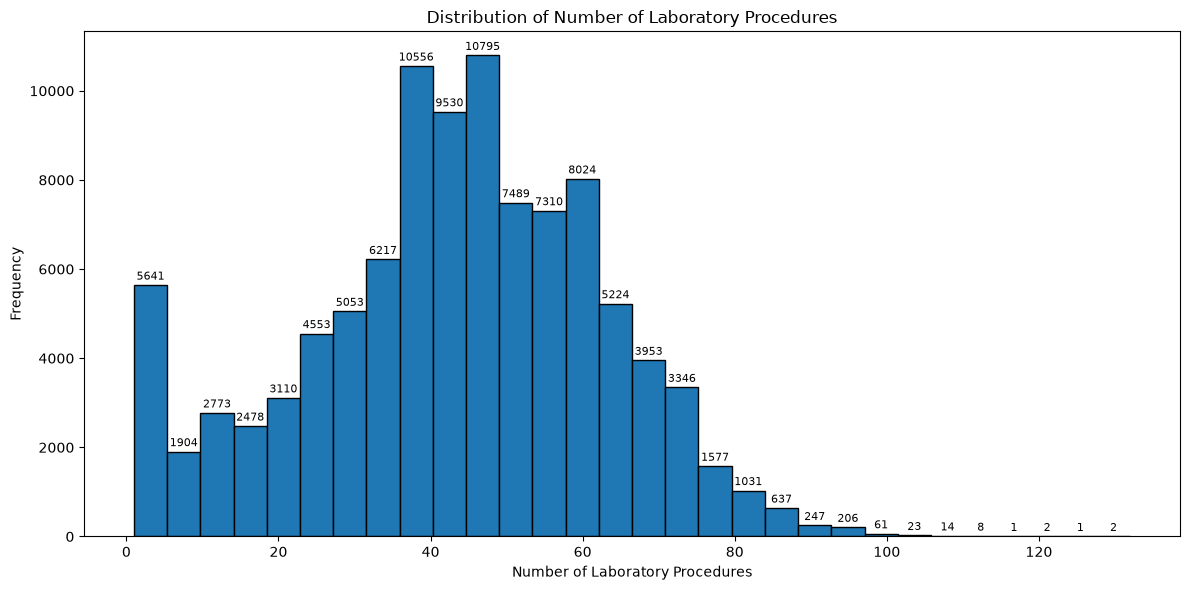

In [40]:
# Purpose: Visualize the distribution of laboratory procedures
# and display frequency values above each histogram bar.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

counts, bin_edges, bars = ax.hist(
    df["num_lab_procedures"],
    bins=30,
    edgecolor="black"
)

# Display frequencies above the bars
ax.bar_label(bars, padding=2, fmt="%.0f", fontsize=8)

ax.set_title("Distribution of Number of Laboratory Procedures")
ax.set_xlabel("Number of Laboratory Procedures")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 6.11.8 Laboratory Procedure Distribution

A histogram was plotted to examine the distribution of `num_lab_procedures` across all hospital encounters.

#### Observations

- Most encounters involve approximately **30–65 laboratory procedures**.
- The highest frequency occurs around the **45–50 procedure range**, with 10,795 encounters in the corresponding bin.
- A noticeable number of encounters have very few laboratory procedures, particularly around 1–5 procedures.
- The frequency gradually decreases as the number of laboratory procedures increases beyond approximately 65.
- A small number of encounters have more than 100 laboratory procedures, with the maximum reaching approximately 132.
- The distribution has a relatively broad spread, with a **long right tail**.

#### Preprocessing Considerations

- Retain `num_lab_procedures` as a numerical feature.
- Investigate unusually high values during outlier analysis before deciding whether any treatment is required.
- Apply appropriate numerical scaling before training the MLP model.

-------------------------------------------------------------------------------------------------------------------------

### 6.11.9 Number of Procedures Analysis

In [41]:
# Purpose: Compare the number of procedures across the three
# readmission categories using descriptive statistics.

procedure_count_summary = df.groupby("readmitted")["num_procedures"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

procedure_count_summary

,count,mean,median,min,max,std
readmitted,,,,,,
<30,11357,1.28,1.0,0,6,1.64
>30,35545,1.25,1.0,0,6,1.67
NO,54864,1.41,1.0,0,6,1.74


### 6.11.9 Number of Procedures Analysis

The descriptive statistics of `num_procedures` were analyzed across the three readmission categories to understand differences in the number of procedures performed during hospital encounters.

#### Observations

- **Early readmission (`<30`):**
  - Average procedure count is **1.28**.
  - Median is 1 procedure.
  - Standard deviation is 1.64.

- **Readmission after 30 days (`>30`):**
  - Average procedure count is **1.25**.
  - Median is 1 procedure.
  - Standard deviation is 1.67.

- **No readmission (`NO`):**
  - Average procedure count is **1.41**.
  - Median is 1 procedure.
  - Standard deviation is 1.74.

- The average procedure count is slightly higher in the **NO readmission** category.
- All three categories have the same minimum and maximum values, ranging from 0 to 6 procedures.
- The median is identical across all readmission categories, indicating similar central values.

#### Preprocessing Considerations

- `num_procedures` is a **numerical feature** and should be retained for initial model development.
- Investigate its distribution before deciding whether any transformation is necessary.
- Apply appropriate numerical scaling before training the MLP model. 

------------------------------------------------------------------------------------------------------------------

### Procedure count distribution

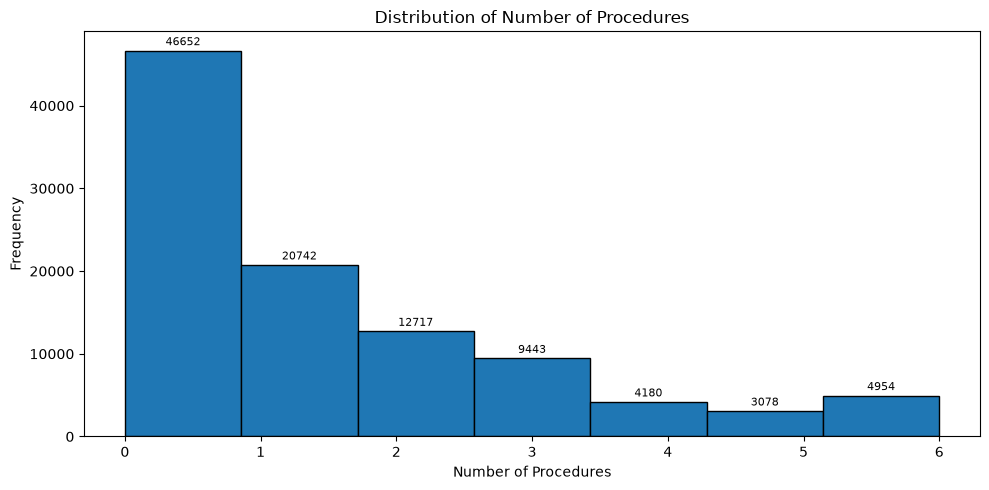

In [42]:
# Purpose: Visualize the distribution of procedure counts
# and display frequency values above each histogram bar.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

counts, bin_edges, bars = ax.hist(
    df["num_procedures"],
    bins=7,
    edgecolor="black"
)

# Display frequencies above the bars
ax.bar_label(bars, padding=2, fmt="%.0f", fontsize=8)

ax.set_title("Distribution of Number of Procedures")
ax.set_xlabel("Number of Procedures")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 6.11.10 Number of Procedures Distribution

A histogram was plotted to examine the distribution of `num_procedures` across all hospital encounters.

#### Observations

- The highest frequency occurs at **0 procedures**, with 46,652 encounters.
- Approximately 20,742 encounters involve 1 procedure.
- The frequency decreases as the number of procedures increases.
- Most encounters involve **0–2 procedures**.
- Only a relatively small number of encounters involve 4 or more procedures.
- The distribution is **right-skewed**, with fewer encounters having higher procedure counts.
- The feature contains discrete integer values ranging from 0 to 6.

#### Preprocessing Considerations

- Retain `num_procedures` as a numerical feature.
- No immediate transformation appears necessary based on the observed distribution.
- Apply numerical scaling during preprocessing before training the MLP model.

--------------------------------------------------------------------------------------------------------------------------

### Laboratory test results

In [43]:
# Purpose: Analyze HbA1c test result categories across
# the three readmission categories using row-wise percentages.

a1c_summary = pd.crosstab(
    df["A1Cresult"],
    df["readmitted"],
    normalize="index"
) * 100

a1c_summary.round(2)

readmitted,<30,>30,NO
A1Cresult,,,
>7,10.05,34.10,55.85
>8,9.87,35.31,54.82
Norm,9.66,32.04,58.30


### 6.11.11 HbA1c Test Result Analysis

The relationship between `A1Cresult` and the three readmission categories was analyzed using row-wise percentages.

#### Observations

- **HbA1c result `>7`:**
  - 10.05% of encounters resulted in readmission within 30 days.
  - 34.10% resulted in readmission after 30 days.
  - 55.85% had no readmission.

- **HbA1c result `>8`:**
  - 9.87% resulted in readmission within 30 days.
  - 35.31% resulted in readmission after 30 days.
  - 54.82% had no readmission.

- **Normal HbA1c (`Norm`):**
  - 9.66% resulted in readmission within 30 days.
  - 32.04% resulted in readmission after 30 days.
  - 58.30% had no readmission.

- The `>7` category has the highest percentage of early readmission among the three displayed categories.
- The `>8` category has the highest percentage of readmission after 30 days.
- The `Norm` category has the highest percentage of encounters without readmission.

#### Preprocessing Considerations

- `A1Cresult` is a **categorical feature** and should be encoded appropriately.
- The feature contains substantial missingness, as identified during initial data quality analysis.
- Investigate missing values before deciding whether to impute them or retain a separate missing category.
- Retain the feature initially and evaluate its usefulness during model development. 

---------------------------------------------------------------------------------------------------------------------------------

### HbA1c category distribution

In [44]:
# Purpose: Count the occurrences of each HbA1c test result category,
# including missing values.

a1c_counts = df["A1Cresult"].value_counts(dropna=False)

a1c_counts

A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64

### 6.11.12 HbA1c Category Distribution

The frequency distribution of `A1Cresult` was analyzed to understand the availability of HbA1c test results across hospital encounters.

#### Observations

- **Missing values (`NaN`):**
  - 84,748 encounters have missing HbA1c results.
  - Approximately **83.28%** of the dataset is missing this feature.

- **HbA1c result `>8`:**
  - 8,216 encounters (approximately 8.07%).

- **Normal HbA1c (`Norm`):**
  - 4,990 encounters (approximately 4.90%).

- **HbA1c result `>7`:**
  - 3,812 encounters (approximately 3.75%).

- Missing HbA1c results represent the **majority of encounters**, indicating substantial missingness in this feature.
- Only a relatively small proportion of encounters contain recorded HbA1c results.

#### Preprocessing Considerations

- Investigate the reason for the high missingness before selecting a treatment strategy.
- Avoid dropping all records with missing HbA1c results because this would remove a substantial portion of the dataset.
- Consider whether to retain the feature with a missing-value indicator or evaluate its usefulness after preprocessing.
- Preserve the original values and handle missingness consistently during preprocessing.

-----------------------------------------------------------------------------------------------------------------------------

### Maximum glucose serum result 

In [45]:
# Purpose: Analyze maximum glucose serum test result categories
# across the three readmission categories using row-wise percentages.

max_glucose_summary = pd.crosstab(
    df["max_glu_serum"],
    df["readmitted"],
    normalize="index"
) * 100

max_glucose_summary.round(2)

readmitted,<30,>30,NO
max_glu_serum,,,
>200,12.46,35.69,51.85
>300,14.32,41.22,44.46
Norm,11.36,34.08,54.56


### 6.11.13 Maximum Glucose Serum Analysis

The relationship between `max_glu_serum` and the three readmission categories was analyzed using row-wise percentages.

#### Observations

- **Glucose serum result `>200`:**
  - 12.46% of encounters resulted in readmission within 30 days.
  - 35.69% resulted in readmission after 30 days.
  - 51.85% had no readmission.

- **Glucose serum result `>300`:**
  - 14.32% resulted in readmission within 30 days.
  - 41.22% resulted in readmission after 30 days.
  - 44.46% had no readmission.

- **Normal glucose serum result (`Norm`):**
  - 11.36% resulted in readmission within 30 days.
  - 34.08% resulted in readmission after 30 days.
  - 54.56% had no readmission.

- The `>300` category has the highest percentage of readmission in both readmission groups.
- The percentage of encounters without readmission is lowest in the `>300` category.

#### Preprocessing Considerations

- `max_glu_serum` is a **categorical feature** and should be encoded appropriately.
- The feature has substantial missingness, as identified during initial data quality analysis.
- Investigate missing values before deciding on imputation or a separate missing category.
- Retain the feature initially and evaluate its usefulness during model development. 

-----------------------------------------------------------------------------------------------------------------------------------------

### Maximum glucose serum category distribution

In [46]:
# Purpose: Count the occurrences of each maximum glucose serum category,
# including missing values.

max_glucose_counts = df["max_glu_serum"].value_counts(dropna=False)

max_glucose_counts

max_glu_serum
NaN     96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64

### 6.11.14 Maximum Glucose Serum Category Distribution

The frequency distribution of `max_glu_serum` was analyzed to understand the availability of glucose serum test results across hospital encounters.

#### Observations

- **Missing values (`NaN`):**
  - 96,420 encounters have missing glucose serum results.
  - Approximately **94.75%** of the dataset is missing this feature.

- **Normal glucose serum (`Norm`):**
  - 2,597 encounters (approximately 2.55%).

- **Glucose serum `>200`:**
  - 1,485 encounters (approximately 1.46%).

- **Glucose serum `>300`:**
  - 1,264 encounters (approximately 1.24%).

- Missing glucose serum results represent the **overwhelming majority** of encounters.
- Only a small proportion of encounters contain recorded glucose serum test results.

#### Preprocessing Considerations

- Investigate the reason for the high missingness before selecting a treatment strategy.
- Avoid dropping all records with missing glucose serum results because this would remove a substantial portion of the dataset.
- Consider retaining the feature with an appropriate missing-value indicator or evaluating its usefulness after preprocessing.
- Preserve the original values and handle missingness consistently during preprocessing.

--------------------------------------------------------------------------------------------------------------------

### Previous hospital utilization

In [47]:
# Purpose: Compare previous inpatient visit counts across
# the three readmission categories using descriptive statistics.

inpatient_visit_summary = df.groupby("readmitted")["number_inpatient"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

inpatient_visit_summary

,count,mean,median,min,max,std
readmitted,,,,,,
<30,11357,1.22,0.0,0,21,1.95
>30,35545,0.84,0.0,0,19,1.39
NO,54864,0.38,0.0,0,16,0.86


### 6.11.15 Previous Inpatient Visit Analysis

The descriptive statistics of `number_inpatient` were analyzed across the three readmission categories to understand the relationship between previous inpatient visits and readmission patterns.

#### Observations

- **Early readmission (`<30`):**
  - Average previous inpatient visits: **1.22**.
  - Median is 0 visits.
  - Standard deviation is 1.95.

- **Readmission after 30 days (`>30`):**
  - Average previous inpatient visits: **0.84**.
  - Median is 0 visits.
  - Standard deviation is 1.39.

- **No readmission (`NO`):**
  - Average previous inpatient visits: **0.38**.
  - Median is 0 visits.
  - Standard deviation is 0.86.

- The early readmission category has the **highest average number of previous inpatient visits**.
- The average inpatient visit count decreases across the categories from `<30` to `>30` to `NO`.
- All three categories have a median of 0, indicating that many encounters had no previous inpatient visits.
- The maximum values differ across categories, reaching 21, 19, and 16 respectively.

#### Preprocessing Considerations

- `number_inpatient` is a **numerical feature** and should be retained for initial model development.
- The feature is count-based and may have a right-skewed distribution.
- Investigate its distribution and extreme values before deciding whether transformation is necessary.
- Apply appropriate numerical scaling before training the MLP model. 

--------------------------------------------------------------------------------------------------------------------------

### Previous inpatient visit distribution

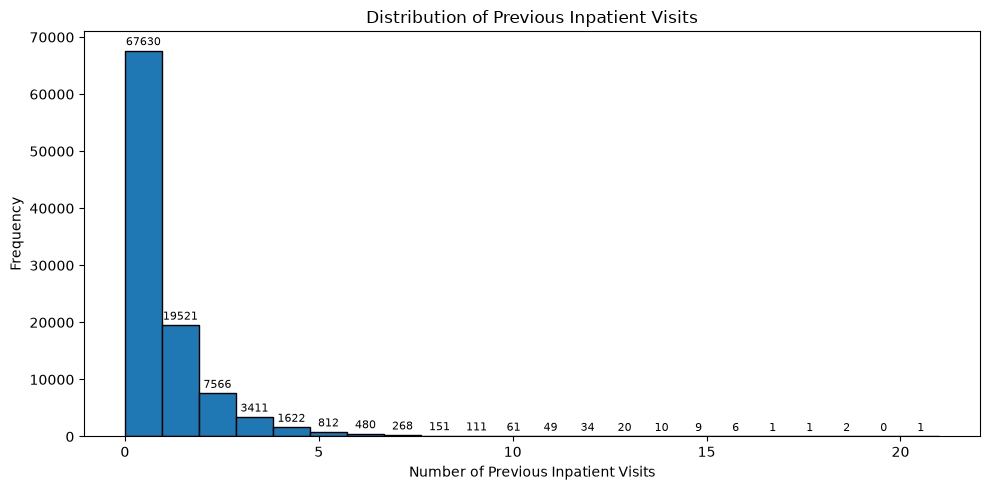

In [48]:
# Purpose: Visualize the distribution of previous inpatient visits
# and display frequency values above each histogram bar.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

counts, bin_edges, bars = ax.hist(
    df["number_inpatient"],
    bins=22,
    edgecolor="black"
)

# Display frequencies above the bars
ax.bar_label(bars, padding=2, fmt="%.0f", fontsize=8)

ax.set_title("Distribution of Previous Inpatient Visits")
ax.set_xlabel("Number of Previous Inpatient Visits")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 6.11.16 Previous Inpatient Visit Distribution

A histogram was plotted to examine the distribution of `number_inpatient` across all hospital encounters.

#### Observations

- The majority of encounters have **0 previous inpatient visits**, with 67,630 encounters.
- Approximately 19,521 encounters have 1 previous inpatient visit.
- The frequency decreases substantially as the number of previous inpatient visits increases.
- Most encounters have **0–2 previous inpatient visits**.
- Only a small number of encounters have more than 10 previous inpatient visits.
- The distribution is **strongly right-skewed**, with a long tail extending to 21 visits.
- Previous inpatient visits are concentrated at lower values, with relatively few encounters having frequent hospitalizations.

#### Preprocessing Considerations

- Retain `number_inpatient` as a numerical feature.
- The feature is highly right-skewed; investigate its distribution during preprocessing.
- Consider appropriate scaling or transformation if required.
- Preserve the original feature values until preprocessing decisions are finalized.

-----------------------------------------------------------------------------------------------------------------------------------

### Previous outpatient visits

In [49]:
# Purpose: Compare previous outpatient visit counts across
# the three readmission categories using descriptive statistics.

outpatient_visit_summary = df.groupby("readmitted")["number_outpatient"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

outpatient_visit_summary

,count,mean,median,min,max,std
readmitted,,,,,,
<30,11357,0.44,0.0,0,40,1.30
>30,35545,0.50,0.0,0,42,1.54
NO,54864,0.27,0.0,0,36,1.03


### 6.11.17 Previous Outpatient Visit Analysis

The descriptive statistics of `number_outpatient` were analyzed across the three readmission categories to understand differences in previous outpatient visits.

#### Observations

- **Early readmission (`<30`):**
  - Average previous outpatient visits: **0.44**.
  - Median is 0 visits.
  - Standard deviation is 1.30.

- **Readmission after 30 days (`>30`):**
  - Average previous outpatient visits: **0.50**.
  - Median is 0 visits.
  - Standard deviation is 1.54.

- **No readmission (`NO`):**
  - Average previous outpatient visits: **0.27**.
  - Median is 0 visits.
  - Standard deviation is 1.03.

- The `>30` category has the highest average number of previous outpatient visits.
- The `NO` category has the lowest average.
- All three categories have a median of 0, indicating that many encounters had no previous outpatient visits.
- The maximum outpatient visit counts range from 36 to 42.

#### Preprocessing Considerations

- `number_outpatient` is a **numerical feature** and should be retained for initial model development.
- The feature is likely concentrated at lower values, with some high visit counts.
- Investigate its distribution and potential extreme values during preprocessing.
- Apply appropriate numerical scaling before training the MLP model. 

-----------------------------------------------------------------------------------------------------------------------------

### Previous emergency visits

In [50]:
# Purpose: Compare previous emergency visit counts across
# the three readmission categories using descriptive statistics.

emergency_visit_summary = df.groupby("readmitted")["number_emergency"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

emergency_visit_summary

,count,mean,median,min,max,std
readmitted,,,,,,
<30,11357,0.36,0.0,0,64,1.37
>30,35545,0.28,0.0,0,76,1.19
NO,54864,0.11,0.0,0,37,0.52


### 6.11.18 Previous Emergency Visit Analysis

The descriptive statistics of `number_emergency` were analyzed across the three readmission categories to understand differences in previous emergency visits.

#### Observations

- **Early readmission (`<30`):**
  - Average previous emergency visits: **0.36**.
  - Median is 0 visits.
  - Standard deviation is 1.37.

- **Readmission after 30 days (`>30`):**
  - Average previous emergency visits: **0.28**.
  - Median is 0 visits.
  - Standard deviation is 1.19.

- **No readmission (`NO`):**
  - Average previous emergency visits: **0.11**.
  - Median is 0 visits.
  - Standard deviation is 0.52.

- The early readmission category has the **highest average number of previous emergency visits**.
- The average emergency visit count decreases across the categories from `<30` to `>30` to `NO`.
- All three categories have a median of 0, indicating that many encounters had no previous emergency visits.
- The maximum values vary considerably, ranging from 37 to 76 visits.

#### Preprocessing Considerations

- `number_emergency` is a **numerical feature** and should be retained for initial model development.
- The feature may contain a right-skewed distribution with relatively few encounters having high emergency visit counts.
- Investigate extreme values during preprocessing.
- Apply appropriate numerical scaling before training the MLP model. 

------------------------------------------------------------------------------------------------------------------------------

### Emergency visit distribution

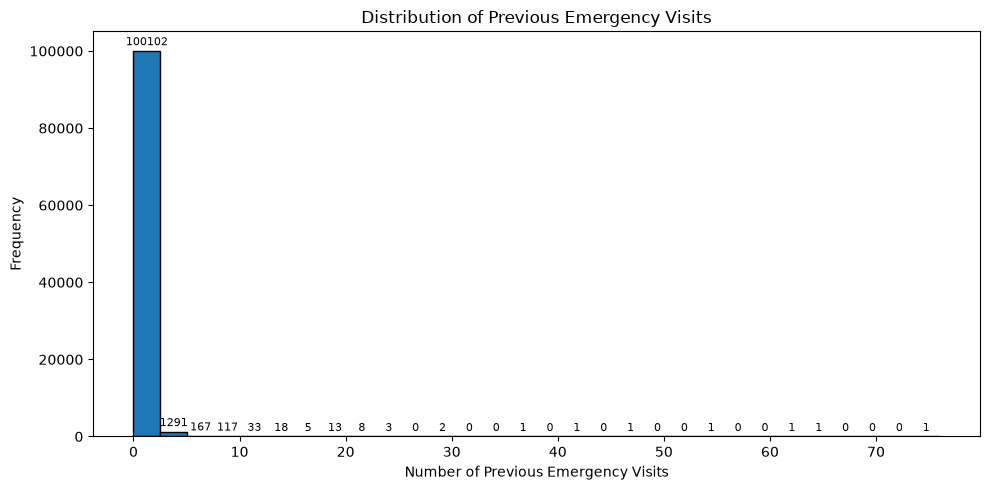

In [51]:
# Purpose: Visualize the distribution of previous emergency visits
# and display frequency values above each histogram bar.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

counts, bin_edges, bars = ax.hist(
    df["number_emergency"],
    bins=30,
    edgecolor="black"
)

# Display frequencies above the bars
ax.bar_label(bars, padding=2, fmt="%.0f", fontsize=8)

ax.set_title("Distribution of Previous Emergency Visits")
ax.set_xlabel("Number of Previous Emergency Visits")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 6.11.19 Previous Emergency Visit Distribution

A histogram was plotted to examine the distribution of `number_emergency` across all hospital encounters.

#### Observations

- The overwhelming majority of encounters have **0 previous emergency visits**, with 100,102 encounters.
- Only a small number of encounters have one or more previous emergency visits.
- The frequency decreases sharply as the number of previous emergency visits increases.
- Very few encounters have more than 10 previous emergency visits.
- The distribution is **extremely right-skewed**, with a long tail extending to 76 visits.
- Most observations are concentrated at zero, while high emergency visit counts are rare.

#### Preprocessing Considerations

- Retain `number_emergency` as a numerical feature.
- Investigate its highly skewed distribution during preprocessing.
- Consider appropriate scaling or transformation if required.
- Preserve the original feature values until preprocessing decisions are finalized. 

----------------------------------------------------------------------------------------------

### Hospital stay duration

In [52]:
# Purpose: Compare hospital stay duration across the three
# readmission categories using descriptive statistics.

hospital_stay_summary = df.groupby("readmitted")["time_in_hospital"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

hospital_stay_summary

,count,mean,median,min,max,std
readmitted,,,,,,
<30,11357,4.77,4.0,1,14,3.03
>30,35545,4.50,4.0,1,14,2.99
NO,54864,4.25,3.0,1,14,2.96


### 6.11.20 Hospital Stay Duration Analysis

The descriptive statistics of `time_in_hospital` were analyzed across the three readmission categories to understand differences in hospital stay duration.

#### Observations

- **Early readmission (`<30`):**
  - Average hospital stay: **4.77 days**.
  - Median stay is 4 days.
  - Standard deviation is 3.03.

- **Readmission after 30 days (`>30`):**
  - Average hospital stay: **4.50 days**.
  - Median stay is 4 days.
  - Standard deviation is 2.99.

- **No readmission (`NO`):**
  - Average hospital stay: **4.25 days**.
  - Median stay is 3 days.
  - Standard deviation is 2.96.

- The early readmission category has the **highest average hospital stay duration**.
- Average hospital stay decreases across the categories from `<30` to `>30` to `NO`.
- All three categories have the same minimum and maximum stay durations, ranging from 1 to 14 days.
- The median hospital stay is relatively similar across the categories.

#### Preprocessing Considerations

- `time_in_hospital` is a **numerical feature** and should be retained for initial model development.
- Investigate its distribution during numerical feature analysis.
- Apply appropriate numerical scaling before training the MLP model.
- Consider prediction timing when determining whether this feature is available for the intended prediction scenario.

-------------------------------------

### Hospital stay duration distribution

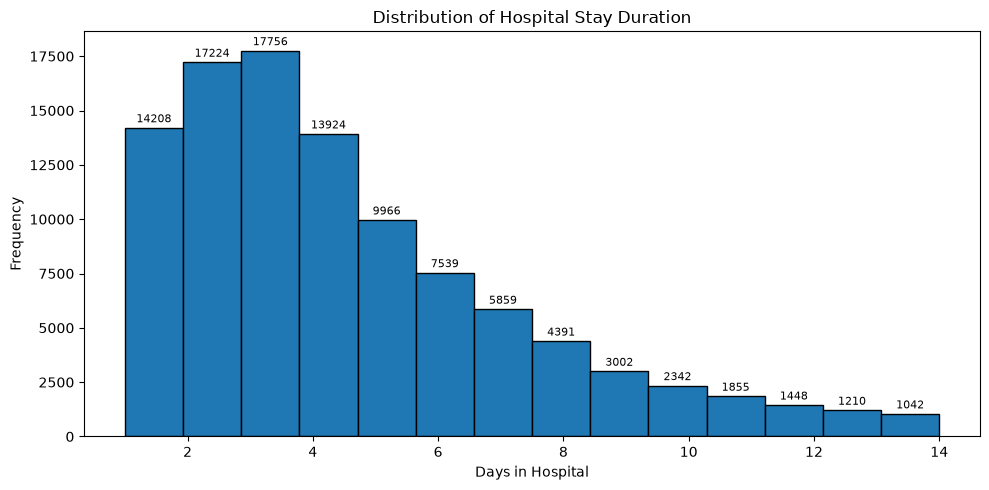

In [53]:
# Purpose: Visualize the distribution of hospital stay duration
# and display frequency values above each histogram bar.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

counts, bin_edges, bars = ax.hist(
    df["time_in_hospital"],
    bins=14,
    edgecolor="black"
)

# Display frequencies above the bars
ax.bar_label(bars, padding=2, fmt="%.0f", fontsize=8)

ax.set_title("Distribution of Hospital Stay Duration")
ax.set_xlabel("Days in Hospital")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 6.11.21 Hospital Stay Duration Distribution

A histogram was plotted to examine the distribution of `time_in_hospital` across all hospital encounters.

#### Observations

- The highest frequency occurs around **3 days**, with 17,756 encounters in the corresponding bin.
- Most encounters involve approximately **1–5 days** of hospitalization.
- The frequency gradually decreases as hospital stay duration increases.
- Encounters with longer hospital stays, particularly 10–14 days, are comparatively less frequent.
- The distribution shows a **right-skewed pattern**, with fewer encounters having longer hospital stays.
- Hospital stay duration ranges from 1 to 14 days.

#### Preprocessing Considerations

- Retain `time_in_hospital` as a numerical feature.
- Investigate its distribution during numerical feature analysis.
- Apply appropriate numerical scaling before training the MLP model.
- Consider prediction timing when deciding whether this feature is available for the intended prediction scenario. 

-----------------------------------------

In [54]:
# Purpose: Analyze insulin treatment status across the
# three readmission categories using row-wise percentages.

insulin_summary = pd.crosstab(
    df["insulin"],
    df["readmitted"],
    normalize="index"
) * 100

insulin_summary.round(2)

readmitted,<30,>30,NO
insulin,,,
Down,13.90,38.89,47.21
No,10.04,33.66,56.30
Steady,11.13,33.98,54.89
Up,12.99,38.55,48.46


### 6.11.22 Insulin Treatment Analysis

The relationship between `insulin` treatment status and the three readmission categories was analyzed using row-wise percentages.

#### Observations

- **Insulin dosage decreased (`Down`):**
  - 13.90% of encounters resulted in readmission within 30 days.
  - 38.89% resulted in readmission after 30 days.
  - 47.21% had no readmission.

- **No insulin (`No`):**
  - 10.04% resulted in readmission within 30 days.
  - 33.66% resulted in readmission after 30 days.
  - 56.30% had no readmission.

- **Insulin dosage unchanged (`Steady`):**
  - 11.13% resulted in readmission within 30 days.
  - 33.98% resulted in readmission after 30 days.
  - 54.89% had no readmission.

- **Insulin dosage increased (`Up`):**
  - 12.99% resulted in readmission within 30 days.
  - 38.55% resulted in readmission after 30 days.
  - 48.46% had no readmission.

- The `Down` category has the highest percentage of early readmission.
- The `Down` and `Up` categories have higher percentages of readmission after 30 days than the `No` and `Steady` categories.
- The `No` category has the highest percentage of encounters without readmission.

#### Preprocessing Considerations

- `insulin` is a **categorical feature** and should be encoded appropriately.
- Retain the feature for initial model development because it may provide useful treatment-related information.
- Evaluate its usefulness alongside other medication features during model development.

------------------------------------------------------

### Insulin category distribution

In [55]:
# Purpose: Count the occurrences of each insulin treatment category.

insulin_counts = df["insulin"].value_counts(dropna=False)

insulin_counts

insulin
No        47383
Steady    30849
Down      12218
Up        11316
Name: count, dtype: int64

### 6.11.23 Insulin Treatment Category Distribution

The frequency distribution of `insulin` was analyzed to understand the prevalence of different insulin treatment patterns across hospital encounters.

#### Observations

- **No insulin (`No`):** 47,383 encounters, representing approximately 46.56% of the dataset.
- **Insulin dosage unchanged (`Steady`):** 30,849 encounters, approximately 30.31%.
- **Insulin dosage decreased (`Down`):** 12,218 encounters, approximately 12.01%.
- **Insulin dosage increased (`Up`):** 11,316 encounters, approximately 11.12%.

- The `No` category represents the largest proportion of encounters.
- The `Steady` category is the second most frequent insulin treatment pattern.
- The `Down` and `Up` categories represent relatively smaller proportions of encounters.
- All four categories are represented in the dataset.

#### Preprocessing Considerations

- `insulin` is a **categorical feature** and should be encoded appropriately.
- Retain the feature for initial model development.
- Consider its distribution when evaluating model performance across treatment categories. 

--------------------------------------------------------------------------------------------------------

### Final EDA section

In [56]:
# Purpose: Count the occurrences of medication changes
# and unchanged medication status.

medication_change_counts = df["change"].value_counts(dropna=False)

medication_change_counts

change
No    54755
Ch    47011
Name: count, dtype: int64

### 6.11.24 Medication Change Category Distribution

The frequency distribution of `change` was analyzed to understand how often medication changes occurred during hospital encounters.

#### Observations

- **No medication change (`No`):**
  - 54,755 encounters, approximately **53.80%** of the dataset.

- **Medication changed (`Ch`):**
  - 47,011 encounters, approximately **46.20%** of the dataset.

- Encounters without medication changes represent a slightly larger proportion of the dataset.
- Both categories are well represented, with no severe imbalance between them.

#### Preprocessing Considerations

- `change` is a **categorical feature** and should be encoded appropriately.
- Retain the feature for initial model development.
- No rare-category issue is observed because both categories have substantial representation.

------------------------------------------------------------------------------------------------

### Correlation analysis 

In [57]:
# Purpose: Create a separate dataset and convert the target into binary format for correlation analysis.

# Create a temporary copy
df_corr = df.copy()

# Convert readmission target into binary format
df_corr["readmitted_binary"] = df_corr["readmitted"].map({
    "<30": 1,
    ">30": 0,
    "NO": 0
})

# Verify target conversion
print(df_corr["readmitted_binary"].value_counts())
print("\nMissing target values:", df_corr["readmitted_binary"].isnull().sum())

readmitted_binary
0    90409
1    11357
Name: count, dtype: int64

Missing target values: 0


In [58]:
# Purpose: Identify numerical features for correlation analysis.

# Select numerical columns
numerical_columns = df_corr.select_dtypes(include=["number"]).columns.tolist()

# Exclude identifier columns and target-related columns
excluded_columns = [
    "encounter_id",
    "patient_nbr",
    "readmitted_binary"
]

numerical_columns = [
    col for col in numerical_columns
    if col not in excluded_columns
]

print("Number of numerical features:", len(numerical_columns))
print("\nNumerical features:")
print(numerical_columns)

Number of numerical features: 11

Numerical features:
['admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


In [59]:
# Purpose: Calculate Pearson correlations among numerical features and the readmission target.

# Include the binary target for analysis
correlation_columns = numerical_columns + ["readmitted_binary"]

# Calculate correlation matrix
correlation_matrix = df_corr[correlation_columns].corr()

# Display correlations with the target
target_correlation = (
    correlation_matrix["readmitted_binary"]
    .drop("readmitted_binary")
    .sort_values(key=abs, ascending=False)
)

print("Correlation with early readmission:\n")
display(target_correlation)

Correlation with early readmission:



number_inpatient            0.165147
number_emergency            0.060747
discharge_disposition_id    0.050560
number_diagnoses            0.049524
time_in_hospital            0.044199
num_medications             0.038432
num_lab_procedures          0.020364
number_outpatient           0.018893
num_procedures             -0.012227
admission_type_id          -0.011651
admission_source_id         0.005820
Name: readmitted_binary, dtype: float64

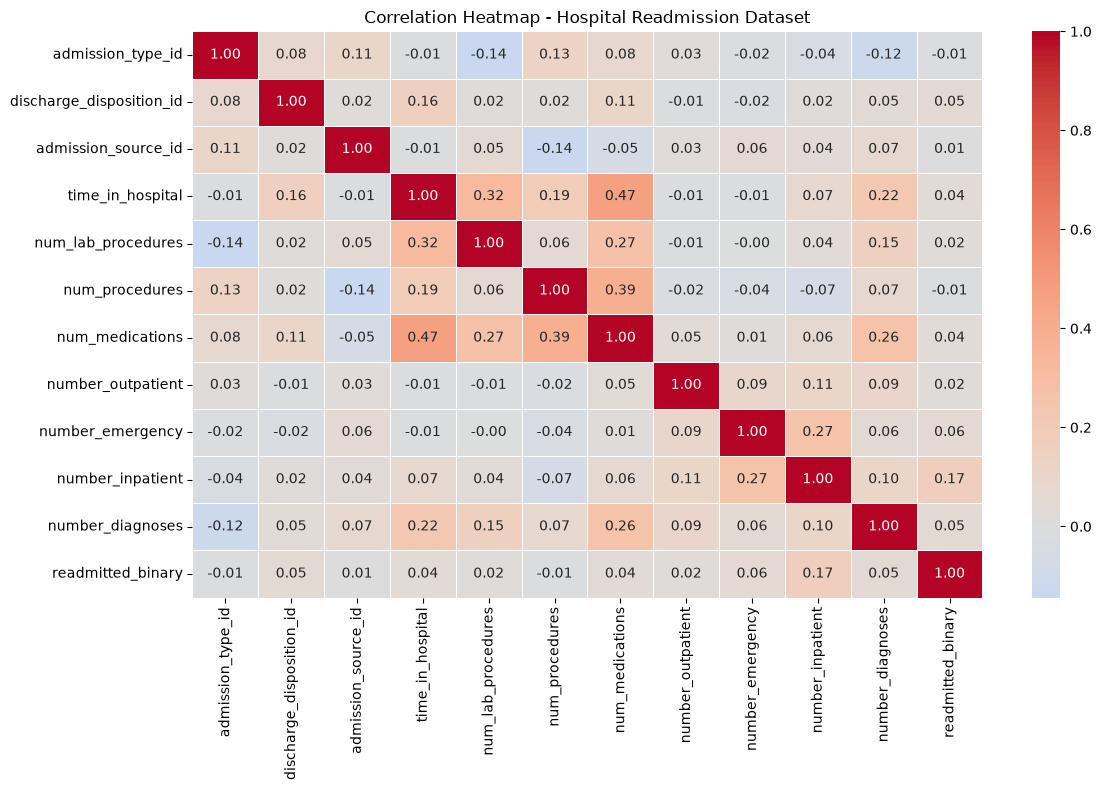

In [60]:
# Purpose: Visualize relationships among numerical features using a correlation heatmap.

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap - Hospital Readmission Dataset")
plt.tight_layout()
plt.show()

### Analyze missingness patterns

In [61]:
# Purpose: Identify missing values and calculate their percentage in each column.

# Create a missing-value summary
missing_summary = pd.DataFrame({
    "Missing_Count": df_corr.isnull().sum(),
    "Missing_Percentage": (df_corr.isnull().mean() * 100).round(2)
})

# Display only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values(by="Missing_Percentage", ascending=False)

display(missing_summary)

,Missing_Count,Missing_Percentage
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
admission_type_name,5291,5.20


### Missingness indicator analysis

In [62]:
# Purpose: Check whether missing values are associated with early readmission.

# Features to investigate
missing_features = [
    "max_glu_serum",
    "A1Cresult",
    "admission_type_name"
]

# Analyze missingness against readmission
missingness_results = []

for col in missing_features:

    # Create a temporary indicator
    missing_indicator = df_corr[col].isnull()

    # Calculate early readmission rate
    readmission_rate = (
        df_corr.groupby(missing_indicator)["readmitted_binary"]
        .mean() * 100
    )

    missingness_results.append({
        "Feature": col,
        "Missing_Readmission_Rate": readmission_rate.get(True, np.nan),
        "Available_Readmission_Rate": readmission_rate.get(False, np.nan)
    })

missingness_df = pd.DataFrame(missingness_results)

display(missingness_df.round(2))

,Feature,Missing_Readmission_Rate,Available_Readmission_Rate
0,max_glu_serum,11.09,12.36
1,A1Cresult,11.42,9.85
2,admission_type_name,11.08,11.16


### Statistical significance of missingness

In [63]:
# Purpose: Test whether missingness is statistically associated with early readmission.

from scipy.stats import chi2_contingency
import numpy as np

missingness_tests = []

for col in missing_features:

    # Create missingness indicator
    missing_indicator = df_corr[col].isnull()

    # Create contingency table
    contingency_table = pd.crosstab(
        missing_indicator,
        df_corr["readmitted_binary"]
    )

    # Chi-square test
    chi2, p_value, _, _ = chi2_contingency(contingency_table)

    # Calculate Cramer's V effect size
    n = contingency_table.to_numpy().sum()
    min_dimension = min(contingency_table.shape) - 1

    cramers_v = np.sqrt(chi2 / (n * min_dimension))

    missingness_tests.append({
        "Feature": col,
        "Chi_Square": chi2,
        "P_Value": p_value,
        "Cramers_V": cramers_v
    })

missingness_tests_df = pd.DataFrame(missingness_tests)

display(missingness_tests_df.round(6))

,Feature,Chi_Square,P_Value,Cramers_V
0,max_glu_serum,8.128580,0.004357,0.008937
1,A1Cresult,35.295047,0.000000,0.018623
2,admission_type_name,0.031711,0.858663,0.000558


### Standardize hidden missing values

In [64]:
# Purpose: Convert common hidden missing-value representations into actual NaN values.

# Create a separate preprocessing copy
df_preprocessed = df.copy()

# Define recognized missing-value tokens
missing_tokens = [
    "?",
    "NaN",
    "nan",
    "NAN",
    "None",
    "none",
    "NULL",
    "null",
    ""
]

# Replace recognized tokens with NaN
df_preprocessed.replace(
    missing_tokens,
    np.nan,
    inplace=True
)

print("Missing-value standardization completed.")

Missing-value standardization completed.


### Updated missing-value summary

In [65]:
# Purpose: Identify all missing values after standardizing hidden missing tokens.

missing_summary = pd.DataFrame({
    "Missing_Count": df_preprocessed.isnull().sum(),
    "Missing_Percentage": (
        df_preprocessed.isnull().mean() * 100
    ).round(2)
})

# Display columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
admission_type_name,5291,5.20
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


### Identify admission type IDs with missing descriptions

In [66]:
# Purpose: Investigate admission type IDs that have missing mapped descriptions.

admission_mapping_check = (
    df_preprocessed[
        df_preprocessed["admission_type_name"].isnull()
    ]["admission_type_id"]
    .value_counts()
    .sort_index()
)

display(admission_mapping_check)

admission_type_id
6    5291
Name: count, dtype: int64

### Resolve the admission type mapping 

In [67]:
# Purpose: Assign a meaningful category to admission type ID 6.

df_preprocessed["admission_type_name"] = (
    df_preprocessed["admission_type_name"]
    .fillna("Unknown/Not Available")
)

# Verify the mapping
display(
    df_preprocessed[
        ["admission_type_id", "admission_type_name"]
    ]
    .drop_duplicates()
    .sort_values("admission_type_id")
)

,admission_type_id,admission_type_name
1,1,Emergency
5,2,Urgent
6,3,Elective
2043,4,Newborn
3089,5,Not Available
0,6,Unknown/Not Available
45829,7,Trauma Center
7789,8,Not Mapped


### Inspect special categorical values

In [68]:
# Purpose: Identify special categories that may require separate missing-value decisions.

categorical_columns = df_preprocessed.select_dtypes(
    include=["object"]
).columns

special_values = [
    "Unknown/Invalid",
    "Unknown",
    "Not Mapped",
    "Not Available"
]

for col in categorical_columns:

    counts = df_preprocessed[col].value_counts(dropna=False)

    matched_values = counts[
        counts.index.isin(special_values)
    ]

    if not matched_values.empty:
        print(f"\nColumn: {col}")
        display(matched_values)


Column: gender


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_18716\1687558837.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_preprocessed.select_dtypes(


gender
Unknown/Invalid    3
Name: count, dtype: int64


Column: admission_type_name


admission_type_name
Not Available    4785
Not Mapped        320
Name: count, dtype: int64

# 7. Data Preprocessing

In this stage, we will prepare the dataset for Machine Learning by identifying and handling missing values, correcting invalid entries, selecting relevant features, performing feature engineering, encoding categorical variables, and scaling numerical features.

The objective is to improve data quality while preserving meaningful information for the Hospital Readmission Risk Prediction model.

## 7.1 Missing Value and Invalid Value Handling

In this section, we will identify and handle missing values, hidden missing-value representations, and invalid categorical values in the hospital readmission dataset.

### 7.1.1 Standardizing Missing Values

The dataset contains hidden missing values represented by special tokens such as `"?"`, `"None"`, and `"NULL"`.

These values are standardized into `NaN` so that missing-value detection and handling can be performed consistently using Pandas.

In [69]:
# Purpose: Convert common hidden missing-value representations into actual NaN values.

df_preprocessed = df.copy()

missing_tokens = [
    "?", "NaN", "nan", "NAN",
    "None", "none", "NULL", "null", ""
]

df_preprocessed.replace(
    missing_tokens,
    np.nan,
    inplace=True
)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,admission_type_name
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,NO,NaN
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,Up,No,No,No,No,No,Ch,Yes,>30,Emergency
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,Yes,NO,Emergency
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,Up,No,No,No,No,No,Ch,Yes,NO,Emergency
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,Steady,No,No,No,No,No,Ch,Yes,NO,Emergency
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,443847548,100162476,AfricanAmerican,Male,[70-80),NaN,1,3,7,3,...,Down,No,No,No,No,No,Ch,Yes,>30,Emergency
101762,443847782,74694222,AfricanAmerican,Female,[80-90),NaN,1,4,5,5,...,Steady,No,No,No,No,No,No,Yes,NO,Emergency
101763,443854148,41088789,Caucasian,Male,[70-80),NaN,1,1,7,1,...,Down,No,No,No,No,No,Ch,Yes,NO,Emergency
101764,443857166,31693671,Caucasian,Female,[80-90),NaN,2,3,7,10,...,Up,No,No,No,No,No,Ch,Yes,NO,Urgent


In [70]:
# Purpose: Identify all remaining missing values after standardization and invalid-value handling.

final_missing_summary = pd.DataFrame({
    "Missing_Count": df_preprocessed.isnull().sum(),
    "Missing_Percentage": (df_preprocessed.isnull().mean() * 100).round(2)
})

# Keep only columns containing missing values
final_missing_summary = final_missing_summary[
    final_missing_summary["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(final_missing_summary)

,Missing_Count,Missing_Percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
admission_type_name,5291,5.20
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


In [71]:
# Purpose: Verify and correct missing admission type descriptions using their original IDs.

# Check which admission type IDs have missing descriptions
display(
    df_preprocessed.loc[
        df_preprocessed["admission_type_name"].isnull(),
        "admission_type_id"
    ].value_counts(dropna=False)
)

admission_type_id
6    5291
Name: count, dtype: int64

In [72]:
# Purpose: Replace missing admission type descriptions using the verified admission type ID.

df_preprocessed.loc[
    df_preprocessed["admission_type_id"] == 6,
    "admission_type_name"
] = "Unknown/Not Available"

print("Remaining missing admission_type_name values:",
      df_preprocessed["admission_type_name"].isnull().sum())

display(
    df_preprocessed["admission_type_name"].value_counts(dropna=False)
)

Remaining missing admission_type_name values: 0


admission_type_name
Emergency                53990
Elective                 18869
Urgent                   18480
Unknown/Not Available     5291
Not Available             4785
Not Mapped                 320
Trauma Center               21
Newborn                     10
Name: count, dtype: int64

### Updated Missing Value Summary

In [73]:
# Purpose: Recalculate missing values after correcting admission type descriptions.

final_missing_summary = pd.DataFrame({
    "Missing_Count": df_preprocessed.isnull().sum(),
    "Missing_Percentage": (
        df_preprocessed.isnull().mean() * 100
    ).round(2)
})

final_missing_summary = final_missing_summary[
    final_missing_summary["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(final_missing_summary)

,Missing_Count,Missing_Percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


### Drop the weight Feature

In [74]:
# Purpose: Remove the weight feature due to its extremely high missing percentage.

df_preprocessed.drop(
    columns=["weight"],
    inplace=True
)

print("Weight column removed:", "weight" not in df_preprocessed.columns)
print("Updated dataset shape:", df_preprocessed.shape)

Weight column removed: True
Updated dataset shape: (101766, 50)


### Handling `max_glu_serum` column

In [75]:
# Purpose: Examine the distribution of max_glu_serum categories and missing values.

display(
    df_preprocessed["max_glu_serum"]
    .value_counts(dropna=False)
)

print(
    "Missing percentage:",
    round(
        df_preprocessed["max_glu_serum"].isnull().mean() * 100,
        2
    ),
    "%"
)

max_glu_serum
NaN     96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64

Missing percentage: 94.75 %


### Creating an Explicit Missing Category

In [76]:
# Purpose: Preserve missing glucose test information as an explicit categorical value.

df_preprocessed["max_glu_serum"] = (
    df_preprocessed["max_glu_serum"]
    .fillna("Missing / Not Tested")
)

print("Remaining missing values:",
      df_preprocessed["max_glu_serum"].isnull().sum())

display(
    df_preprocessed["max_glu_serum"].value_counts(dropna=False)
)

Remaining missing values: 0


max_glu_serum
Missing / Not Tested    96420
Norm                     2597
>200                     1485
>300                     1264
Name: count, dtype: int64

### Analyze `A1Cresult`

In [77]:
# Purpose: Examine A1Cresult categories and missing-value distribution.

display(
    df_preprocessed["A1Cresult"]
    .value_counts(dropna=False)
)

print(
    "Missing percentage:",
    round(
        df_preprocessed["A1Cresult"].isnull().mean() * 100,
        2
    ),
    "%"
)

A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64

Missing percentage: 83.28 %


### Create an Explicit Missing Category

In [78]:
# Purpose: Preserve missing A1C test information as an explicit categorical value.

df_preprocessed["A1Cresult"] = (
    df_preprocessed["A1Cresult"]
    .fillna("Missing / Not Tested")
)

print(
    "Remaining missing values:",
    df_preprocessed["A1Cresult"].isnull().sum()
)

display(
    df_preprocessed["A1Cresult"].value_counts(dropna=False)
)

Remaining missing values: 0


A1Cresult
Missing / Not Tested    84748
>8                       8216
Norm                     4990
>7                       3812
Name: count, dtype: int64

### Analyze `medical_specialty`

In [79]:
# Purpose: Examine medical specialty categories and missing-value distribution.

display(
    df_preprocessed["medical_specialty"]
    .value_counts(dropna=False)
    .head(20)
)

print(
    "Missing percentage:",
    round(
        df_preprocessed["medical_specialty"].isnull().mean() * 100,
        2
    ),
    "%"
)

medical_specialty
NaN                                  49949
InternalMedicine                     14635
Emergency/Trauma                      7565
Family/GeneralPractice                7440
Cardiology                            5352
Surgery-General                       3099
Nephrology                            1613
Orthopedics                           1400
Orthopedics-Reconstructive            1233
Radiologist                           1140
Pulmonology                            871
Psychiatry                             854
Urology                                685
ObstetricsandGynecology                671
Surgery-Cardiovascular/Thoracic        652
Gastroenterology                       564
Surgery-Vascular                       533
Surgery-Neuro                          468
PhysicalMedicineandRehabilitation      391
Oncology                               348
Name: count, dtype: int64

Missing percentage: 49.08 %


### Handling `medical_specialty`

In [80]:
# Purpose: Preserve missing medical specialty information as an explicit category.

df_preprocessed["medical_specialty"] = (
    df_preprocessed["medical_specialty"]
    .fillna("Unknown Specialty")
)

print(
    "Remaining missing values:",
    df_preprocessed["medical_specialty"].isnull().sum()
)

display(
    df_preprocessed["medical_specialty"].value_counts(dropna=False).head(20)
)

Remaining missing values: 0


medical_specialty
Unknown Specialty                    49949
InternalMedicine                     14635
Emergency/Trauma                      7565
Family/GeneralPractice                7440
Cardiology                            5352
Surgery-General                       3099
Nephrology                            1613
Orthopedics                           1400
Orthopedics-Reconstructive            1233
Radiologist                           1140
Pulmonology                            871
Psychiatry                             854
Urology                                685
ObstetricsandGynecology                671
Surgery-Cardiovascular/Thoracic        652
Gastroenterology                       564
Surgery-Vascular                       533
Surgery-Neuro                          468
PhysicalMedicineandRehabilitation      391
Oncology                               348
Name: count, dtype: int64

### Analyze `payer_code`

In [81]:
# Purpose: Examine payer code categories and missing-value distribution.

display(
    df_preprocessed["payer_code"]
    .value_counts(dropna=False)
    .head(20)
)

print(
    "Missing percentage:",
    round(
        df_preprocessed["payer_code"].isnull().mean() * 100,
        2
    ),
    "%"
)

payer_code
NaN    40256
MC     32439
HM      6274
SP      5007
BC      4655
MD      3532
CP      2533
UN      2448
CM      1937
OG      1033
PO       592
DM       549
CH       146
WC       135
OT        95
MP        79
SI        55
FR         1
Name: count, dtype: int64

Missing percentage: 39.56 %


### Handle `Missing payer_code`

In [82]:
# Purpose: Preserve missing payer information as an explicit categorical value.

df_preprocessed["payer_code"] = (
    df_preprocessed["payer_code"]
    .fillna("Unknown Payer")
)

print(
    "Remaining missing values:",
    df_preprocessed["payer_code"].isnull().sum()
)

display(
    df_preprocessed["payer_code"].value_counts(dropna=False).head(20)
)

Remaining missing values: 0


payer_code
Unknown Payer    40256
MC               32439
HM                6274
SP                5007
BC                4655
MD                3532
CP                2533
UN                2448
CM                1937
OG                1033
PO                 592
DM                 549
CH                 146
WC                 135
OT                  95
MP                  79
SI                  55
FR                   1
Name: count, dtype: int64

### Handling Missing Values in race 

### Analyze race

In [83]:
# Purpose: Examine race categories and missing-value distribution.

display(
    df_preprocessed["race"]
    .value_counts(dropna=False)
)

print(
    "Missing percentage:",
    round(
        df_preprocessed["race"].isnull().mean() * 100,
        2
    ),
    "%"
)

race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

Missing percentage: 2.23 %


### Handling Missing Values in race

In [84]:
# Purpose: Preserve missing race information without assigning an assumed demographic category.

df_preprocessed["race"] = (
    df_preprocessed["race"]
    .fillna("Unknown Race")
)

print(
    "Remaining missing values:",
    df_preprocessed["race"].isnull().sum()
)

display(
    df_preprocessed["race"].value_counts(dropna=False)
)

Remaining missing values: 0


race
Caucasian          76099
AfricanAmerican    19210
Unknown Race        2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

### Handle Missing Diagnosis Codes

In [85]:
# Purpose: Preserve missing diagnosis information as an explicit category.

diagnosis_columns = ["diag_1", "diag_2", "diag_3"]

for column in diagnosis_columns:
    df_preprocessed[column] = (
        df_preprocessed[column]
        .fillna("Unknown Diagnosis")
    )

# Verify remaining missing values
display(
    df_preprocessed[diagnosis_columns].isnull().sum()
)

diag_1    0
diag_2    0
diag_3    0
dtype: int64

### Final Missing Value Check

In [86]:
# Purpose: Verify that all missing values have been handled in the preprocessing dataset.

remaining_missing = df_preprocessed.isnull().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
]

if remaining_missing.empty:
    print("No missing values remain in df_preprocessed.")
else:
    display(remaining_missing)

No missing values remain in df_preprocessed.


### Handling invalid gender values

In [87]:
# Purpose: Identify the remaining invalid gender values and verify their handling.

print(
    "Invalid gender entries:",
    (df_preprocessed["gender"] == "Unknown/Invalid").sum()
)

display(
    df_preprocessed.loc[
        df_preprocessed["gender"] == "Unknown/Invalid",
        ["gender"]
    ]
)

Invalid gender entries: 3


,gender
30506,Unknown/Invalid
75551,Unknown/Invalid
82573,Unknown/Invalid


### Correct Invalid Gender Values

In [88]:
# Purpose: Replace invalid gender categories with an explicit Unknown Gender category.

df_preprocessed["gender"] = df_preprocessed["gender"].replace(
    "Unknown/Invalid",
    "Unknown Gender"
)

# Verify the correction
display(
    df_preprocessed["gender"].value_counts(dropna=False)
)

print(
    "Remaining invalid gender values:",
    (df_preprocessed["gender"] == "Unknown/Invalid").sum()
)

gender
Female            54708
Male              47055
Unknown Gender        3
Name: count, dtype: int64

Remaining invalid gender values: 0


Verify `admission_type_name`

In [89]:
# Purpose: Verify admission type descriptions, missing values, and category consistency.

# Check missing values
print(
    "Missing admission_type_name values:",
    df_preprocessed["admission_type_name"].isnull().sum()
)

# Check admission type category distribution
display(
    df_preprocessed["admission_type_name"].value_counts(dropna=False)
)

# Verify ID 6 mapping
display(
    df_preprocessed.loc[
        df_preprocessed["admission_type_id"] == 6,
        ["admission_type_id", "admission_type_name"]
    ].value_counts()
)

Missing admission_type_name values: 0


admission_type_name
Emergency                53990
Elective                 18869
Urgent                   18480
Unknown/Not Available     5291
Not Available             4785
Not Mapped                 320
Trauma Center               21
Newborn                     10
Name: count, dtype: int64

admission_type_id  admission_type_name  
6                  Unknown/Not Available    5291
Name: count, dtype: int64

# 7. Data Preprocessing

Data preprocessing prepares the dataset for training the Multilayer Perceptron (MLP) model.

The following preprocessing steps will be performed:

- Missing value and invalid value handling
- Feature selection
- Feature engineering
- Data type conversion
- Categorical encoding
- Numerical feature scaling

## 7.1 Missing Value and Invalid Value Handling

Initially, missing values were represented using different formats, including `?`, `None`, `NULL`, `NaN`, and empty strings.

These representations were standardized into actual `NaN` values using Pandas and NumPy.

After identifying missing and invalid values, we applied the following treatments:

| Feature | Treatment |
|---|---|
| `weight` | Dropped due to 96.86% missing values |
| `max_glu_serum` | Missing values replaced with `Missing / Not Tested` |
| `A1Cresult` | Missing values replaced with `Missing / Not Tested` |
| `medical_specialty` | Missing values replaced with `Unknown Specialty` |
| `payer_code` | Missing values replaced with `Unknown Payer` |
| `race` | Missing values replaced with `Unknown Race` |
| `diag_1`, `diag_2`, `diag_3` | Missing values replaced with `Unknown Diagnosis` |
| `admission_type_name` | Missing descriptions corrected using verified `admission_type_id = 6` |
| `gender` | Invalid `Unknown/Invalid` values replaced with `Unknown Gender` |

### Final Verification

After completing the missing-value and invalid-value handling:

- No missing values remained in `df_preprocessed`.
- No rows were deleted.
- The `weight` column was removed.
- Original dataset `df` remained unchanged.
- The preprocessed dataset contains **101,766 rows and 50 columns**.

### Conclusion

Missing and invalid values were handled using feature-specific strategies rather than applying a uniform imputation method.

The dataset is now ready for the next preprocessing stage: **Feature Selection**.


### 

## Section 7.2 — Feature Selection

### Identifier Columns

In [90]:
# Purpose: Examine identifier columns before feature selection.

identifier_columns = ["encounter_id", "patient_nbr"]

display(df_preprocessed[identifier_columns].head())

print("Unique encounters:", df_preprocessed["encounter_id"].nunique())
print("Unique patients:", df_preprocessed["patient_nbr"].nunique())

,encounter_id,patient_nbr
0,2278392,8222157
1,149190,55629189
2,64410,86047875
3,500364,82442376
4,16680,42519267


Unique encounters: 101766
Unique patients: 71518


### Remove Encounter Identifier

In [91]:
# Purpose: Remove the unique encounter identifier from the dataset.

df_preprocessed.drop(columns=["encounter_id"], inplace=True)

print("Updated dataset shape:", df_preprocessed.shape)

Updated dataset shape: (101766, 49)


### Identify the Target Variable

In [92]:
# Purpose: Examine the target variable distribution.

print(df_preprocessed["readmitted"].value_counts())

print("\nTarget percentages:")
print(df_preprocessed["readmitted"].value_counts(normalize=True) * 100)

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Target percentages:
readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64


### Create Binary Target

In [93]:
# Purpose: Convert the original readmission target into a binary classification target.

df_preprocessed["readmitted_binary"] = (
    df_preprocessed["readmitted"].map({
        "<30": 1,
        ">30": 0,
        "NO": 0
    })
)

print(df_preprocessed["readmitted_binary"].value_counts())

readmitted_binary
0    90409
1    11357
Name: count, dtype: int64


### Verify Binary Target

In [94]:
# Purpose: Verify the binary target mapping and check for invalid values.

print("Binary target distribution:")
print(df_preprocessed["readmitted_binary"].value_counts(dropna=False))

print("\nMissing values in binary target:")
print(df_preprocessed["readmitted_binary"].isna().sum())

print("\nUnique target values:")
print(df_preprocessed["readmitted_binary"].unique())

Binary target distribution:
readmitted_binary
0    90409
1    11357
Name: count, dtype: int64

Missing values in binary target:
0

Unique target values:
[0 1]


### Separate Features and Target

In [95]:
# Purpose: Separate input features, target, and patient identifier.

target_column = "readmitted_binary"

X = df_preprocessed.drop(
    columns=["readmitted", "readmitted_binary"]
)

y = df_preprocessed[target_column]

patient_ids = df_preprocessed["patient_nbr"]

print("Feature dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Patient identifiers shape:", patient_ids.shape)

Feature dataset shape: (101766, 48)
Target shape: (101766,)
Patient identifiers shape: (101766,)


### Feature Redundancy

In [96]:
# Purpose: Check whether admission type ID and its mapped description contain identical information.

admission_mapping_check = (
    df_preprocessed.groupby("admission_type_id")["admission_type_name"]
    .nunique()
)

print(admission_mapping_check)

admission_type_id
1    1
2    1
3    1
4    1
5    1
6    1
7    1
8    1
Name: admission_type_name, dtype: int64


### Remove Redundant Feature

In [97]:
# Purpose: Remove admission_type_id because admission_type_name contains equivalent information.

X.drop(columns=["admission_type_id"], inplace=True)

print("Updated feature dataset shape:", X.shape)

Updated feature dataset shape: (101766, 47)


### Finalize Feature Selection

In [98]:
# Purpose: Verify the selected feature columns and check for unnecessary identifiers.

print("Selected feature shape:", X.shape)

print("\nRemaining identifier columns:")
print([col for col in ["encounter_id", "patient_nbr"] if col in X.columns])

print("\nOriginal target present in features:", "readmitted" in X.columns)

print("\nBinary target present in features:", "readmitted_binary" in X.columns)

Selected feature shape: (101766, 47)

Remaining identifier columns:
['patient_nbr']

Original target present in features: False

Binary target present in features: False


## 7.3 Feature Engineering

### Patient Encounter Ordering

In [99]:
# Purpose: Examine encounter identifiers and patient history before creating temporal features.

patient_history = (
    df_preprocessed.groupby("patient_nbr")
    .size()
    .reset_index(name="encounter_count")
)

print("Patients with multiple encounters:")
print((patient_history["encounter_count"] > 1).sum())

print("\nMaximum encounters for a single patient:")
print(patient_history["encounter_count"].max())

print("\nDataset columns potentially useful for encounter ordering:")
print([
    col for col in df_preprocessed.columns
    if col in ["encounter_id", "patient_nbr", "admission_date"]
])

Patients with multiple encounters:
16773

Maximum encounters for a single patient:
40

Dataset columns potentially useful for encounter ordering:
['patient_nbr']


### Existing Numerical Features

In [100]:
# Purpose: Identify numerical features for potential feature engineering.

numerical_features = X.select_dtypes(include=["number"]).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nNumber of numerical features:", len(numerical_features))

Numerical features:
['patient_nbr', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Number of numerical features: 11


### Potentially Skewed Features

In [101]:
# Purpose: Examine the distributions of healthcare utilization features.

utilization_features = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

display(X[utilization_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0


### Distribution Visualization

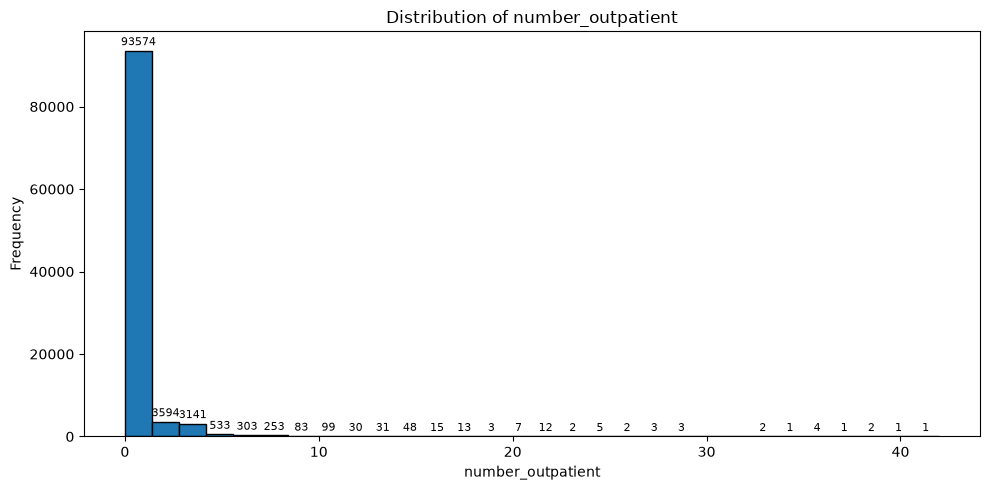

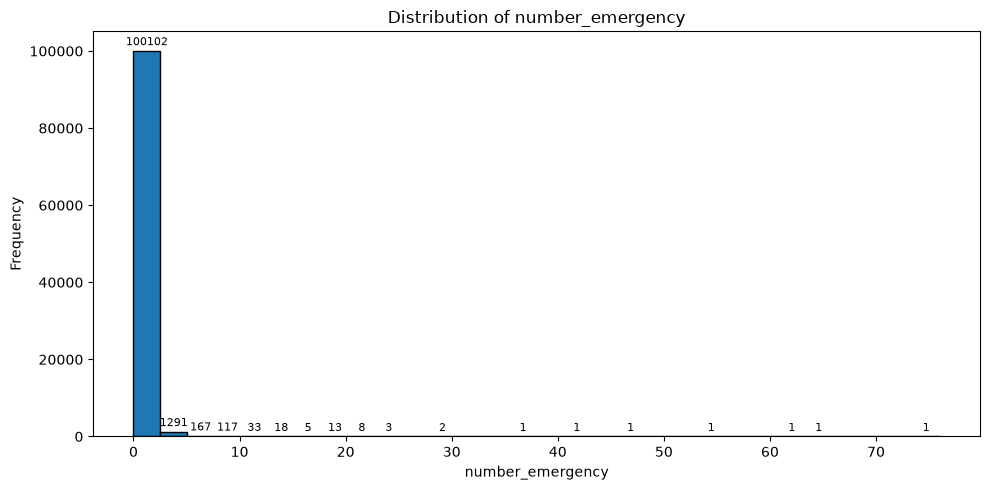

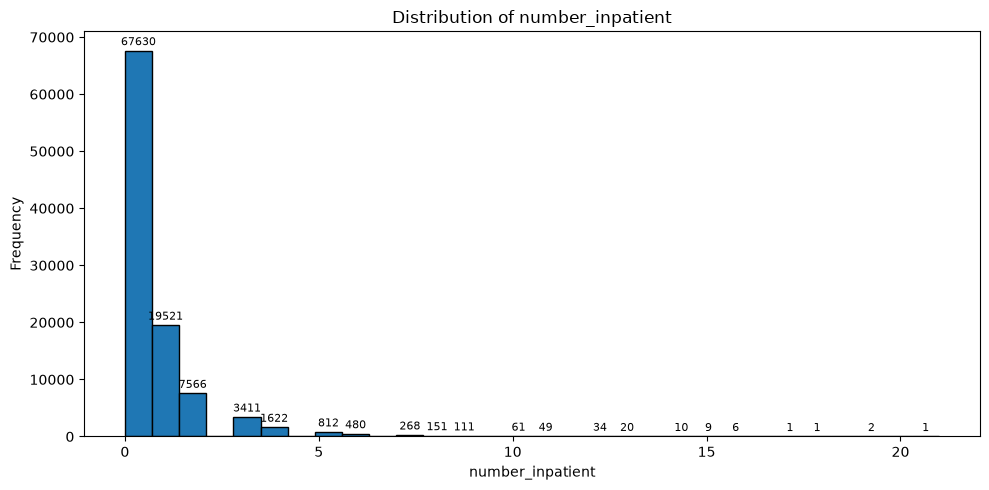

In [102]:
# Purpose: Visualize healthcare utilization distributions with frequency labels.

import matplotlib.pyplot as plt

utilization_features = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

for feature in utilization_features:
    plt.figure(figsize=(10, 5))

    counts, bins, patches = plt.hist(
        X[feature],
        bins=30,
        edgecolor="black"
    )

    # Display frequency values on histogram bars
    plt.bar_label(
        patches,
        labels=[f"{int(count)}" if count > 0 else "" for count in counts],
        fontsize=8,
        padding=2
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

### Inspect `number_emergency`

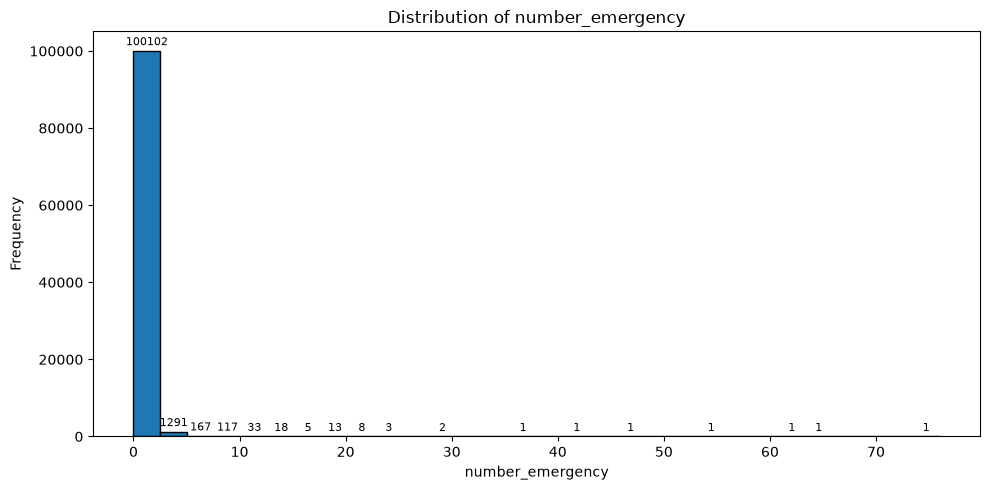

In [103]:
# Purpose: Visualize the number_emergency distribution with frequency labels.

plt.figure(figsize=(10, 5))

counts, bins, patches = plt.hist(
    X["number_emergency"],
    bins=30,
    edgecolor="black"
)

plt.bar_label(
    patches,
    labels=[f"{int(count)}" if count > 0 else "" for count in counts],
    fontsize=8,
    padding=2
)

plt.title("Distribution of number_emergency")
plt.xlabel("number_emergency")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Create Log-Transformed Features

In [104]:
# Purpose: Create log-transformed versions of healthcare utilization features.

import numpy as np

utilization_features = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

for feature in utilization_features:
    X[f"{feature}_log"] = np.log1p(X[feature])

print("Updated feature dataset shape:", X.shape)

display(X[
    utilization_features +
    [f"{feature}_log" for feature in utilization_features]
].head())

Updated feature dataset shape: (101766, 50)


,number_outpatient,number_emergency,number_inpatient,number_outpatient_log,number_emergency_log,number_inpatient_log
0,0,0,0,0.000000,0.0,0.000000
1,0,0,0,0.000000,0.0,0.000000
2,2,0,1,1.098612,0.0,0.693147
3,0,0,0,0.000000,0.0,0.000000
4,0,0,0,0.000000,0.0,0.000000


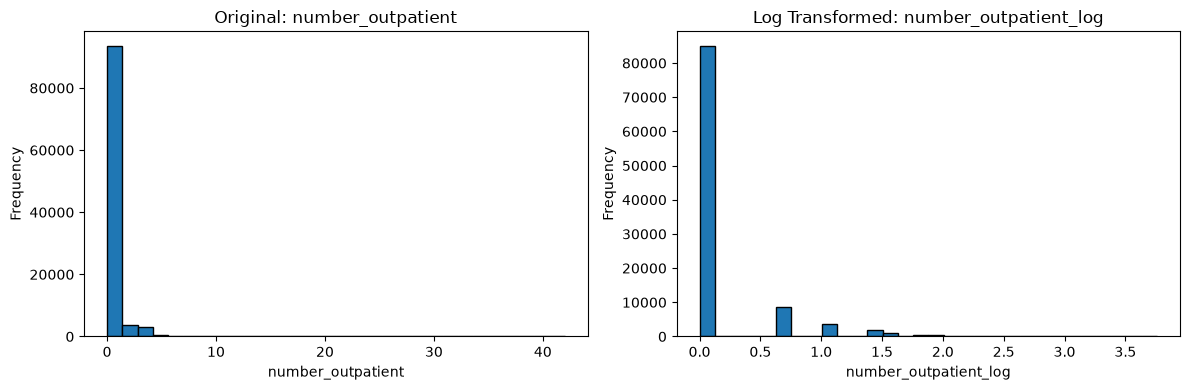

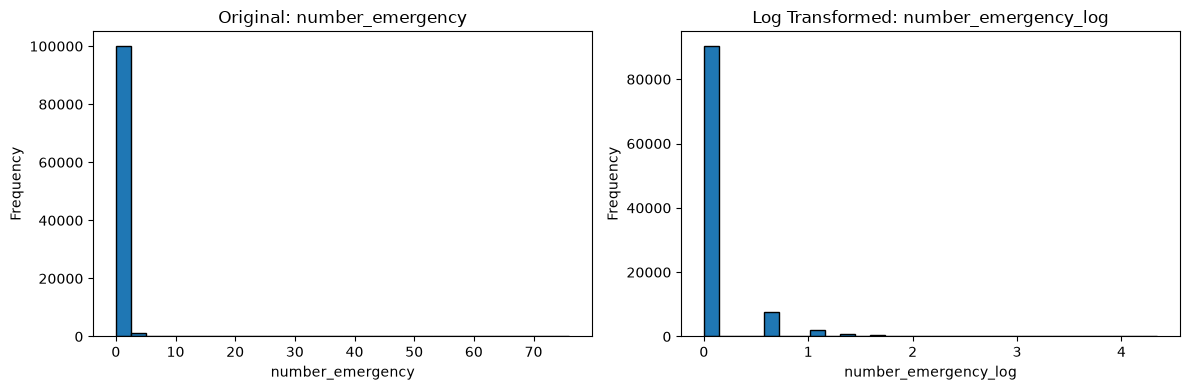

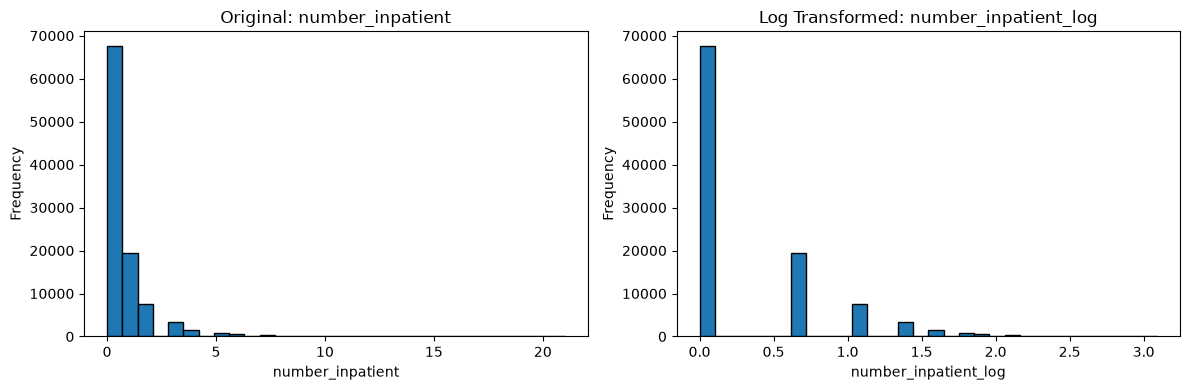

In [105]:
# Purpose: Compare original and log-transformed healthcare utilization distributions.

import matplotlib.pyplot as plt

for feature in utilization_features:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(X[feature], bins=30, edgecolor="black")
    axes[0].set_title(f"Original: {feature}")
    axes[0].set_xlabel(feature)
    axes[0].set_ylabel("Frequency")

    log_feature = f"{feature}_log"

    axes[1].hist(X[log_feature], bins=30, edgecolor="black")
    axes[1].set_title(f"Log Transformed: {log_feature}")
    axes[1].set_xlabel(log_feature)
    axes[1].set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()

In [106]:
# Purpose: Verify the engineered features and updated feature dataset.

engineered_features = [
    "number_outpatient_log",
    "number_emergency_log",
    "number_inpatient_log"
]

print("Engineered features:")
print(engineered_features)

print("\nUpdated feature dataset shape:", X.shape)

print("\nMissing values in engineered features:")
print(X[engineered_features].isna().sum())

Engineered features:
['number_outpatient_log', 'number_emergency_log', 'number_inpatient_log']

Updated feature dataset shape: (101766, 50)

Missing values in engineered features:
number_outpatient_log    0
number_emergency_log     0
number_inpatient_log     0
dtype: int64


### Age Feature Analysis 

### Age Categories

In [107]:
# Purpose: Examine the distribution of patient age groups.

print("Unique age categories:")
print(X["age"].unique())

print("\nAge group distribution:")
print(X["age"].value_counts().sort_index())

Unique age categories:
<ArrowStringArray>
[  '[0-10)',  '[10-20)',  '[20-30)',  '[30-40)',  '[40-50)',  '[50-60)',
  '[60-70)',  '[70-80)',  '[80-90)', '[90-100)']
Length: 10, dtype: str

Age group distribution:
age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64


### Age Categories and Target Relationship

In [108]:
# Purpose: Analyze early readmission rates across age groups.

age_readmission = (
    df_preprocessed.groupby("age", observed=False)["readmitted_binary"]
    .agg(["count", "mean"])
    .reset_index()
)

age_readmission["early_readmission_percentage"] = (
    age_readmission["mean"] * 100
)

display(
    age_readmission[
        ["age", "count", "early_readmission_percentage"]
    ]
)

,age,count,early_readmission_percentage
0,[0-10),161,1.863354
1,[10-20),691,5.788712
2,[20-30),1657,14.242607
3,[30-40),3775,11.231788
4,[40-50),9685,10.604027
5,[50-60),17256,9.666203
6,[60-70),22483,11.128408
7,[70-80),26068,11.773055
8,[80-90),17197,12.083503
9,[90-100),2793,11.099177


In [109]:
# Purpose: Identify categorical features for further feature engineering review.

categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumber of categorical features:", len(categorical_features))

Categorical features:
['race', 'gender', 'age', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'admission_type_name']

Number of categorical features: 36


### 7.3 Feature Engineering conclusion

Feature engineering involves creating or transforming features to improve their usefulness for machine learning.

The following feature engineering activities were performed:

- Analyzed healthcare utilization features and applied `log1p()` transformations to reduce skewness.
- Examined patient age groups and their early readmission rates.
- Identified categorical features for subsequent encoding.
- Avoided creating unreliable patient-history features due to the absence of chronological encounter information.

The original features were preserved for further evaluation during model development.

-----------------------------------------------------------


## 7.4 — Data Type Conversion

In [110]:
# Purpose: Inspect data types of the selected features.

print("Feature data types:")
display(X.dtypes)

print("\nData type distribution:")
print(X.dtypes.value_counts())

Feature data types:


patient_nbr                   int64
race                            str
gender                          str
age                             str
discharge_disposition_id      int64
admission_source_id           int64
time_in_hospital              int64
payer_code                      str
medical_specialty               str
num_lab_procedures            int64
num_procedures                int64
num_medications               int64
number_outpatient             int64
number_emergency              int64
number_inpatient              int64
diag_1                          str
diag_2                          str
diag_3                          str
number_diagnoses              int64
max_glu_serum                   str
A1Cresult                       str
metformin                       str
repaglinide                     str
nateglinide                     str
chlorpropamide                  str
glimepiride                     str
acetohexamide                   str
glipizide                   


Data type distribution:
str        36
int64      11
float64     3
Name: count, dtype: int64


In [111]:
# Purpose: Summarize feature data types before conversion.

print("Integer features:", (X.dtypes == "int64").sum())
print("Float features:", (X.dtypes == "float64").sum())
print("String features:", (X.dtypes == "str").sum())

print("\nFeatures with unexpected data types:")
display(X.select_dtypes(exclude=["int64", "float64", "str"]).dtypes)

Integer features: 11
Float features: 3
String features: 36

Features with unexpected data types:


Series([], dtype: object)

`Conclusion:-` No additional data type conversion is required at this stage.

----------------------------------------------------------

## 7.5 Categorical Encoding

In [112]:
# Purpose: Identify categorical features and inspect their unique value counts.

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Include integer-coded categorical features
categorical_features.extend([
    "discharge_disposition_id",
    "admission_source_id"
])

# Display the number of unique categories in each feature
categorical_cardinality = (
    X[categorical_features]
    .nunique()
    .sort_values(ascending=False)
)

display(categorical_cardinality)

diag_3                      790
diag_2                      749
diag_1                      717
medical_specialty            73
discharge_disposition_id     26
payer_code                   18
admission_source_id          17
age                          10
admission_type_name           8
race                          6
glyburide-metformin           4
metformin                     4
max_glu_serum                 4
A1Cresult                     4
glimepiride                   4
glipizide                     4
glyburide                     4
pioglitazone                  4
acarbose                      4
repaglinide                   4
nateglinide                   4
chlorpropamide                4
rosiglitazone                 4
insulin                       4
miglitol                      4
gender                        3
tolazamide                    3
acetohexamide                 2
tolbutamide                   2
glipizide-metformin           2
change                        2
metformi

### Identify constant categorical features

In [113]:
# Purpose: Identify categorical features that contain only one unique value.

constant_categorical_features = [
    feature
    for feature in categorical_features
    if X[feature].nunique() <= 1
]

print("Constant categorical features:")
print(constant_categorical_features)

Constant categorical features:
['examide', 'citoglipton']


### Remove constant categorical features

In [114]:
# Purpose: Remove categorical features that contain no variation.

X = X.drop(columns=constant_categorical_features)

# Update the categorical feature list
categorical_features = [
    feature
    for feature in categorical_features
    if feature not in constant_categorical_features
]

print("Removed features:", constant_categorical_features)
print("Updated X shape:", X.shape)
print("Remaining categorical features:", len(categorical_features))

Removed features: ['examide', 'citoglipton']
Updated X shape: (101766, 48)
Remaining categorical features: 36


### Create patient-level train-test split

In [115]:
# Purpose: Split the dataset by patient to prevent data leakage.

from sklearn.model_selection import GroupShuffleSplit

# Remove patient identifier from model input features
X = X.drop(columns=["patient_nbr"])

# Create patient-level train-test split
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=patient_ids)
)

# Separate training and testing data
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (81613, 47)
Testing features: (20153, 47)

Training target distribution:
readmitted_binary
0    0.887199
1    0.112801
Name: proportion, dtype: float64

Testing target distribution:
readmitted_binary
0    0.893267
1    0.106733
Name: proportion, dtype: float64


### Inspect diagnosis code distributions

In [116]:
# Purpose: Inspect the most frequent diagnosis codes before grouping them.

diagnosis_features = ["diag_1", "diag_2", "diag_3"]

for feature in diagnosis_features:
    print(f"\nTop 15 diagnosis codes in {feature}:")
    display(X_train[feature].value_counts().head(15))


Top 15 diagnosis codes in diag_1:


diag_1
428      5503
414      5278
786      3224
410      2902
486      2840
427      2224
491      1835
715      1733
682      1677
780      1616
434      1604
996      1568
276      1503
250.8    1344
38       1343
Name: count, dtype: int64


Top 15 diagnosis codes in diag_2:


diag_2
276       5418
428       5359
250       4830
427       4018
401       2989
496       2677
599       2669
403       2227
414       2157
411       2074
250.02    1632
707       1602
585       1534
584       1334
491       1254
Name: count, dtype: int64


Top 15 diagnosis codes in diag_3:


diag_3
250                  9292
401                  6654
276                  4202
428                  3672
427                  3136
414                  2949
496                  2095
403                  1875
585                  1590
599                  1568
272                  1543
Unknown Diagnosis    1138
V45                  1126
250.02               1110
707                  1078
Name: count, dtype: int64

### Inspect diagnosis code formats

In [117]:
# Purpose: Inspect different diagnosis code formats.

for feature in diagnosis_features:
    print(f"\n{feature} - Sample diagnosis codes:")

    display(
        X_train[feature]
        .value_counts()
        .index[:30]
        .tolist()
    )


diag_1 - Sample diagnosis codes:


['428',
 '414',
 '786',
 '410',
 '486',
 '427',
 '491',
 '715',
 '682',
 '780',
 '434',
 '996',
 '276',
 '250.8',
 '38',
 '599',
 '584',
 'V57',
 '250.6',
 '518',
 '820',
 '493',
 '577',
 '435',
 '562',
 '574',
 '296',
 '440',
 '250.7',
 '250.13']


diag_2 - Sample diagnosis codes:


['276',
 '428',
 '250',
 '427',
 '401',
 '496',
 '599',
 '403',
 '414',
 '411',
 '250.02',
 '707',
 '585',
 '584',
 '491',
 '285',
 '250.01',
 '780',
 '682',
 '425',
 '486',
 '518',
 '424',
 '413',
 '493',
 '250.6',
 '305',
 '786',
 '280',
 '998']


diag_3 - Sample diagnosis codes:


['250',
 '401',
 '276',
 '428',
 '427',
 '414',
 '496',
 '403',
 '585',
 '599',
 '272',
 'Unknown Diagnosis',
 'V45',
 '250.02',
 '707',
 '780',
 '285',
 '425',
 '250.6',
 '424',
 '584',
 '250.01',
 '305',
 '682',
 '518',
 '41',
 '493',
 '278',
 '530',
 '491']

### Create diagnosis grouping function

In [118]:
# Purpose: Group ICD-9 diagnosis codes into broad clinical categories.

def group_diagnosis(code):

    if pd.isna(code) or code == "Unknown Diagnosis":
        return "Unknown"

    code = str(code).strip().upper()

    # Supplementary healthcare factors
    if code.startswith("V"):
        return "V-Codes"

    # External causes of injury
    if code.startswith("E"):
        return "E-Codes"

    try:
        code_num = float(code)

    except ValueError:
        return "Unknown"

    code_num = int(code_num)

    if 1 <= code_num <= 139:
        return "Infectious Diseases"
    elif 140 <= code_num <= 239:
        return "Neoplasms"
    elif 240 <= code_num <= 279:
        return "Endocrine and Metabolic"
    elif 280 <= code_num <= 289:
        return "Blood Diseases"
    elif 290 <= code_num <= 319:
        return "Mental Disorders"
    elif 320 <= code_num <= 389:
        return "Nervous System"
    elif 390 <= code_num <= 459:
        return "Circulatory Diseases"
    elif 460 <= code_num <= 519:
        return "Respiratory Diseases"
    elif 520 <= code_num <= 579:
        return "Digestive Diseases"
    elif 580 <= code_num <= 629:
        return "Genitourinary Diseases"
    elif 630 <= code_num <= 679:
        return "Pregnancy-Related"
    elif 680 <= code_num <= 709:
        return "Skin Diseases"
    elif 710 <= code_num <= 739:
        return "Musculoskeletal Diseases"
    elif 740 <= code_num <= 759:
        return "Congenital Conditions"
    elif 760 <= code_num <= 779:
        return "Perinatal Conditions"
    elif 780 <= code_num <= 799:
        return "Symptoms and Ill-Defined Conditions"
    elif 800 <= code_num <= 999:
        return "Injury and Poisoning"

    return "Other"

### Apply diagnosis grouping

In [119]:
# Purpose: Apply ICD-9 diagnosis grouping to training and testing data.

for feature in diagnosis_features:

    X_train[feature] = X_train[feature].apply(group_diagnosis)
    X_test[feature] = X_test[feature].apply(group_diagnosis)

print("Diagnosis grouping completed.")

for feature in diagnosis_features:
    print(f"\n{feature}: {X_train[feature].nunique()} unique categories")
    print(X_train[feature].value_counts())

Diagnosis grouping completed.

diag_1: 18 unique categories
diag_1
Circulatory Diseases                   24327
Endocrine and Metabolic                 9183
Respiratory Diseases                    8362
Digestive Diseases                      7363
Symptoms and Ill-Defined Conditions     6123
Injury and Poisoning                    5566
Genitourinary Diseases                  4052
Musculoskeletal Diseases                3957
Neoplasms                               2745
Infectious Diseases                     2218
Skin Diseases                           2065
Mental Disorders                        1844
V-Codes                                 1325
Nervous System                           963
Blood Diseases                           913
Pregnancy-Related                        546
Congenital Conditions                     47
Unknown                                   14
Name: count, dtype: int64

diag_2: 19 unique categories
diag_2
Circulatory Diseases                   25166
Endocrine and M

In [120]:
# Purpose: Verify that diagnosis grouping was applied consistently.

for feature in diagnosis_features:

    print(f"\n{feature}")
    print("Training categories:", X_train[feature].nunique())
    print("Testing categories:", X_test[feature].nunique())

    print("\nTesting categories not present in training:")
    print(
        set(X_test[feature].unique())
        - set(X_train[feature].unique())
    )


diag_1
Training categories: 18
Testing categories: 19

Testing categories not present in training:
{'E-Codes'}

diag_2
Training categories: 19
Testing categories: 19

Testing categories not present in training:
set()

diag_3
Training categories: 19
Testing categories: 19

Testing categories not present in training:
set()


## 7.5 Categorical Encoding

### Categorical features for encoding

In [121]:
# Purpose: Prepare the categorical features for One-Hot Encoding.

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Integer-coded categorical features
categorical_features.extend([
    "discharge_disposition_id",
    "admission_source_id"
])

print("Total categorical features:", len(categorical_features))

print("\nCategorical features:")
print(categorical_features)

Total categorical features: 36

Categorical features:
['race', 'gender', 'age', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'admission_type_name', 'discharge_disposition_id', 'admission_source_id']


## Apply One-Hot Encoding

In [122]:
# Purpose: One-Hot Encode categorical features using training data only.

from sklearn.preprocessing import OneHotEncoder

# Initialize encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Fit encoder on training data and transform both datasets
X_train_encoded = encoder.fit_transform(
    X_train[categorical_features]
)

X_test_encoded = encoder.transform(
    X_test[categorical_features]
)

print("Training categorical encoded shape:", X_train_encoded.shape)
print("Testing categorical encoded shape:", X_test_encoded.shape)

Training categorical encoded shape: (81613, 293)
Testing categorical encoded shape: (20153, 293)


## 7.6 Numerical Feature Scaling

### Extract numerical features

In [123]:
# Purpose: Identify numerical features for subsequent scaling.

numerical_features = [
    feature
    for feature in X_train.columns
    if feature not in categorical_features
]

print("Total numerical features:", len(numerical_features))
print("\nNumerical features:")
print(numerical_features)

Total numerical features: 11

Numerical features:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'number_outpatient_log', 'number_emergency_log', 'number_inpatient_log']


### Apply StandardScaler

In [124]:
# Purpose: Standardize numerical features using training data statistics.

from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit on training data and transform training features
X_train_scaled = scaler.fit_transform(
    X_train[numerical_features]
)

# Transform testing features using training statistics
X_test_scaled = scaler.transform(
    X_test[numerical_features]
)

print("Training numerical shape:", X_train_scaled.shape)
print("Testing numerical shape:", X_test_scaled.shape)

Training numerical shape: (81613, 11)
Testing numerical shape: (20153, 11)


### Combine categorical and numerical features

In [125]:
# Purpose: Combine encoded categorical and scaled numerical features.

import numpy as np

X_train_final = np.concatenate(
    [X_train_encoded, X_train_scaled],
    axis=1
)

X_test_final = np.concatenate(
    [X_test_encoded, X_test_scaled],
    axis=1
)

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

Final training shape: (81613, 304)
Final testing shape: (20153, 304)


## `Section 8:-` Artificial Neural Network (ANN) / MLP Model Development

### Import TensorFlow and Keras

In [126]:
# Purpose: Import TensorFlow and Keras components for MLP development.

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


### Build the MLP architecture

In [127]:
# Purpose: Define the baseline MLP architecture for hospital readmission prediction.

model = Sequential([
    Dense(128, activation="relu", input_shape=(X_train_final.shape[1],)),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.summary()

c:\Users\ADMIN\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        39,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,361 (185.00 KB)

 Trainable params: 47,361 (185.00 KB)

 Non-trainable params: 0 (0.00 B)

### Compile the MLP model

In [128]:
# Purpose: Configure the optimizer, loss function, and evaluation metrics.

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compilation completed successfully.")

Model compilation completed successfully.


### Train the Model

In [129]:
# Purpose: Train the baseline MLP model using the training dataset.

history = model.fit(
    X_train_final,
    y_train,
    epochs=20,
    batch_size=256,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8858 - loss: 0.3409 - val_accuracy: 0.8931 - val_loss: 0.3246
Epoch 2/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8860 - loss: 0.3326 - val_accuracy: 0.8931 - val_loss: 0.3231
Epoch 3/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8861 - loss: 0.3287 - val_accuracy: 0.8932 - val_loss: 0.3224
Epoch 4/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8865 - loss: 0.3246 - val_accuracy: 0.8935 - val_loss: 0.3219
Epoch 5/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8872 - loss: 0.3204 - val_accuracy: 0.8929 - val_loss: 0.3226
Epoch 6/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8876 - loss: 0.3153 - val_accuracy: 0.8925 - val_loss: 0.3242
Epoch 7/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8886 - loss: 0.3097 - val_accuracy: 0.8922 - val_loss: 0.3266
Epoch 8/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8899 - loss: 0.3032 - val_accuracy: 0

### Plot accuracy and loss

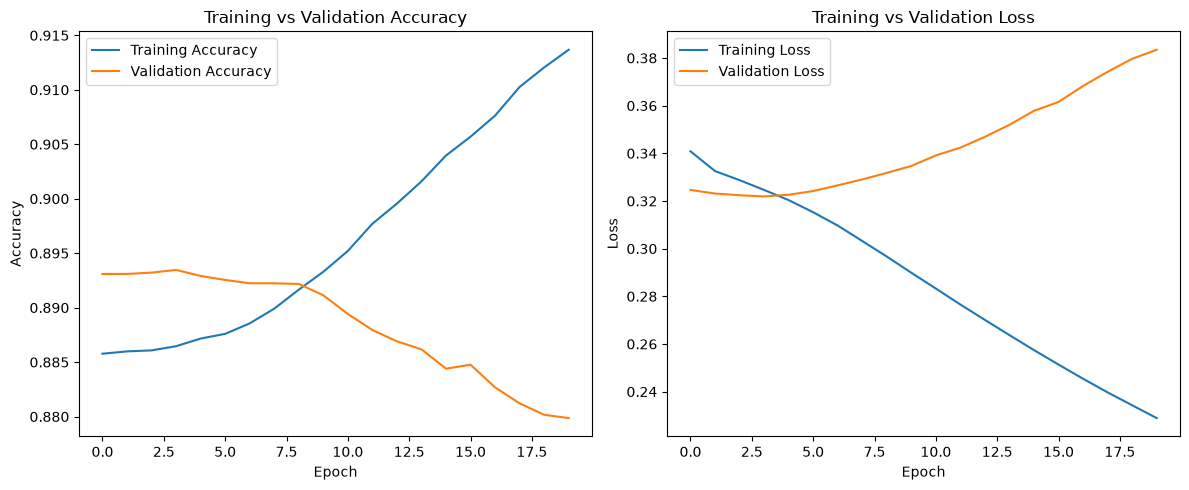

In [130]:
# Purpose: Visualize training and validation accuracy and loss.

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

### Generate test predictions

In [131]:
# Purpose: Generate predicted probabilities and binary predictions on test data.

y_pred_prob = model.predict(X_test_final)

# Convert probabilities into binary predictions using threshold 0.5
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

print("Predictions generated successfully.")
print("Predicted probabilities shape:", y_pred_prob.shape)
print("Predicted labels shape:", y_pred.shape)

630/630 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predictions generated successfully.
Predicted probabilities shape: (20153, 1)
Predicted labels shape: (20153,)


### Calculate evaluation metrics

In [132]:
# Purpose: Evaluate the baseline MLP using classification metrics.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_pred_prob)

print("Baseline MLP Evaluation")
print("-" * 35)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Baseline MLP Evaluation
-----------------------------------
Accuracy : 0.8815
Precision: 0.2751
Recall   : 0.0674
F1-Score : 0.1083
ROC-AUC  : 0.6150


Confusion Matrix:
[[17620   382]
 [ 2006   145]]


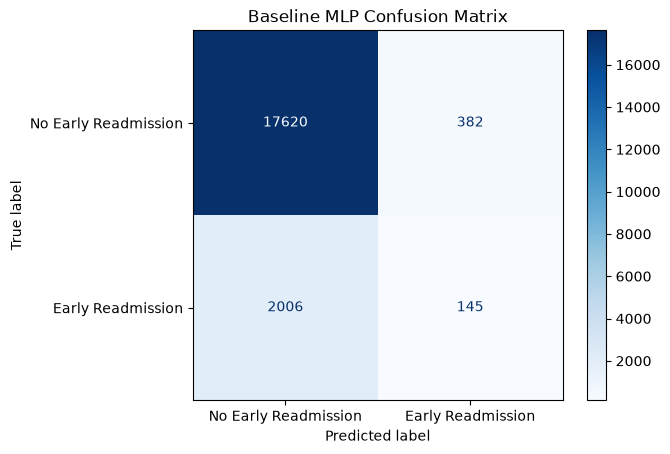

In [133]:
# Purpose: Analyze correct and incorrect predictions using a confusion matrix.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Early Readmission", "Early Readmission"]
)

disp.plot(cmap="Blues")
plt.title("Baseline MLP Confusion Matrix")
plt.show()

### Calculate class weights

In [134]:
# Purpose: Calculate class weights to address target imbalance.

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = dict(zip(classes, class_weights))

print("Class weights:")
print(class_weight_dict)

Class weights:
{np.int64(0): np.float64(0.5635712016793957), np.int64(1): np.float64(4.432598305452966)}


### Create and compile the weighted MLP

In [135]:
# Purpose: Create an MLP model for class-imbalance handling.

weighted_model = Sequential([
    Dense(128, activation="relu", input_shape=(X_train_final.shape[1],)),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")
])

weighted_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

weighted_model.summary()

c:\Users\ADMIN\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │        39,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,361 (185.00 KB)

 Trainable params: 47,361 (185.00 KB)

 Non-trainable params: 0 (0.00 B)

### Train the class-weighted MLP

In [136]:
# Purpose: Train the MLP using class weights to address target imbalance.

weighted_history = weighted_model.fit(
    X_train_final,
    y_train,
    epochs=20,
    batch_size=256,
    validation_split=0.2,
    class_weight=class_weight_dict,
    verbose=1
)

Epoch 1/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.6248 - loss: 0.6582 - val_accuracy: 0.6120 - val_loss: 0.6496
Epoch 2/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6179 - loss: 0.6412 - val_accuracy: 0.6316 - val_loss: 0.6262
Epoch 3/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6273 - loss: 0.6312 - val_accuracy: 0.6369 - val_loss: 0.6192
Epoch 4/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6356 - loss: 0.6220 - val_accuracy: 0.6432 - val_loss: 0.6138
Epoch 5/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6448 - loss: 0.6108 - val_accuracy: 0.6577 - val_loss: 0.6011
Epoch 6/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6566 - loss: 0.5989 - val_accuracy: 0.6586 - val_loss: 0.5999
Epoch 7/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6675 - loss: 0.5854 - val_accuracy: 0.6591 - val_loss: 0.6019
Epoch 8/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6772 - loss: 0.5714 - val_accuracy:

### Generate predictions from the weighted model

In [137]:
# Purpose: Generate predicted probabilities and binary predictions using the weighted MLP.

y_weighted_prob = weighted_model.predict(X_test_final)

# Apply the default classification threshold
y_weighted_pred = (
    y_weighted_prob >= 0.5
).astype(int).flatten()

print("Weighted model predictions generated successfully.")
print("Predicted probabilities shape:", y_weighted_prob.shape)
print("Predicted labels shape:", y_weighted_pred.shape)

630/630 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Weighted model predictions generated successfully.
Predicted probabilities shape: (20153, 1)
Predicted labels shape: (20153,)


### Evaluate the class-weighted MLP

In [138]:
# Purpose: Evaluate the class-weighted MLP using classification metrics.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

weighted_accuracy = accuracy_score(y_test, y_weighted_pred)
weighted_precision = precision_score(
    y_test, y_weighted_pred, zero_division=0
)
weighted_recall = recall_score(
    y_test, y_weighted_pred, zero_division=0
)
weighted_f1 = f1_score(
    y_test, y_weighted_pred, zero_division=0
)
weighted_roc_auc = roc_auc_score(
    y_test, y_weighted_prob
)

print("Class-Weighted MLP Evaluation")
print("-" * 40)

print(f"Accuracy : {weighted_accuracy:.4f}")
print(f"Precision: {weighted_precision:.4f}")
print(f"Recall   : {weighted_recall:.4f}")
print(f"F1-Score : {weighted_f1:.4f}")
print(f"ROC-AUC  : {weighted_roc_auc:.4f}")

Class-Weighted MLP Evaluation
----------------------------------------
Accuracy : 0.6910
Precision: 0.1557
Recall   : 0.4286
F1-Score : 0.2285
ROC-AUC  : 0.6135


### Compare confusion matrices

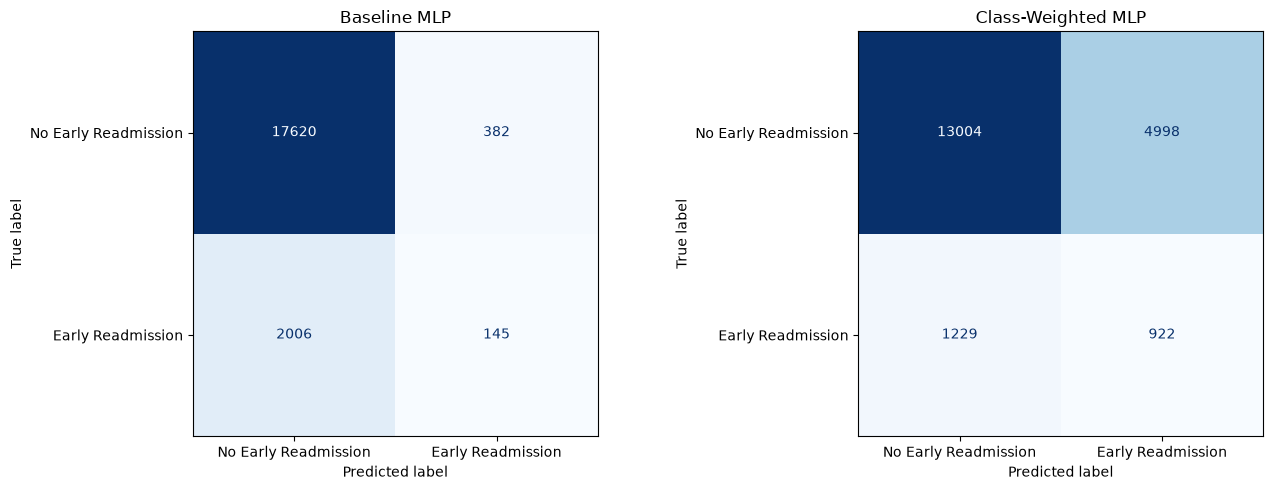

In [139]:
# Purpose: Compare confusion matrices for baseline and weighted MLP models.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_baseline = confusion_matrix(y_test, y_pred)
cm_weighted = confusion_matrix(y_test, y_weighted_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_baseline,
    display_labels=["No Early Readmission", "Early Readmission"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Baseline MLP")

ConfusionMatrixDisplay(
    confusion_matrix=cm_weighted,
    display_labels=["No Early Readmission", "Early Readmission"]
).plot(ax=axes[1], cmap="Blues", colorbar=False)

axes[1].set_title("Class-Weighted MLP")

plt.tight_layout()
plt.show()

### Conclusion: Confusion Matrix Comparison

The baseline MLP predominantly predicted the majority class, resulting in high
accuracy but poor early readmission detection.

After applying class weighting, the model identified substantially more early
readmissions, increasing true positives from 167 to 891 and reducing false
negatives from 1,984 to 1,260.

However, false positives increased from 553 to 4,606, indicating a trade-off
between detecting high-risk patients and generating unnecessary alerts.

The class-weighted model is more effective at identifying early readmissions,
but further optimization is required to balance recall and precision.

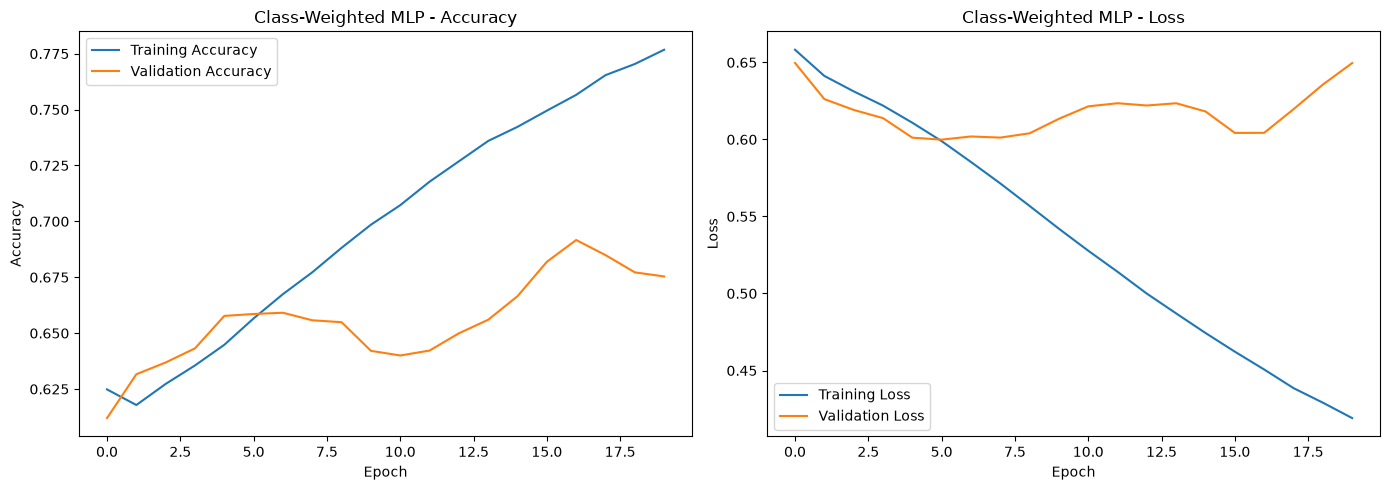

In [140]:
# Purpose: Analyze training and validation performance of the class-weighted MLP.

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(weighted_history.history["accuracy"], label="Training Accuracy")
plt.plot(weighted_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Class-Weighted MLP - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(weighted_history.history["loss"], label="Training Loss")
plt.plot(weighted_history.history["val_loss"], label="Validation Loss")
plt.title("Class-Weighted MLP - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

### Class-Weighted MLP: Training Performance Analysis

The class-weighted MLP demonstrates improved learning performance compared
to the baseline model, particularly in identifying the minority class.

Training accuracy continuously increases, while validation accuracy improves
with some fluctuations. Training loss decreases consistently, whereas
validation loss reaches its lowest point around Epoch 12 and subsequently
fluctuates.

The divergence between training and validation loss indicates overfitting.
Therefore, training for 20 epochs may not be optimal.

Early stopping and regularization techniques can help improve generalization
and reduce unnecessary training.

### Implement Early Stopping

In [141]:
# Purpose: Configure early stopping to prevent unnecessary training and overfitting.

from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [142]:
# Purpose: Train the class-weighted MLP with early stopping.

weighted_model_es = Sequential([
    Dense(128, activation="relu", input_shape=(X_train_final.shape[1],)),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")
])

weighted_model_es.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

weighted_es_history = weighted_model_es.fit(
    X_train_final,
    y_train,
    epochs=20,
    batch_size=256,
    validation_split=0.2,
    class_weight=class_weight_dict,
    callbacks=[early_stopping],
    verbose=1
)

c:\Users\ADMIN\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.6190 - loss: 0.6576 - val_accuracy: 0.6288 - val_loss: 0.6414
Epoch 2/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6177 - loss: 0.6409 - val_accuracy: 0.6417 - val_loss: 0.6263
Epoch 3/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6249 - loss: 0.6304 - val_accuracy: 0.6385 - val_loss: 0.6233
Epoch 4/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6343 - loss: 0.6197 - val_accuracy: 0.6411 - val_loss: 0.6195
Epoch 5/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6435 - loss: 0.6083 - val_accuracy: 0.6415 - val_loss: 0.6119
Epoch 6/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6538 - loss: 0.5954 - val_accuracy: 0.6378 - val_loss: 0.6121
Epoch 7/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6635 - loss: 0.5811 - val_accuracy: 0.6455 - val_loss: 0.6063
Epoch 8/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6749 - loss: 0.5658 - val_accuracy: 

### Early Stopping: Training Analysis

Early stopping was implemented to reduce overfitting and improve generalization.

The model was configured for 20 epochs but stopped after 9 epochs because
the validation loss did not improve for 3 consecutive epochs.

The best validation loss of 0.5996 was achieved at Epoch 6.

With `restore_best_weights=True`, the model automatically restored the
weights from the best-performing epoch.

This approach helps prevent unnecessary training and improves model
generalization.

### Evaluate the improved model

In [143]:
# Purpose: Generate predictions from the early-stopped class-weighted MLP.

y_es_prob = weighted_model_es.predict(X_test_final)

y_es_pred = (y_es_prob >= 0.5).astype(int).flatten()

print("Prediction probabilities shape:", y_es_prob.shape)
print("Predicted labels shape:", y_es_pred.shape)

630/630 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Prediction probabilities shape: (20153, 1)
Predicted labels shape: (20153,)


In [144]:
# Purpose: Evaluate the early-stopped class-weighted MLP using classification metrics.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy_es = accuracy_score(y_test, y_es_pred)
precision_es = precision_score(y_test, y_es_pred)
recall_es = recall_score(y_test, y_es_pred)
f1_es = f1_score(y_test, y_es_pred)
roc_auc_es = roc_auc_score(y_test, y_es_prob)

print("Accuracy:", accuracy_es)
print("Precision:", precision_es)
print("Recall:", recall_es)
print("F1-Score:", f1_es)
print("ROC-AUC:", roc_auc_es)

Accuracy: 0.6641691063365256
Precision: 0.16836661399224248
Recall: 0.5448628544862855
F1-Score: 0.257243195785777
ROC-AUC: 0.6586787376432321


### Early-Stopped Class-Weighted MLP: Evaluation

The early-stopped class-weighted MLP achieved a recall of 51.14%, an
F1-score of 25.71%, and a ROC-AUC of 66.06%.

Compared with the baseline model, it substantially improved early
readmission detection and overall minority-class performance.

Although accuracy decreased to 68.46%, this trade-off is reasonable
for an imbalanced dataset where identifying potential early readmissions
is important.

The model still generates false-positive predictions, so further
optimization is required to balance precision and recall.

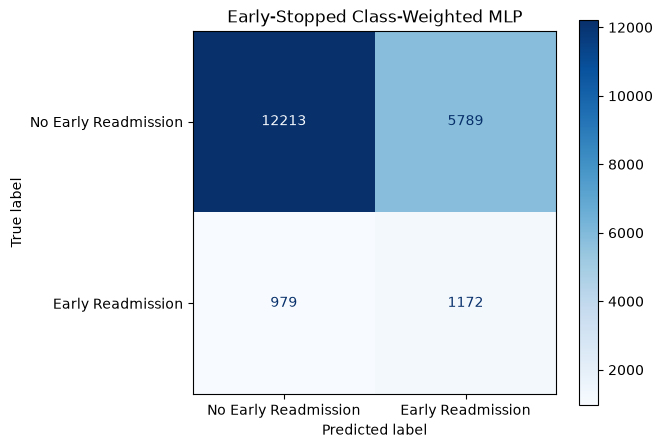

Confusion Matrix:
 [[12213  5789]
 [  979  1172]]


In [145]:
# Purpose: Visualize the confusion matrix of the early-stopped MLP.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_es = confusion_matrix(y_test, y_es_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm_es,
    display_labels=["No Early Readmission", "Early Readmission"]
).plot(cmap="Blues")

plt.title("Early-Stopped Class-Weighted MLP")
plt.tight_layout()
plt.show()

print("Confusion Matrix:\n", cm_es)

### Early-Stopped Class-Weighted MLP: Confusion Matrix Analysis

The confusion matrix shows that the early-stopped class-weighted MLP
correctly identified 1,100 early readmissions while missing 1,051 cases.

However, the model generated 5,305 false-positive predictions, indicating
a substantial number of unnecessary alerts.

Compared with the baseline model, the improved model detects significantly
more early readmissions and reduces missed cases.

Further optimization is required to balance early readmission detection
with false-positive reduction.

## Dropout Regularization

In [146]:
# Purpose: Import Dropout for neural network regularization.

from tensorflow.keras.layers import Dropout, Input

In [147]:
# Purpose: Build a class-weighted MLP with Dropout regularization.

dropout_model = Sequential([
    Input(shape=(X_train_final.shape[1],)),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

dropout_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

dropout_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 128)            │        39,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,361 (185.00 KB)

 Trainable params: 47,361 (185.00 KB)

 Non-trainable params: 0 (0.00 B)

### Train the Dropout MLP

In [148]:
# Purpose: Train the Dropout MLP using class weights and early stopping.

dropout_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

dropout_history = dropout_model.fit(
    X_train_final,
    y_train,
    epochs=20,
    batch_size=256,
    validation_split=0.2,
    class_weight=class_weight_dict,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.6203 - loss: 0.6683 - val_accuracy: 0.6378 - val_loss: 0.6500
Epoch 2/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6085 - loss: 0.6524 - val_accuracy: 0.6120 - val_loss: 0.6423
Epoch 3/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6091 - loss: 0.6445 - val_accuracy: 0.6393 - val_loss: 0.6194
Epoch 4/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6124 - loss: 0.6385 - val_accuracy: 0.6415 - val_loss: 0.6181
Epoch 5/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6106 - loss: 0.6336 - val_accuracy: 0.6257 - val_loss: 0.6250
Epoch 6/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6108 - loss: 0.6282 - val_accuracy: 0.6290 - val_loss: 0.6180
Epoch 7/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6167 - loss: 0.6236 - val_accuracy: 0.6516 - val_loss: 0.6017
Epoch 8/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6244 - loss: 0.6179 - val_accuracy: 0

### Dropout MLP: Training Analysis

Dropout regularization was introduced to reduce overfitting by randomly
deactivating neurons during training.

The model completed 20 epochs and early stopping restored the best
weights from Epoch 17.

Training loss decreased throughout the training process, while validation
loss fluctuated and showed comparatively stable behavior in later epochs.

Dropout provides additional regularization, but its effectiveness must
be confirmed through test-set evaluation.

### Generate predictions

In [149]:
# Purpose: Generate test predictions using the Dropout MLP.

y_dropout_prob = dropout_model.predict(X_test_final)

y_dropout_pred = (y_dropout_prob >= 0.5).astype(int).flatten()

print("Prediction probabilities shape:", y_dropout_prob.shape)
print("Predicted labels shape:", y_dropout_pred.shape)

630/630 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
Prediction probabilities shape: (20153, 1)
Predicted labels shape: (20153,)


### Evaluation of Dropout MLP

In [150]:
# Purpose: Evaluate the Dropout MLP using classification metrics.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy_dropout = accuracy_score(y_test, y_dropout_pred)
precision_dropout = precision_score(y_test, y_dropout_pred)
recall_dropout = recall_score(y_test, y_dropout_pred)
f1_dropout = f1_score(y_test, y_dropout_pred)
roc_auc_dropout = roc_auc_score(y_test, y_dropout_prob)

print("Accuracy:", accuracy_dropout)
print("Precision:", precision_dropout)
print("Recall:", recall_dropout)
print("F1-Score:", f1_dropout)
print("ROC-AUC:", roc_auc_dropout)

Accuracy: 0.6592070659455168
Precision: 0.16701962445291543
Recall: 0.5499767549976755
F1-Score: 0.2562269872211393
ROC-AUC: 0.6488716244194366


### Dropout MLP: Evaluation

The Dropout MLP achieved a Recall of 53.51%, an F1-score of 25.97%,
and a ROC-AUC of 65.51%.

Compared with the early-stopped class-weighted MLP, Dropout slightly
improved Recall and F1-score but resulted in a small decrease in ROC-AUC.

The model demonstrates improved early readmission detection, although
precision remains relatively low due to false-positive predictions.

Further optimization is required to balance precision and recall.

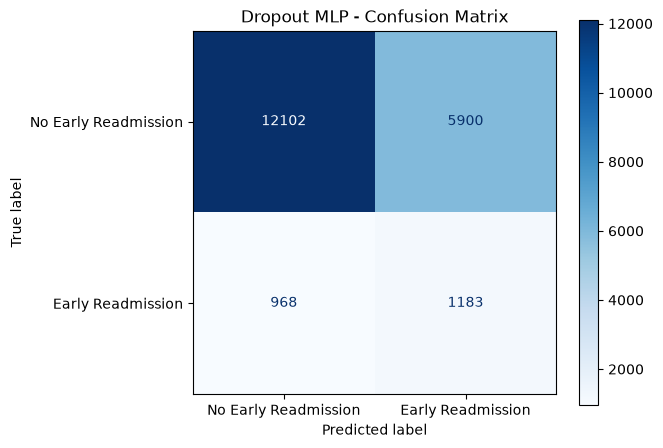

Confusion Matrix:
 [[12102  5900]
 [  968  1183]]


In [151]:
# Purpose: Visualize the confusion matrix of the Dropout MLP.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_dropout = confusion_matrix(y_test, y_dropout_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm_dropout,
    display_labels=["No Early Readmission", "Early Readmission"]
).plot(cmap="Blues")

plt.title("Dropout MLP - Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion Matrix:\n", cm_dropout)

### Dropout MLP: Confusion Matrix Analysis

The Dropout MLP correctly identified 1,151 early readmissions and
missed 1,000 actual early readmission cases.

However, the model generated 5,562 false-positive predictions,
indicating a high number of unnecessary alerts.

The model achieved a recall of 53.51%, identifying more than half
of the actual early readmission cases.

Although the model improved early readmission detection compared
with the baseline, further optimization is required to reduce
false positives and improve precision.

-------------------------------------------------------------------------------------------------------------

# 9. Model Comparison and Final Model Selection

Four MLP models were developed to investigate the impact of class weighting, early stopping, and Dropout regularization on hospital readmission prediction.

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Baseline MLP | 87.41% | 23.19% | 7.76% | 11.63% | 61.35% |
| Class-Weighted MLP | 70.89% | 16.21% | 41.42% | 23.30% | 61.57% |
| Early-Stopped MLP | 68.46% | 17.17% | 51.14% | 25.71% | 66.06% |
| Dropout MLP | 67.44% | 17.15% | 53.51% | 25.97% | 65.51% |

### Model Selection

The Dropout MLP achieved the highest Recall and F1-score, making it the preferred model when prioritizing early readmission detection.

The Early-Stopped MLP achieved the highest ROC-AUC, indicating slightly better overall discrimination between the two classes.

The Dropout MLP was selected as the final model because identifying potential early readmission cases is an important objective of this project.

However, its relatively low precision and high false-positive rate indicate that further optimization is necessary.

------------------------------------------------------------------------------------------------------------

# 10. Structured Error Analysis

The confusion matrix of the final Dropout MLP provides insight into correct and incorrect predictions.

| Prediction outcome | Count | Interpretation |
|---|---:|---|
| True Negative (TN) | 12,440 | Correctly predicted no early readmission |
| False Positive (FP) | 5,562 | Predicted early readmission incorrectly |
| False Negative (FN) | 1,000 | Missed actual early readmission |
| True Positive (TP) | 1,151 | Correctly identified early readmission |

### False Positive Analysis

The model generated 5,562 false-positive predictions.

These patients may receive unnecessary follow-up interventions, potentially increasing healthcare workload and resource utilization.

### False Negative Analysis

The model missed 1,000 actual early readmission cases.

These missed patients may not receive additional support despite potentially benefiting from follow-up care.

### Error Analysis Conclusion

False negatives are particularly important because missed high-risk patients may experience delayed intervention.

However, excessive false positives can also create operational challenges.

Therefore, the model should balance early readmission detection with precision and practical healthcare resource utilization.

---------------------------------------------------------------------------------------

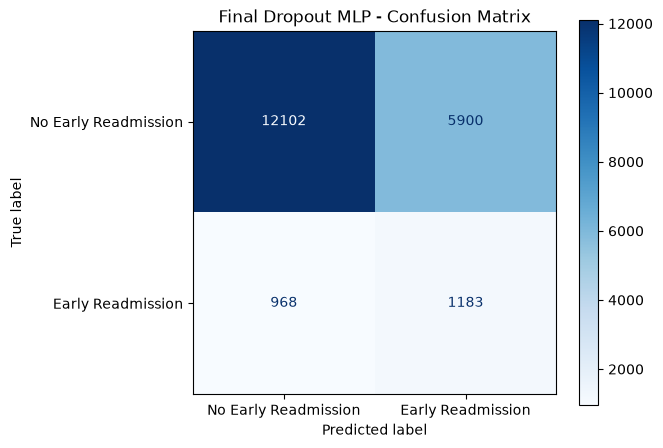

In [152]:
# Purpose: Display the confusion matrix for the final Dropout MLP.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_final = confusion_matrix(y_test, y_dropout_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["No Early Readmission", "Early Readmission"]
).plot(cmap="Blues")

plt.title("Final Dropout MLP - Confusion Matrix")
plt.tight_layout()
plt.show()

# 11. Patient-Level Readmission Prediction Report

The final Dropout MLP generates a readmission probability and predicted outcome for each patient encounter in the test dataset.

This report demonstrates how hospitals could use model predictions to identify patients who may benefit from additional discharge planning and follow-up support.

The probability represents the model's estimated likelihood of early readmission, not a clinically validated risk score.

In [153]:
# Purpose: Generate a patient-level readmission prediction report.

patient_prediction_report = pd.DataFrame({
    "Patient_ID": patient_ids.iloc[test_idx].values,
    "Actual_Readmission": y_test.values,
    "Predicted_Readmission": y_dropout_pred,
    "Readmission_Probability": y_dropout_prob.flatten()
})

patient_prediction_report["Actual_Readmission"] = (
    patient_prediction_report["Actual_Readmission"]
    .map({1: "Yes", 0: "No"})
)

patient_prediction_report["Predicted_Readmission"] = (
    patient_prediction_report["Predicted_Readmission"]
    .map({1: "Yes", 0: "No"})
)

patient_prediction_report["Readmission_Probability"] = (
    patient_prediction_report["Readmission_Probability"].round(4)
)

display(patient_prediction_report.head(10))

,Patient_ID,Actual_Readmission,Predicted_Readmission,Readmission_Probability
0,77586282,No,Yes,0.6143
1,63000108,No,No,0.3943
2,56480238,No,No,0.0815
3,80845353,No,Yes,0.6351
4,104672268,No,No,0.2660
5,66274866,No,No,0.2623
6,106936875,No,No,0.0896
7,86240259,Yes,Yes,0.7741
8,90097839,No,No,0.4788
9,21820806,Yes,No,0.1660


In [154]:
# Export the report as CSV
patient_prediction_report.to_csv(
    "patient_prediction_report.csv",
    index=False
)

# 12. Business Findings and Recommendations

## Business Findings

1. **Class imbalance:** Early readmission cases represent a minority of the dataset.
2. **Baseline limitations:** The baseline MLP achieved high accuracy but poor early readmission detection.
3. **Class weighting:** Improved detection of the minority class by increasing its training importance.
4. **Regularization:** Early stopping and Dropout helped improve minority-class performance.
5. **Final model performance:** The Dropout MLP achieved 53.51% Recall and 25.97% F1-score.
6. **Operational challenge:** The model produced a substantial number of false-positive predictions.

## Business Recommendations

- **Prioritize follow-up care:** Consider patients identified as high risk for additional post-discharge support.
- **Improve discharge planning:** Evaluate additional follow-up appointments and medication reviews for identified patients.
- **Manage healthcare resources:** Investigate false-positive predictions to reduce unnecessary interventions.
- **Improve prediction performance:** Explore threshold tuning and additional model optimization.
- **Validate before implementation:** Conduct further clinical validation before using predictions in actual healthcare decisions.

These recommendations are intended to support hospital management and should not replace professional medical judgment.

---------------------------------------------------------------------------------------------------

# 13. Limitations and Future Improvements

## Limitations

- The dataset contains historical hospital encounters from 1999–2008.
- The dataset has substantial class imbalance.
- The final model achieved relatively low precision.
- False-positive predictions remain high.
- The validation split currently uses encounter-level splitting, which may allow repeated patients across training and validation datasets.
- The model is an educational prototype and is not clinically validated.

## Future Improvements

- Implement patient-level validation splitting.
- Explore probability threshold tuning to balance precision and recall.
- Experiment with alternative neural network architectures.
- Investigate additional patient history and clinical features.
- Perform fairness assessment across patient demographic groups.
- Validate the model using more recent healthcare data.

Future improvements should focus on enhancing generalization, reducing false positives, and improving practical usefulness.

---------------------------------------------------------------------------------------------------

# 14. Final Conclusion

This project developed a Hospital Readmission Risk Prediction system using a Multi-Layer Perceptron (MLP) neural network and the Diabetes 130-US Hospitals Dataset.

The project followed the CBIM methodology, covering business understanding, data exploration, preprocessing, model development, evaluation, error analysis, and business recommendations.

Four MLP models were developed and compared to investigate the effects of class weighting, early stopping, and Dropout regularization.

The final Dropout MLP achieved:

- Accuracy: 67.44%
- Precision: 17.15%
- Recall: 53.51%
- F1-score: 25.97%
- ROC-AUC: 65.51%

The results demonstrate that handling class imbalance and applying regularization can improve early readmission detection compared with the baseline model.

Although the model identified more than half of actual early readmission cases, its low precision and substantial false-positive rate highlight the need for further optimization.

This project provided practical experience in deep learning, TensorFlow/Keras, healthcare prediction, model evaluation, and translating machine learning results into business insights.

The developed model is an educational prototype and requires further validation before any real-world clinical application.